# Asset class allocation with statistical learning

## Get packages and JPMaQS data

### Get packages

In [193]:
# Python packages, modules and functions

import os
import gc
import textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import macrosynergy.management as msm
import macrosynergy.panel as msp
import macrosynergy.signal as mss
import macrosynergy.pnl as msn
import macrosynergy.visuals as msv
import macrosynergy.learning as msl
from sklearn.decomposition import PCA
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import make_scorer
from sklearn.pipeline import Pipeline
from scipy import stats
from macrosynergy.download import JPMaQSDownload
from macrosynergy.management.types import QuantamentalDataFrame
from macrosynergy.visuals.plotter import add_figure_footnote

import warnings
warnings.filterwarnings("ignore")

np.random.seed(42)

In [194]:
# Chart footnotes: what is plotted, then the data source


def show_with_footnote(fig, note, fontsize=10):
    # the note sits just below the lowest tick labels and starts at the chart's left edge
    renderer = fig.canvas.get_renderer()
    boxes = [ax.get_tightbbox(renderer).transformed(fig.transFigure.inverted()) for ax in fig.axes]
    left, bottom = min(b.x0 for b in boxes), min(b.y0 for b in boxes)
    width_chars = int((1 - left) * fig.get_figwidth() * 72 / (0.55 * fontsize))
    text = textwrap.fill(note, width_chars)
    add_figure_footnote(fig, footnote=text, fontsize=fontsize, xpad=left, ypad=bottom - 0.02)
    fig.texts[-1].set_va("top")  # anchor the top of the note, whatever its number of lines
    plt.show()

### Download JPMaQS data

In [195]:
# Parameters for data download

client_id: str = os.getenv("DQ_CLIENT_ID")
client_secret: str = os.getenv("DQ_CLIENT_SECRET")

# the sample starts in 2000
start_date: str = "2000-01-01"
# pinned to the sample of the parent post, "Wealth management with macro factors",
# so the theory-guided figures here are directly comparable with the published ones
end_date: str = "2026-10-31"

In [196]:
# Cross-sectional lists for all asset classes

# For equity indices

cids_eq_dm = ["AUD", "CAD", "CHF", "EUR", "GBP", "JPY", "SEK", "USD"]
cids_eq_dmx = sorted(set(cids_eq_dm) - {"USD"})  # DM ex-US
cids_eq_emas = ["HKD", "INR", "KRW", "MYR", "SGD", "THB", "TWD"]
cids_eq_latm = ["BRL", "MXN"]
cids_eq_emea = ["PLN", "TRY", "ZAR"]
cids_eq_emx = sorted(cids_eq_emas + cids_eq_latm + cids_eq_emea)  # with HKD for download
cids_eq_em = sorted(set(cids_eq_emx + ["CNY"]) - {"HKD"})  # CNY replaces HKD (Hang Seng)
cids_eqx = sorted(cids_eq_dm + cids_eq_emx)  # equity download set (HKD)
cids_eq = sorted(cids_eq_dm + cids_eq_em) # post-rename set (CNY)

# For non-USD government bonds

cids_du_eur = ["DEM", "FRF", "ITL", "ESP"]  # euro countries synthetic EUR
cids_du_xeur = ["AUD", "GBP", "JPY", "NZD"]  # non-euro DM ex-US 
cids_du_dmx = sorted(cids_du_xeur + cids_du_eur)  # countries for download
cids_du_dm = sorted(cids_du_xeur + ["EUR"])  # currency areas for investment

# For FX forwards versus USD

cids_fx_dm = ["AUD", "CAD", "CHF", "EUR", "GBP", "JPY", "NOK", "NZD", "SEK"]
cids_fx_latam = ["BRL", "CLP", "COP", "MXN", "PEN"]
cids_fx_emea = ["CZK", "HUF", "ILS", "PLN", "RON", "TRY", "ZAR"]
cids_fx_emas = ["IDR", "INR", "KRW", "MYR", "PHP", "SGD", "THB", "TWD"]

cids_fx_em = sorted(cids_fx_latam + cids_fx_emea + cids_fx_emas)
cids_fx = sorted(cids_fx_dm + cids_fx_em)

# For CDS indices and sovereign credit

cids_cr_eur = ["EIG", "EHY"]   # EUR-denominated IG/HY (iTraxx)
cids_cr_usd = ["UIG", "UHY"]   # USD-denominated IG/HY (CDX)
cids_cr_dm = cids_cr_eur + cids_cr_usd

cids_latam = ["BRL", "CLP", "COP", "MXN", "PEN"]
cids_emea = ["CZK", "HUF", "PLN", "RON", "TRY", "ZAR"]
cids_asia = ["CNY", "IDR", "INR", "MYR", "PHP"]
cids_cr_em = sorted(cids_latam + cids_emea + cids_asia)  # EM sovereign credit

cids_cr = cids_cr_dm + cids_cr_em  # all sovereign credit

# For EM local currency government bonds (GBI-EM countries in the notebook universe)

cids_lc_latam = ["BRL", "CLP", "COP", "MXN", "PEN"]
cids_lc_emea = ["CZK", "HUF", "PLN", "RON", "TRY", "ZAR"]
cids_lc_asia = ["CNY", "IDR", "MYR", "PHP", "THB"]
cids_lc_em = sorted(cids_lc_latam + cids_lc_emea + cids_lc_asia)

# For commodities

cids_co = ["ALM", "CPR", "LED", "NIC", "TIN", "ZNC", "GLD"]
cids_mtl = sorted(set(cids_co) - {"GLD"})

# All possible cross-sectional identifiers

cids = list(set(cids_eqx + cids_du_dmx + cids_fx + cids_cr + cids_lc_em + cids_co))

# Macro cross-sections
cids_eco = sorted(set(cids_eq) | set(cids_fx) | set(cids_cr_em) | {"EUR", "USD"})
cids_gdm = sorted(set(cids_eq_dm) | {"NOK", "NZD"})
cids_du_fact = cids_du_dm

In [197]:
# Theory-guided categories: downloaded for every cross-section in cids

# Macro

## Demand, output, and labor
growth_m = [
    "INTRGDPv5Y_NSA_P1M1ML12_3MMA",
    "INTRGDP_NSA_P1M1ML12_3MMA",
    "IP_SA_P1M1ML12_3MMA",
    "IP_SA_P6M6ML6AR",
    "RPCONS_SA_P1M1ML12_3MMA",
    "EMPL_NSA_P1M1ML12_3MMA",
    "UNEMPLRATE_NSA_3MMA_D1M1ML12",
    "UNEMPLRATE_SA_3MMAv5YMM",
]

growth_q = [
    "RPCONS_SA_P1Q1QL4",
    "EMPL_NSA_P1Q1QL4",
    "UNEMPLRATE_NSA_D1Q1QL4",
]

growth = growth_m + growth_q

## Survey confidence scores
conf = [
    "MBCSCORE_SA_3MMA",
    "MBCSCORE_SA_D3M3ML3",
    "MBISCORE_SA_D3M3ML3",
    "CBCSCORE_SA_D3M3ML3",
]

## Inflation
infl_m = [
    "CPIH_SA_P1M1ML12",
    "CPIC_SA_P1M1ML12",
    "CPIH_SJA_P6M6ML6AR",
    "CPIC_SJA_P6M6ML6AR",
    "HPI_SA_P1M1ML12_3MMA",
    "INFE5Y_JA",
    "IMPINFB5Y_NSA",
    "IMPINFM5Y_NSA",
    "HHINFESCORE_NSA",
]

infl_q = [
    "CPIH_SA_P1Q1QL4",
    "CPIH_SJA_P2Q2QL2AR",
    "CPIC_SA_P1Q1QL4",
    "CPIC_SJA_P2Q2QL2AR",
    "HPI_SA_P1Q1QL4",
]

infl = infl_m + infl_q

## Financial conditions
fins = [
    "RIR_NSA",
    "RYLDIRS05Y_NSA",
    "DU05YETP_NSA",
    "MNARROW_SJA_P1M1ML12",
    "MBROAD_SJA_P1M1ML12",
    "GGFTGDPRATIO_NSA",
    "GGDGDPRATIO_NSA",
]

## External balances
xbals = [
    "CABGDPRATIO_NSA_12MMA",
    "BXBGDPRATIOE_NSA_12MMA",
    "MTBGDPRATIO_NSA_12MMA_D1M1ML3",
    "MTBGDPRATIO_SA_6MMA_D1M1ML6",
    "NIIPGDP_NSA_D1Mv2YMA",
    "IIPLIABGDP_NSA_D1Mv2YMA",
]

## Terms of trade
tots = [
    "CTOT_NSA_P1W4WL1",
    "CTOT_NSA_P1M1ML12",
    "MTOT_NSA_P1M60ML1",
]

## Real effective exchange rates
reers = [
    "REEROADJ_NSA_P1W4WL1",
]

## Metal inventories
invents = [
    "XINVSCORELME_SA",
    "XINVSCORELME_SA_D3M3ML3",
    "XINVSCORELME_SA_D6M6ML6",
]

## Benchmarks and weights

bws = [
    "RGDP_SA_P1Q1QL4_20QMM",
    "INFTEFF_NSA",
    "WFORCE_NSA_P1Y1YL1_5YMM",
    "USDGDPWGT_SA_3YMA",
    "IVAWGT_SA_3YMA",
    "INFE1Y_JA",
]

macros = growth + conf + infl + fins + xbals + tots + reers + invents + bws

# Markets

## Returns

rets = [
    "EQRUSD_NSA",
    "GB05YXR_NSA",
    "FXXRUSD_NSA",
    "CRXR_NSA",
    "FCBIR_NSA",
    "LCBIXRUSD_NSA",
    "COXR_NSA",
]

## Carry and rates
cris = [
    "EQCRR_VT10",
    "FXCRR_NSA",
    "COCRR_SA",
    "CRCRY_NSA",
    "NIR_NSA",
]

## Credit spreads
spreads = [
    "EMBIGSPRD_NSA",
    "EMBIGSPRD_NSA_LASSO",
]

## FX blacklisting flags
blacks = [
    "FXTARGETED_NSA",
    "FXUNTRADABLE_NSA",
]

marks = rets + cris + spreads + blacks

# All theory-guided categories (the factor universe below adds XCATS_MENU)

xcats = macros + marks

# Factor-universe categories beyond the theory-guided ones: concepts from published Macrosynergy research

# downloaded for every cross-section in cids, like the theory-guided ones

XCATS_MENU = [
    "ACCOUNTABILITY_NSA",
    "ALLIFCDSGDP_NSA",
    "BINVENTORIES_SA_P1M1ML12_3MMA",
    "BINVENTORIES_SA_P3M3ML3AR",
    "BLSCSCORE_NSA",
    "BLSCSCORE_NSA_D2Q2QL2",
    "BLSDSCORE_NSA",
    "BXBGDPRATIO_NSA_12MMAv60MMA",
    "CCSCORE_SA_3MMA",
    "CCSCORE_SA_D3M3ML3",
    "CDS05YSPRD_NSA",
    "CGFREEFLOATDSRATIO_NSA_D3M3ML3",
    "CMPI_NSA_PI",
    "COCRR_SAVT10",
    "COJLCLAIMS_SA_D4W4WL52",
    "CORPINTNETGDP_SA_D1Q1QL4",
    "CORRCONTROL_NSA",
    "CPICGOODS_SA_P1M1ML12",
    "CPIC_SA_P1M1ML12_D1M1ML3",
    "CPIE_SA_P1M1ML12",
    "CPIF_SA_P1M1ML12",
    "CPIH_SA_P1M1ML12_D1M1ML3",
    "CPISERVICES_SA_P1M1ML12",
    "CRESFXGDP_NSA",
    "CRESFXGDP_NSA_D1M1ML1",
    "CRESFXGDP_NSA_D1M1ML3",
    "CRESFXGDP_NSA_D1M1ML6",
    "CSTR_SA_P1M1ML12_3MMA",
    "CXPI_NSA_PI",
    "DCREDITGDP_NSA",
    "DDEBTSECSGDP_NSA",
    "DGORDERS_SA_P3M3ML3AR",
    "DPBCREDITGDP_NSA",
    "DPCREDITGDP_NSA",
    "DU02YYLD_NSA",
    "DU05YCRY_NSA",
    "DU05YCRY_VT10",
    "DU10YYLD_NSA",
    "EQCRR_NSA",
    "EQCRY_NSA",
    "EQCRY_VT10",
    "EXALLOPENNESS_NSA_1YMA",
    "EXPORTS_SA_P1M1ML12_3MMA",
    "EXTERNALRISK_NSA",
    "FCBICRY_NSA",
    "FX01YCRR_VT10",
    "FX06MCRR_VT10",
    "FXCRRHvGDRB_NSA",
    "FXCRR_VT10",
    "FXPPTAILDOWN_NSA",
    "FXPPTAILUP_NSA",
    "FXVRP1M_NSA",
    "FXXRBETAvGDRB_NSA",
    "FXXRUSDxEASD_NSA",
    "GB05YCRY_NSA",
    "GB05YYLD_NSA",
    "GDPPC_SA",
    "GDPPC_SA_P1Qv5YMA",
    "GGDGDPRATIOX10_NSA",
    "GGEGDPRATIO_NSA",
    "GGIFCDSGDP_NSA",
    "GGOBGDPRATIO_NSA",
    "GGRGDPRATIO_NSA",
    "GGSBGDPRATIO_NSA",
    "GNBRGDP_NSA_12MMA",
    "HHCCREDITGDPRATIO_SA_D1Q1QL4",
    "HHINTNETGDP_SA_D1Q1QL4",
    "HHMORTGAGEGDPRATIO_SA_D1Q1QL4",
    "IMPORTS_SA_P1M1ML12_3MMA",
    "IMPORTS_SA_P3M3ML3AR",
    "IMPORTS_SA_P6M6ML6AR",
    "INFE2Y_JA",
    "INFTARGET_NSA",
    "INTLIQGDP_NSA_D1M1ML1",
    "INTLIQGDP_NSA_D1M1ML3",
    "INTLIQGDP_NSA_D1M1ML6",
    "INTRGDP_NSA_P1M1ML12",
    "INTRGDP_NSA_P1M1ML12_D3M3ML3",
    "IRVRP01Y02Y_NSA",
    "IRVRP01Y03Y_NSA",
    "IRVRP01Y05Y_NSA",
    "IRVRP03M02Y_NSA",
    "IRVRP03M03Y_NSA",
    "IRVRP03M05Y_NSA",
    "IRVRP06M02Y_NSA",
    "IRVRP06M03Y_NSA",
    "IRVRP06M05Y_NSA",
    "LCBICRY_NSA",
    "LTFCRATING_NSA",
    "MACROECONRISK_NSA",
    "MBASEGDP_SA_D1M1ML1",
    "MBASEGDP_SA_D1M1ML3",
    "MBASEGDP_SA_D1M1ML6",
    "MBOSCORE_SA_D1M1ML1",
    "MBOSCORE_SA_D3M3ML3",
    "MBOSCORE_SA_D6M6ML6",
    "MTBGDPRATIO_SA_3MMAv120MMA",
    "MTBGDPRATIO_SA_3MMAv60MMA",
    "NETENERGYGDPRATIO_NSA_12MMA",
    "NETGRAINSGDPRATIO_NSA_12MMA",
    "NETIMETALSGDPRATIO_NSA_12MMA",
    "NETLIVESTOCKGDPRATIO_NSA_12MMA",
    "NETPMETALSGDPRATIO_NSA_12MMA",
    "NETSOFTSGDPRATIO_NSA_12MMA",
    "NFDIGDPRATIO_NSA_12MMA",
    "NFLGDPRATIO_NSA",
    "NFPIGDPRATIO_NSA",
    "NIIPGDP_NSA",
    "NRSALES_SA_P1M1ML12_3MMA",
    "PCREDITBN_SJA_P1M1ML12",
    "PCREDITGDP_SA",
    "PCREDITGDP_SJA_D1M1ML12",
    "PGDPTECH_SA_P1M1ML12",
    "PGDPTECH_SA_P1M1ML12_3MMA",
    "POLSTAB_NSA",
    "PPIH_NSA_P1M1ML12",
    "PPPFXOVERVALUE_NSA",
    "PPPFXOVERVALUE_NSA_P1M12ML1",
    "REEROADJ_NSA_P1M12ML1",
    "REEROADJ_NSA_P1M1ML12",
    "REER_NSA_P1M60ML1",
    "REER_NSA_P1W4WL1",
    "RESERVERISK_NSA",
    "RGDPTECH_SA_P1M1ML12_3MMA",
    "RGDPTECH_SA_P1M1ML12_D3M3ML3",
    "RGDPTECHv5Y_SA_P1M1ML12_3MMA",
    "RGDP_SA_P1Q1QL4",
    "RGDP_SA_P1Q1QL4_20QMA",
    "RRSALES_SA_P1M1ML12_3MMA",
    "RYLDIRS02Y_NSA",
    "SBCSCORE_SA_3MMA",
    "SBCSCORE_SA_D3M3ML3",
    "SOVCREDITRATINGRPS_NSA",
    "SOVCREDITRISKSCORE_NSA",
    "SOVCREDITSPREADRPS_NSA",
    "WAGES_NSA_P1M1ML12_3MMA",
    "WFORCE_NSA_P1Y1YL1_5YMA",
    "XBALRISK_NSA",
    "XDEBTRISK_NSA",
    "XGGPBGDPRATIO_NSA",
    "XINVSCORECN_SA",
    "XINVSCOREUS_SA",
    "XLIABRISK_NSA",
]

# categories must not overlap the theory-guided ones, so this block cannot alter a
# theory-guided series
dupes = sorted(set(XCATS_MENU) & set(xcats))
assert not dupes, f"XCATS_MENU categories already downloaded for the theory-guided factors: {dupes}"
print(f"factor-universe registry: {len(XCATS_MENU)} new categories")


factor-universe registry: 143 new categories


In [198]:
# Tickers for download: theory-guided and factor-universe categories over the notebook universe

tickers_base = [cid + "_" + xcat for cid in cids for xcat in xcats]
tickers_menu = [cid + "_" + xcat for cid in cids for xcat in XCATS_MENU]
tickers = tickers_base + tickers_menu  # disjoint: cell above asserts no shared category
print(f"{len(tickers)} tickers: {len(tickers_base)} theory-guided, {len(tickers_menu)} factor universe")

10058 tickers: 3337 theory-guided, 6721 factor universe


In [199]:
# Download JPMaQS data

with JPMaQSDownload(client_id=client_id, client_secret=client_secret) as downloader:
    df = downloader.download(
        tickers=tickers,
        start_date=start_date,
        end_date=end_date,
        metrics=["value"],
        suppress_warning=True,
        show_progress=True,
    )

Timestamp UTC:  2026-11-11 14:42:11
Connection successful!


Requesting data: 100%|██████████| 503/503 [02:08<00:00,  3.93it/s]


Some expressions are missing from the downloaded data. Check logger output for complete list.
4561 out of 10058 expressions are missing. To download the catalogue of all available expressions and filter the unavailable expressions, set `get_catalogue=True` in the call to `JPMaQSDownload.download()`.


In [200]:
# Working copy

dfx = df
dfx.info()

del df
_ = gc.collect()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36146682 entries, 0 to 36146681
Data columns (total 4 columns):
 #   Column     Dtype         
---  ------     -----         
 0   real_date  datetime64[ns]
 1   cid        object        
 2   xcat       object        
 3   value      float64       
dtypes: datetime64[ns](1), float64(1), object(2)
memory usage: 1.1+ GB


## Pre-processing, availability, and blacklisting

### Renaming

In [201]:
# Synthetic China equity: drop the CNY equity, then rename the HKD equity (EQ categories only) to CNY

is_eq = dfx["xcat"].str.startswith("EQ")
dfx = dfx[~(is_eq & (dfx["cid"] == "CNY"))].copy()
is_eq = dfx["xcat"].str.startswith("EQ")
dfx.loc[is_eq & (dfx["cid"] == "HKD"), "cid"] = "CNY"

In [202]:
# Where a country lacks the monthly category, rename the quarterly

dict_repl = {
    "RPCONS_SA_P1Q1QL4": "RPCONS_SA_P1M1ML12_3MMA",
    "EMPL_NSA_P1Q1QL4": "EMPL_NSA_P1M1ML12_3MMA",
    "UNEMPLRATE_NSA_D1Q1QL4": "UNEMPLRATE_NSA_3MMA_D1M1ML12",
    "CPIH_SA_P1Q1QL4": "CPIH_SA_P1M1ML12",
    "CPIH_SJA_P2Q2QL2AR": "CPIH_SJA_P6M6ML6AR",
    "CPIC_SA_P1Q1QL4": "CPIC_SA_P1M1ML12",
    "CPIC_SJA_P2Q2QL2AR": "CPIC_SJA_P6M6ML6AR",
    "HPI_SA_P1Q1QL4": "HPI_SA_P1M1ML12_3MMA",
}
for qcat, mcat in dict_repl.items():
    have_m = set(dfx.loc[dfx["xcat"] == mcat, "cid"].unique())
    mask = (dfx["xcat"] == qcat) & (~dfx["cid"].isin(have_m))
    n = dfx.loc[mask, "cid"].nunique()
    if n:
        print(f"{qcat} -> {mcat}: {n} countries")
    dfx.loc[mask, "xcat"] = mcat

RPCONS_SA_P1Q1QL4 -> RPCONS_SA_P1M1ML12_3MMA: 33 countries
EMPL_NSA_P1Q1QL4 -> EMPL_NSA_P1M1ML12_3MMA: 11 countries
UNEMPLRATE_NSA_D1Q1QL4 -> UNEMPLRATE_NSA_3MMA_D1M1ML12: 4 countries
HPI_SA_P1Q1QL4 -> HPI_SA_P1M1ML12_3MMA: 19 countries


### Synthetic euro-area government bonds

In [203]:
# Market-value weights for the euro members

# GDP weight times the general-government debt-to-GDP ratio

dfa = msp.panel_calculator(dfx, calcs=["DEBTWGT = USDGDPWGT_SA_3YMA * GGDGDPRATIO_NSA"], cids=cids_du_eur)
dfx = msm.update_df(dfx, dfa)

# Market-value-weighted euro-area 5y government bond excess return (synthetic EUR)
dfa = msp.linear_composite(
    df=dfx,
    xcats="GB05YXR_NSA",
    cids=cids_du_eur,
    new_cid="EUR",
    weights="DEBTWGT",
    complete_cids=False,
)
dfx = msm.update_df(dfx, dfa)

### Availability checks

#### Availability of macro categories

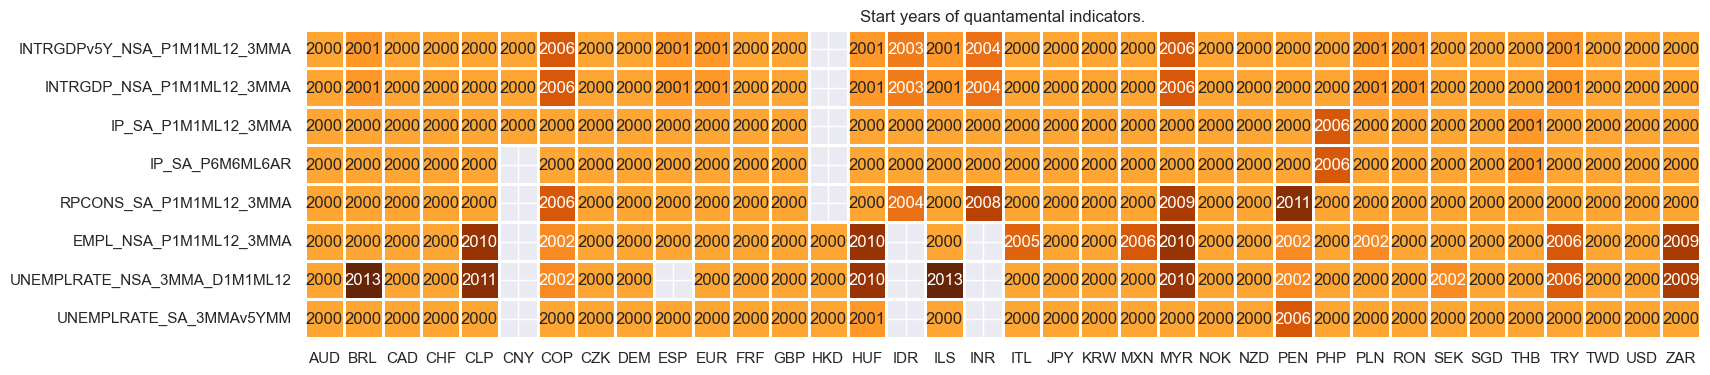

In [204]:
# Demand, output, and labor

cidx = cids
xcatx = growth_m
msm.check_availability(dfx, xcats=xcatx, cids=cidx, missing_recent=False)

#### Availability of market categories

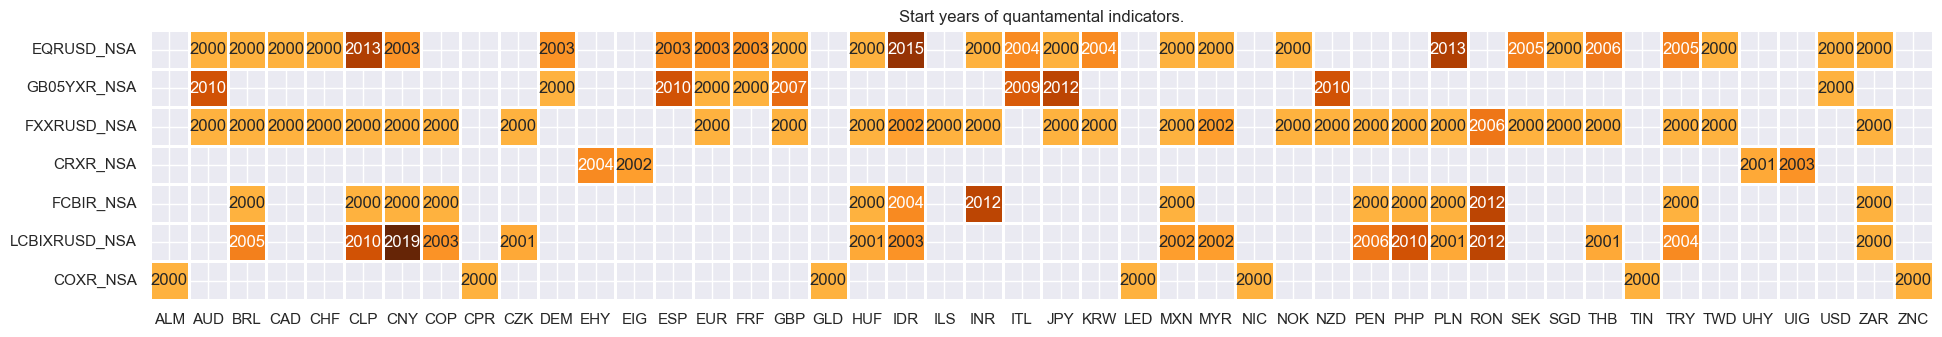

In [205]:
# Returns

cidx = cids
xcatx = rets
msm.check_availability(dfx, xcats=xcatx, cids=cidx, missing_recent=False)

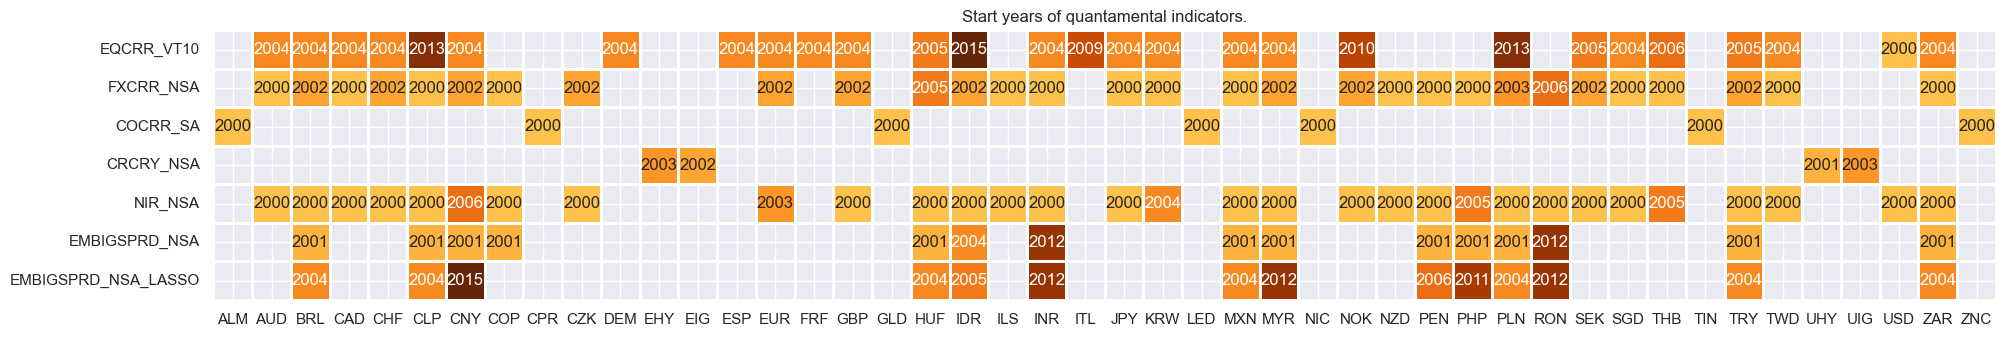

In [206]:
# Carry, rates, and spreads

cidx = cids
xcatx = cris + spreads
msm.check_availability(dfx, xcats=xcatx, cids=cidx, missing_recent=False)

### Blacklisting

In [207]:
# FX blacklist from targeted and untradable flags (used when aggregating FX baskets)

dfb = dfx[dfx["xcat"].isin(["FXTARGETED_NSA", "FXUNTRADABLE_NSA"])].loc[
    :, ["cid", "xcat", "real_date", "value"]
]
dfba = (
    dfb.groupby(["cid", "real_date"])
    .aggregate(value=pd.NamedAgg(column="value", aggfunc="max"))
    .reset_index()
)
dfba["xcat"] = "FXBLACK"
fxblack = msp.make_blacklist(dfba, "FXBLACK")

## Targets

### USD short-term remuneration

In [208]:
# USD short-term cash return: nominal short-term rate over 252 business days

dfa = msp.panel_calculator(dfx, calcs=["USDCASH_NIR = NIR_NSA / 252"], cids=["USD"])
dfx = msm.update_df(dfx, dfa)

# 252 is the day-count JPMaQS uses for its excess returns

### USD excess returns

In [209]:
# USD excess returns by asset class

# USD equity excess returns

dfa = msp.panel_calculator(
    dfx, calcs=["EQXRUSD_NSA = EQRUSD_NSA - iUSD_USDCASH_NIR"], cids=cids_eq
)
dfx = msm.update_df(dfx, dfa)

# DM ex-US bond excess returns: local 5y excess + currency vs USD

dfa = msp.panel_calculator(
    dfx, calcs=["GB05YXRUSD_NSA = GB05YXR_NSA + FXXRUSD_NSA"], cids=cids_du_dm,
)
dfx = msm.update_df(dfx, dfa)

# Synthetic DM credit excess returns in USD
## for USD
dfa = msp.panel_calculator(
    dfx, calcs=["CRR_NSA = CRXR_NSA + iUSD_GB05YXR_NSA"], cids=cids_cr_usd
)
dfx = msm.update_df(dfx, dfa)
## for EUR
dfa = msp.panel_calculator(
    dfx, calcs=["CRR_NSA = CRXR_NSA + iEUR_GB05YXR_NSA + iEUR_FXXRUSD_NSA"], 
    cids=cids_cr_eur,
)
dfx = msm.update_df(dfx, dfa)

# EM sovereign bond (index) excess returns
dfa = msp.panel_calculator(
    dfx, calcs=["FCBIXR_NSA = FCBIR_NSA - iUSD_USDCASH_NIR"], cids=cids_cr_em
)
dfx = msm.update_df(dfx, dfa)

# EM local currency bond (index) excess returns need no construction: LCBIXRUSD_NSA
# is already a USD-converted excess return over USD short-term rates

### Review and rename directional returns

In [210]:
# Equal-weighted asset-class baskets, no volatility targeting

basket_specs = [
    ("USEQ", "EQXRUSD_NSA", ["USD"], None),
    ("DXEQ", "EQXRUSD_NSA", cids_eq_dmx, None),
    ("EMEQ", "EQXRUSD_NSA", cids_eq_em, None),
    ("USDU", "GB05YXR_NSA", ["USD"], None),
    ("DXDU", "GB05YXRUSD_NSA", cids_du_dm, None),
    ("DXFX", "FXXRUSD_NSA", cids_fx_dm, fxblack),
    ("G2CR", "CRR_NSA", cids_cr_dm, None),
    ("EMCR", "FCBIXR_NSA", cids_cr_em, None),
    ("EMLC", "LCBIXRUSD_NSA", cids_lc_em, fxblack),
    ("MTL", "COXR_NSA", cids_mtl, None),
    ("GLD", "COXR_NSA", ["GLD"], None),
]

dfa = pd.DataFrame(columns=list(dfx.columns))
asset_classes = []
for ac_cid, xc, cidx, bl in basket_specs:
    # keep only cross-sections that actually have this return category;
    # passing an absent cid crashes linear_composite's missing-cid handler
    have = set(dfx.loc[dfx["xcat"] == xc, "cid"].unique())
    avail = sorted(set(cidx) & have)
    dropped = sorted(set(cidx) - have)
    if dropped:
        print(f"{ac_cid}: dropping {dropped} (no {xc} data)")
    if not avail:
        print(f"{ac_cid}: skipped, no {xc} data")
        continue
    dfaa = msp.linear_composite(
        df=dfx, xcats=xc, cids=avail, new_cid=ac_cid, complete_cids=False, blacklist=bl,
    )
    if len(cidx) > 2:
        # a multi-country basket begins once at least three constituents are live;
        # a one-country basket would not represent its label
        counts = (
            dfx[(dfx["xcat"] == xc) & (dfx["cid"].isin(avail))]
            .groupby("real_date")["cid"]
            .nunique()
        )
        ok = counts[counts >= 3].index
        trimmed = dfaa[dfaa["real_date"].isin(ok)]
        if len(trimmed) < len(dfaa):
            print(f"{ac_cid}: min-3 guard sets start to {trimmed['real_date'].min().date()}")
        dfaa = trimmed
    dfaa["xcat"] = "XR_NSA"  # common USD excess-return label across buckets
    dfa = msm.update_df(dfa, dfaa)
    asset_classes.append(ac_cid)
dfx = msm.update_df(dfx, dfa)

EMCR: dropping ['CZK', 'MYR'] (no FCBIXR_NSA data)
EMLC: min-3 guard sets start to 2001-01-01


In [211]:
# Asset-class labels

ac_labels = {
    "USEQ": "US equity",
    "DXEQ": "DM equity (ex US)",
    "EMEQ": "EM equity",
    "USDU": "US Treasuries",
    "DXDU": "DM gov. bonds (ex US)",
    "DXFX": "DM FX",
    "G2CR": "DM corporate credit",
    "EMCR": "EM sovereign credit",
    "EMLC": "EM local currency bonds",
    "MTL": "Industrial metals basket",
    "GLD": "Gold future",
    "CASH": "USD short-term deposit"
}

# Tickers and labels for the review charts (one USD excess-return ticker per asset class)
tix = [ac + "_XR_NSA" for ac in asset_classes]
return_labels = {f"{ac}_XR_NSA": lab for ac, lab in ac_labels.items() if ac in asset_classes}

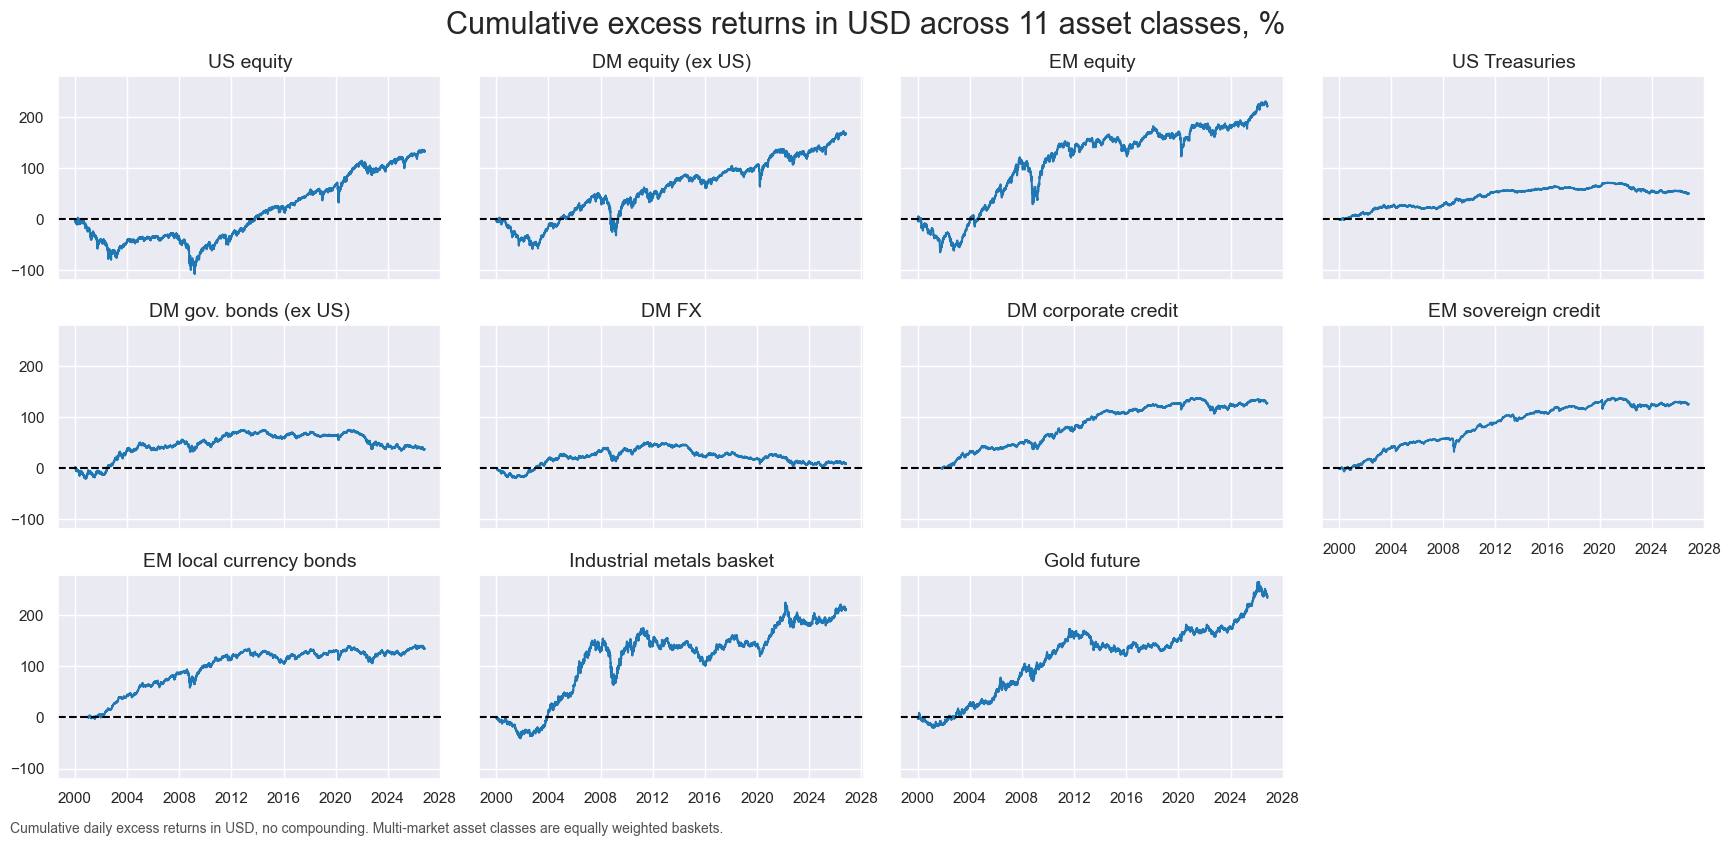

In [212]:
# Cumulative USD excess returns by asset class

fig = msp.view_timelines(
    dfx,
    xcats=["XR_NSA"],
    cids=asset_classes,
    start=start_date,
    title=f"Cumulative excess returns in USD across {len(asset_classes)} asset classes, %",
    cid_labels=ac_labels,
    legend_fontsize=18,
    title_fontsize=22,
    ncol=4,
    same_y=True,
    height=1.8,
    all_xticks=False,
    cumsum=True,
    xcat_grid=False,
    return_fig=True,
)
show_with_footnote(
    fig,
    "Cumulative daily excess returns in USD, no compounding. Multi-market asset classes are equally weighted baskets.",
)

### USD cash returns

In [213]:
# Total return proxies across asset classes

dfa = msp.panel_calculator(dfx, calcs=["TR_NSA = XR_NSA + iUSD_USDCASH_NIR"], cids=asset_classes)
dfx = msm.update_df(dfx, dfa)

dfa = dfx[(dfx["cid"] == "USD") & (dfx["xcat"] == "USDCASH_NIR")].copy()
dfa["cid"] = "CASH"
dfa["xcat"] = "TR_NSA"
dfx = msm.update_df(dfx, dfa)

## Features

### Theory-guided factors for reference


#### Factor calculations

In [214]:
# Composite macro categories

dfx = QuantamentalDataFrame(dfx.astype({"cid": "category", "xcat": "category"}))

dict_avg = {
    "CPIB_PAR": [
        "CPIH_SA_P1M1ML12",
        "CPIC_SA_P1M1ML12",
        "CPIH_SJA_P6M6ML6AR",
        "CPIC_SJA_P6M6ML6AR",
    ],
    "RIRY": ["RIR_NSA", "RYLDIRS05Y_NSA"],
    "MONGROWTH": ["MNARROW_SJA_P1M1ML12", "MBROAD_SJA_P1M1ML12"],
    "XBRATIO": ["CABGDPRATIO_NSA_12MMA", "BXBGDPRATIOE_NSA_12MMA"],
    "XBTREND": ["MTBGDPRATIO_NSA_12MMA_D1M1ML3", "MTBGDPRATIO_SA_6MMA_D1M1ML6"],
}
average_parts = []
for new_xcat, xcat_list in dict_avg.items():
    df_source = dfx.loc[dfx["xcat"].isin(xcat_list)]
    dfa = msp.linear_composite(
        df=df_source, xcats=xcat_list, cids=cids_eco, complete_xcats=False, new_xcat=new_xcat
    )
    average_parts.append(dfa)

dfx = msm.update_df(dfx, QuantamentalDataFrame.from_qdf_list(average_parts))
del average_parts, df_source

In [215]:
# Net investment position strength

xcats_source = ['NIIPGDP_NSA_D1Mv2YMA', 'IIPLIABGDP_NSA_D1Mv2YMA']
df_source = dfx.loc[dfx["xcat"].isin(xcats_source)]
dfa = msp.linear_composite(
    df=df_source,
    xcats=["NIIPGDP_NSA_D1Mv2YMA", "IIPLIABGDP_NSA_D1Mv2YMA"],
    cids=cids_eco,
    signs=[1, -1],
    complete_xcats=False,
    new_xcat="NIIPSTRENGTH",
)
dfx = msm.update_df(dfx, dfa)
del df_source


In [216]:
# Composite terms-of-trade trend

calcs = [
    "CTOT_NSA_P1W4WL1_AR = CTOT_NSA_P1W4WL1 * np.sqrt(24)",
    "CTOT_NSA_P1M1ML12_AR = CTOT_NSA_P1M1ML12",
    "MTOT_NSA_P1M60ML1_AR = MTOT_NSA_P1M60ML1 * np.sqrt(12 / 30)",
]
xcats_source = ['CTOT_NSA_P1W4WL1', 'CTOT_NSA_P1M1ML12', 'MTOT_NSA_P1M60ML1']
df_source = dfx.loc[dfx["xcat"].isin(xcats_source)]
dfa = msp.panel_calculator(df=df_source, calcs=calcs, cids=cids_eco)
dfx = msm.update_df(dfx, dfa)
df_source = dfx.loc[dfx["xcat"].isin([calc.split(" = ")[0] for calc in calcs])]
dfa = msp.linear_composite(
    df=df_source,
    xcats=["CTOT_NSA_P1W4WL1_AR", "CTOT_NSA_P1M1ML12_AR", "MTOT_NSA_P1M60ML1_AR"],
    cids=cids_eco,
    complete_xcats=False,
    new_xcat="TOTTREND",
)
dfx = msm.update_df(dfx, dfa)
del df_source


In [217]:
# Metals inventory change composite (3m/3m and 6m/6m)

xcats_source = ['XINVSCORELME_SA_D3M3ML3', 'XINVSCORELME_SA_D6M6ML6']
df_source = dfx.loc[dfx["xcat"].isin(xcats_source)]
dfa = msp.linear_composite(
    df=df_source,
    xcats=["XINVSCORELME_SA_D3M3ML3", "XINVSCORELME_SA_D6M6ML6"],
    cids=cids_mtl,
    complete_xcats=False,
    new_xcat="XINVSCORELME_D36",
)
dfx = msm.update_df(dfx, dfa)
del df_source


In [218]:
# Excess categories

calcs = [
    "XIP = IP_SA_P1M1ML12_3MMA - RGDP_SA_P1Q1QL4_20QMM",
    "XRPCONS = RPCONS_SA_P1M1ML12_3MMA - RGDP_SA_P1Q1QL4_20QMM",
    "XEMPL = EMPL_NSA_P1M1ML12_3MMA - WFORCE_NSA_P1Y1YL1_5YMM",
    "XCPIB_PAR = CPIB_PAR - INFTEFF_NSA",
    "XHPI = HPI_SA_P1M1ML12_3MMA - INFTEFF_NSA",
    "XINFE5Y = INFE5Y_JA - INFTEFF_NSA",
    "XIMPINFB5Y = IMPINFB5Y_NSA - INFTEFF_NSA",
    "XIMPINFM5Y = IMPINFM5Y_NSA - INFTEFF_NSA",
    "XMONGROWTH = MONGROWTH - INFTEFF_NSA - RGDP_SA_P1Q1QL4_20QMM",
    "IPvUSD = IP_SA_P6M6ML6AR - iUSD_IP_SA_P6M6ML6AR",
    "INTRGDPvUSD = INTRGDP_NSA_P1M1ML12_3MMA - iUSD_INTRGDP_NSA_P1M1ML12_3MMA",
]
xcats_source = ['IP_SA_P1M1ML12_3MMA', 'RGDP_SA_P1Q1QL4_20QMM', 'RPCONS_SA_P1M1ML12_3MMA', 'EMPL_NSA_P1M1ML12_3MMA', 'WFORCE_NSA_P1Y1YL1_5YMM', 'CPIB_PAR', 'INFTEFF_NSA', 'HPI_SA_P1M1ML12_3MMA', 'INFE5Y_JA', 'IMPINFB5Y_NSA', 'IMPINFM5Y_NSA', 'MONGROWTH', 'IP_SA_P6M6ML6AR', 'INTRGDP_NSA_P1M1ML12_3MMA']
df_source = dfx.loc[dfx["xcat"].isin(xcats_source)]
dfa = msp.panel_calculator(df=df_source, calcs=calcs, cids=cids_eco)
dfx = msm.update_df(dfx, dfa)
del df_source


In [219]:
# EM excess spread ratios

calcs = ["SPREADIFFRATIO = ( EMBIGSPRD_NSA - EMBIGSPRD_NSA_LASSO ) / EMBIGSPRD_NSA_LASSO"]
xcats_source = ['EMBIGSPRD_NSA', 'EMBIGSPRD_NSA_LASSO']
df_source = dfx.loc[dfx["xcat"].isin(xcats_source)]
dfa = msp.panel_calculator(df=df_source, calcs=calcs, cids=cids_cr_em)
dfx = msm.update_df(dfx, dfa)
del df_source


In [220]:
# Excess equity carry: vol-targeted carry versus a minimum carry Sharpe of 0.3

calcs = ["XEQCRR_VT10 = EQCRR_VT10 - 3"]
xcats_source = ['EQCRR_VT10']
df_source = dfx.loc[dfx["xcat"].isin(xcats_source)]
dfa = msp.panel_calculator(df=df_source, calcs=calcs, cids=cids_eq)
dfx = msm.update_df(dfx, dfa)
del df_source


In [221]:
# US labor-market tightness composite

labparts = ["XEMPL", "UNEMPLRATE_NSA_3MMA_D1M1ML12", "UNEMPLRATE_SA_3MMAv5YMM"]
score_parts = []
for xc in labparts:
    dfa = msp.make_zn_scores(
        df=dfx.loc[dfx["xcat"] == xc], xcat=xc, cids=["USD"], neutral="zero", thresh=3, est_freq="M", postfix="_ZN",
    )
    score_parts.append(dfa)

df_labor_scores = QuantamentalDataFrame.from_qdf_list(score_parts)

dfa = msp.linear_composite(
    df=df_labor_scores, xcats=[x + "_ZN" for x in labparts], cids=["USD"],
    weights=[0.5, 0.25, 0.25], signs=[1, -1, -1], complete_xcats=False, new_xcat="LABTIGHT",
)
dfx = msm.update_df(dfx, QuantamentalDataFrame.from_qdf_list([df_labor_scores, dfa]))
del score_parts, df_labor_scores

#### Geographic composites

In [222]:
# Aggregate raw factor values across countries before scoring

# GLB is GDP-weighted (industry value added for IP and manufacturing surveys), local
# baskets are equal-weighted over each bucket's tradable constituents, and the FX
# blacklist applies to the FX and duration baskets

GDP_W = "USDGDPWGT_SA_3YMA"
IVA_W = "IVAWGT_SA_3YMA"

# factor xcat -> {geography: (cross-sections, weights, blacklist) or None for direct use}
geo_specs = [
    ("XIP", {"GLB": (cids_eco, IVA_W, None), "USD": None}),
    ("XRPCONS", {"GLB": (cids_eco, GDP_W, None), "DXEQ": (cids_eq_dmx, None, None), "DXDU": (cids_du_fact, None, fxblack), "USD": None}),
    ("INTRGDPv5Y_NSA_P1M1ML12_3MMA", {"GLB": (cids_eco, GDP_W, None), "USD": None}),
    ("MBCSCORE_SA_3MMA", {"GLB": (cids_eco, IVA_W, None)}),
    ("MBCSCORE_SA_D3M3ML3", {"GLB": (cids_eco, IVA_W, None)}),
    ("MBISCORE_SA_D3M3ML3", {"GLB": (cids_eco, IVA_W, None)}),
    ("CBCSCORE_SA_D3M3ML3", {"GLB": (cids_eco, GDP_W, None)}),
    ("XCPIB_PAR", {"DXEQ": (cids_eq_dmx, None, None), "USD": None, "EMLC": (cids_lc_em, None, fxblack)}),
    ("XHPI", {"USD": None, "DXDU": (cids_du_fact, None, fxblack), "DMCR": (["EUR", "USD"], None, None)}),
    ("XINFE5Y", {"GDM": (cids_gdm, GDP_W, None)}),
    ("XIMPINFB5Y", {"GDM": (cids_gdm, GDP_W, None)}),
    ("XIMPINFM5Y", {"GDM": (cids_gdm, GDP_W, None)}),
    ("HHINFESCORE_NSA", {"USD": None}),
    ("RIRY", {"GLB": (cids_eco, GDP_W, None), "USD": None, "EMLC": (cids_lc_em, None, fxblack)}),
    ("DU05YETP_NSA", {"USD": None, "DXDU": (cids_du_fact, None, fxblack)}),
    ("XMONGROWTH", {"GLB": (cids_eco, GDP_W, None), "USD": None, "EMEQ": (cids_eq_em, None, None), "DXDU": (cids_du_fact, None, fxblack)}),
    ("GGFTGDPRATIO_NSA", {"DXDU": (cids_du_fact, None, fxblack), "DMCR": (["EUR", "USD"], None, None)}),
    ("XEQCRR_VT10", {"USD": None, "DXEQ": (cids_eq_dmx, None, None), "EMEQ": (cids_eq_em, None, None), "GLB": (cids_eq, GDP_W, None)}),
    ("FXCRR_NSA", {"DMFX": (cids_fx_dm, None, fxblack), "EMFX": (cids_fx_em, None, fxblack)}),
    ("XBRATIO", {"EMEQ": (cids_eq_em, None, None)}),
    ("XBTREND", {"DXEQ": (cids_eq_dmx, None, None), "DXDU": (cids_du_fact, None, fxblack)}),
    ("NIIPSTRENGTH", {"EMEQ": (cids_eq_em, None, None), "EMCR": (cids_cr_em, None, None)}),
    ("TOTTREND", {"EMFX": (cids_fx_em, None, fxblack), "DXEQ": (cids_eq_dmx, None, None), "EMEQ": (cids_eq_em, None, None)}),
    ("IPvUSD", {"DMFX": (cids_fx_dm, None, fxblack)}),
    ("INTRGDPvUSD", {"EMFX": (cids_fx_em, None, fxblack)}),
    ("REEROADJ_NSA_P1W4WL1", {"EMLC": (cids_lc_em, None, fxblack)}),
    ("SPREADIFFRATIO", {"EMCR": (cids_cr_em, None, None)}),
    ("CRCRY_NSA", {"DMCR": (cids_cr_dm, None, None)}),
    ("XINVSCORELME_SA", {"MTL": (cids_mtl, None, None)}),
    ("XINVSCORELME_D36", {"MTL": (cids_mtl, None, None)}),
    ("COCRR_SA", {"MTL": (cids_mtl, None, None)}),
]

# Each aggregate needs one factor and, when specified, one weight category.

aggregate_xcats = {xcat for xcat, _ in geo_specs} | {GDP_W, IVA_W}
df_aggregate_inputs = dfx.loc[dfx["xcat"].isin(aggregate_xcats)]
dict_aggregate_inputs = {
    xcat: group for xcat, group in df_aggregate_inputs.groupby("xcat", observed=True, sort=False)
}
aggregate_parts = []
dict_facts = {}  # factor xcat -> list of geography cids carrying it
for xcat, geos in geo_specs:
    built = []
    df_factor = dict_aggregate_inputs.get(xcat)
    have = set(df_factor["cid"].unique()) if df_factor is not None else set()
    for geo, spec in geos.items():
        if spec is None:  # the geography's own series is used directly
            built.append(geo)
            continue
        gcids, wgt, blk = spec
        avail = sorted(set(gcids) & have)
        if not avail:
            print(f"{xcat}/{geo}: no data, skipped")
            continue
        df_source = df_factor if wgt is None else QuantamentalDataFrame.from_qdf_list(
            [df_factor.copy(), dict_aggregate_inputs[wgt].copy()]
        )
        dfa = msp.linear_composite(
            df=df_source, xcats=xcat, cids=avail, new_cid=geo,
            weights=wgt, complete_cids=False, blacklist=blk,
        )
        aggregate_parts.append(dfa)
        built.append(geo)
    dict_facts[xcat] = built

# Preserve the original last-write precedence if a specification repeats a ticker.

dfx = msm.update_df(dfx, QuantamentalDataFrame.from_qdf_list(aggregate_parts))
del aggregate_parts, dict_aggregate_inputs, df_aggregate_inputs, df_factor, df_source


#### U.S. directional factors

In [223]:
# USD-direction block: US-minus-global real rates and growth, plus the US basic balance

calcs = [
    "RIRYvGLB = RIRY - iGLB_RIRY",
    "INTRGDPv5YvGLB = INTRGDPv5Y_NSA_P1M1ML12_3MMA - iGLB_INTRGDPv5Y_NSA_P1M1ML12_3MMA",
]
xcats_source = ["RIRY", "INTRGDPv5Y_NSA_P1M1ML12_3MMA"]
df_source = dfx.loc[dfx["xcat"].isin(xcats_source)]
dfa = msp.panel_calculator(df=df_source, calcs=calcs, cids=["USD"])
dfx = msm.update_df(dfx, dfa)

usddir_parts = ["RIRYvGLB", "INTRGDPv5YvGLB", "BXBGDPRATIOE_NSA_12MMA"]
score_parts = []
for xc in usddir_parts:
    dfa = msp.make_zn_scores(
        df=dfx.loc[dfx["xcat"] == xc],
        xcat=xc,
        cids=["USD"],
        neutral="zero",
        thresh=3,
        est_freq="M",
        postfix="_ZN",
    )
    score_parts.append(dfa)

df_usd_scores = QuantamentalDataFrame.from_qdf_list(score_parts)

dfa = msp.linear_composite(
    df=df_usd_scores,
    xcats=[x + "_ZN" for x in usddir_parts],
    cids=["USD"],
    complete_xcats=False,
    new_xcat="USDDIR",
)
dfx = msm.update_df(dfx, QuantamentalDataFrame.from_qdf_list([df_usd_scores, dfa]))
del score_parts, df_usd_scores

dict_facts["USDDIR"] = ["USD"]
dict_facts["LABTIGHT"] = ["USD"]


del df_source

#### Factor scores

In [224]:
# Theory-guided factor scoring

facts = [f"{cid}_{xcat}" for xcat, cidl in dict_facts.items() for cid in cidl]

# Score each factor against its own history.

facts_base = sorted(f"{geo}_{xcat}_ZN" for xcat, geos in dict_facts.items() for geo in geos)
dfxx = msm.reduce_df_by_ticker(dfx, ticks=facts).copy()
dfxx["xcat"] = dfxx["cid"].astype(str) + "_" + dfxx["xcat"].astype(str)
dfxx["cid"] = "XXX"  # generic cid: each factor is scored as a single series

score_parts = []
for fact in sorted(dfxx["xcat"].unique()):
    dfa = msp.make_zn_scores(
        dfxx.loc[dfxx["xcat"] == fact], xcat=fact, cids=["XXX"], neutral="zero", thresh=3,
        est_freq="M", min_obs=5 * 261, pan_weight=0, postfix="_ZN",
    )
    score_parts.append(dfa)

df_factz = QuantamentalDataFrame.from_qdf_list(score_parts)
del score_parts

missing = sorted(set(facts_base) - set(df_factz["xcat"]))
assert not missing, f"registered factors with no score: {missing}"


In [225]:
# Theory-guided score replication and negatives

df_theory_scores = df_factz.loc[df_factz["xcat"].isin(facts_base)]
replicated_parts = []
for ac in asset_classes:
    dfa = df_theory_scores.copy()
    dfa["cid"] = ac
    replicated_parts.append(dfa)
    df_negative = dfa.copy()
    df_negative["value"] = -df_negative["value"]
    df_negative["xcat"] = df_negative["xcat"].astype(str) + "N"
    replicated_parts.append(df_negative)

dfx = msm.update_df(dfx, QuantamentalDataFrame.from_qdf_list(replicated_parts))
del replicated_parts, df_theory_scores, df_negative

# suffix _ZNN is the negative _ZN score


#### Macro themes

In [226]:
# Aggregate factor scores into macro themes

# each theme is a weighted average of factor scores; the themes feed the asset-class composites

theme_defs = {
    # US macro blocks

    "USD_PRODGROWTH": ("US production growth", {
        "USD_INTRGDPv5Y_NSA_P1M1ML12_3MMA_ZN": 1 / 2,
        "USD_XIP_ZN": 1 / 2,
    }),
    "USD_FINEASE": ("US financial ease", {
        "USD_XMONGROWTH_ZN": 1 / 3,
        "USD_RIRY_ZNN": 1 / 3,
        "USD_DU05YETP_NSA_ZNN": 1 / 3,
    }),
    "USD_ECONSTR": ("US economic strength", {
        "USD_LABTIGHT_ZN": 1 / 3,
        "USD_XIP_ZN": 1 / 3,
        "USD_INTRGDPv5Y_NSA_P1M1ML12_3MMA_ZN": 1 / 3,
    }),
    "USD_INFLPRESS": ("US inflation pressure", {
        "USD_XCPIB_PAR_ZN": 1 / 2,
        "USD_HHINFESCORE_NSA_ZN": 1 / 2,
    }),
    "USD_FIPREMIA": ("US fixed income premia", {
        "USD_DU05YETP_NSA_ZN": 1 / 2,
        "USD_RIRY_ZN": 1 / 2,
    }),
    "USD_WEAK": ("US economic weakness", {
        "USD_LABTIGHT_ZNN": 1 / 3,
        "USD_XRPCONS_ZNN": 1 / 3,
        "USD_XCPIB_PAR_ZNN": 1 / 3,
    }),
    "USD_LABTIGHTNESS": ("US labor market tightness", {"USD_LABTIGHT_ZN": 1.0}),
    "USD_CPI": ("US excess inflation", {"USD_XCPIB_PAR_ZN": 1.0}),
    "USD_HOUSING": ("US house price growth", {"USD_XHPI_ZN": 1.0}),
    "USD_REALRATES": ("US real interest rates", {"USD_RIRY_ZN": 1.0}),
    "USD_TERMPREM": ("US term premium", {"USD_DU05YETP_NSA_ZN": 1.0}),
    "USD_MONGROWTH": ("US excess money growth", {"USD_XMONGROWTH_ZN": 1.0}),
    "USD_EQCARRY": ("US equity carry", {"USD_XEQCRR_VT10_ZN": 1.0}),
    "USDDIR": ("USD appreciation pressure", {"USD_USDDIR_ZN": 1.0}),
    
    # Global blocks

    "GLB_CYCLE": ("Global cycle strength", {
        "GLB_MBCSCORE_SA_3MMA_ZN": 1 / 5,
        "GLB_MBCSCORE_SA_D3M3ML3_ZN": 1 / 5,
        "GLB_MBISCORE_SA_D3M3ML3_ZNN": 1 / 5,
        "GLB_XIP_ZN": 1 / 5,
        "GLB_XRPCONS_ZN": 1 / 5,
    }),
    "GLB_MFG": ("Global manufacturing dynamics", {
        "GLB_MBCSCORE_SA_3MMA_ZN": 1 / 2,
        "GLB_MBCSCORE_SA_D3M3ML3_ZN": 1 / 2,
    }),
    "GLB_BUSCONF": ("Global business confidence dynamics", {
        "GLB_MBCSCORE_SA_D3M3ML3_ZN": 1 / 2,
        "GLB_CBCSCORE_SA_D3M3ML3_ZN": 1 / 2,
    }),
    "GLB_CONSTR": ("Global construction and housing", {
        "GLB_CBCSCORE_SA_D3M3ML3_ZN": 1 / 2,
        "DMCR_XHPI_ZN": 1 / 2,
    }),
    "GLB_REALRATES": ("Global real interest rates", {"GLB_RIRY_ZN": 1.0}),
    "GLB_MONGROWTH": ("Global excess money growth", {"GLB_XMONGROWTH_ZN": 1.0}),
    "GLB_INVCYCLE": ("Global inventory dynamics", {"GLB_MBISCORE_SA_D3M3ML3_ZN": 1.0}),
    "GLB_EQCARRY": ("Global equity carry", {"GLB_XEQCRR_VT10_ZN": 1.0}),

    # Inflation expectations blocks

    "GDM_XINFE": ("DM excess inflation expectations", {
        "GDM_XINFE5Y_ZN": 0.5,
        "GDM_XIMPINFB5Y_ZN": 0.25,
        "GDM_XIMPINFM5Y_ZN": 0.25,
    }),
    "INFEXP": ("Inflation expectations, markets and households", {
        "GDM_XINFE5Y_ZN": 0.25,
        "GDM_XIMPINFB5Y_ZN": 0.125,
        "GDM_XIMPINFM5Y_ZN": 0.125,
        "USD_HHINFESCORE_NSA_ZN": 0.5,
    }),

    # DM ex US blocks
    "DXEQ_DEMAND": ("DM ex US demand momentum", {
        "DXEQ_XRPCONS_ZN": 1 / 2,
        "DXEQ_XBTREND_ZNN": 1 / 2,  # deteriorating external balance = strong domestic demand
    }),
    "DXEQ_INFL": ("DM ex US excess inflation", {"DXEQ_XCPIB_PAR_ZN": 1.0}),
    "DXEQ_EQCARRY": ("DM ex US equity carry", {"DXEQ_XEQCRR_VT10_ZN": 1.0}),
    "DXEQ_TOT": ("DM ex US terms-of-trade trend", {"DXEQ_TOTTREND_ZN": 1.0}),
    "DX_TERMPREM": ("DM ex US term premium", {"DXDU_DU05YETP_NSA_ZN": 1.0}),
    "DX_FISCAL": ("DM ex US fiscal thrust", {"DXDU_GGFTGDPRATIO_NSA_ZN": 1.0}),
    "DXDU_XBAL": ("DM ex US external balance trend", {"DXDU_XBTREND_ZN": 1.0}),
    "DXDU_LOCALHEAT": ("DM ex US local overheating", {
        "DXDU_XHPI_ZN": 1 / 2,
        "DXDU_XRPCONS_ZN": 1 / 2,
    }),
    "DXMON": ("Global and DM ex US money growth", {
        "GLB_XMONGROWTH_ZN": 1 / 2,
        "DXDU_XMONGROWTH_ZN": 1 / 2,
    }),
    "DMFX_RELIP": ("DM FX industry growth versus the US", {"DMFX_IPvUSD_ZN": 1.0}),
    "DMFX_CARRY": ("DM FX carry", {"DMFX_FXCRR_NSA_ZN": 1.0}),

    # EM blocks
    "EMEQ_EXTBAL": ("EM external balance strength", {
        "EMEQ_XBRATIO_ZN": 1 / 2,
        "EMEQ_NIIPSTRENGTH_ZN": 1 / 2,
    }),
    "EMEQ_MONEY": ("EM and global money growth", {
        "EMEQ_XMONGROWTH_ZN": 1 / 2,
        "GLB_XMONGROWTH_ZN": 1 / 2,
    }),
    "EMEQ_EQCARRY": ("EM equity carry", {"EMEQ_XEQCRR_VT10_ZN": 1.0}),
    "EMEQ_TOT": ("EM terms-of-trade trend, equity basket", {"EMEQ_TOTTREND_ZN": 1.0}),
    "EMFX_RELGROWTH": ("EM growth versus the US", {"EMFX_INTRGDPvUSD_ZN": 1.0}),
    "EMFX_TOT": ("EM terms-of-trade trend", {"EMFX_TOTTREND_ZN": 1.0}),
    "EMFX_CARRY": ("EM FX carry", {"EMFX_FXCRR_NSA_ZN": 1.0}),
    "EMCR_NIIP": ("EM investment position trend", {"EMCR_NIIPSTRENGTH_ZN": 1.0}),
    "EMCR_XSPREAD": ("EM excess sovereign spreads", {"EMCR_SPREADIFFRATIO_ZN": 1.0}),
    "EMLC_REERAPPR": ("EM openness-adjusted real appreciation", {"EMLC_REEROADJ_NSA_P1W4WL1_ZN": 1.0}),
    "EMLC_INFL": ("EM excess inflation", {"EMLC_XCPIB_PAR_ZN": 1.0}),
    "EMLC_REALRATES": ("EM real interest rates", {"EMLC_RIRY_ZN": 1.0}),

    # Duration and credit blocks

    "G2_TERMPREM": ("G2 term premia", {
        "USD_DU05YETP_NSA_ZN": 1 / 2,
        "DXDU_DU05YETP_NSA_ZN": 1 / 2,
    }),
    "DMCR_FISCAL": ("DM fiscal thrust", {"DMCR_GGFTGDPRATIO_NSA_ZN": 1.0}),
    "DMCR_CARRY": ("DM credit carry", {"DMCR_CRCRY_NSA_ZN": 1.0}),

    # Metals

    "MTL_CARRY": ("Metals carry", {"MTL_COCRR_SA_ZN": 1.0}),
    "MTL_INVSHORT": ("Metals inventory shortage", {
        "MTL_XINVSCORELME_SA_ZNN": 1 / 2,
        "MTL_XINVSCORELME_D36_ZNN": 1 / 2,
    }),
}

theme_inputs = {xcat for _, components in theme_defs.values() for xcat in components}
df_theme_inputs = dfx.loc[dfx["xcat"].isin(theme_inputs)]
theme_parts = []
for theme, (label, comps) in theme_defs.items():
    xcatx = list(comps)
    df_source = df_theme_inputs.loc[df_theme_inputs["xcat"].isin(xcatx)]
    if len(xcatx) == 1:
        # single-factor theme: adopt the factor's score under the theme's name
        dfa = df_source.copy()
        dfa["xcat"] = theme + "_ZN"
    else:
        dfa = msp.linear_composite(
            df=df_source, xcats=xcatx, cids=asset_classes,
            weights=[comps[x] for x in xcatx], new_xcat=theme, complete_xcats=False,
        )
        dfa = msp.make_zn_scores(
            dfa, xcat=theme, cids=asset_classes, neutral="zero", thresh=3,
            est_freq="M", min_obs=5 * 261, pan_weight=0, postfix="_ZN",
        )
    theme_parts.append(dfa)
    dfa = dfa.copy()
    dfa["value"] = -dfa["value"]
    dfa["xcat"] = theme + "_ZNN"
    theme_parts.append(dfa)
dfx = msm.update_df(dfx, QuantamentalDataFrame.from_qdf_list(theme_parts))
del theme_parts, df_theme_inputs, df_source


#### Asset class factor lists

In [227]:
# Composite macro support scores: equal-weighted themes per asset class

dict_buckets = {
    "USEQ": [
        "USD_PRODGROWTH_ZN",
        "USD_FINEASE_ZN",
        "USD_LABTIGHTNESS_ZNN",
        "USD_INFLPRESS_ZNN",
        "GLB_CYCLE_ZN",
    ],
    "DXEQ": [
        "DXEQ_DEMAND_ZN",
        "DXEQ_INFL_ZNN",
        "DX_TERMPREM_ZNN",
        "GLB_CYCLE_ZN",
        "GLB_REALRATES_ZNN",
        "DXEQ_TOT_ZN",
        "USDDIR_ZNN",
    ],
    "EMEQ": [
        "EMEQ_EXTBAL_ZN",
        "EMEQ_MONEY_ZN",
        "EMEQ_TOT_ZN",
        "EMCR_XSPREAD_ZNN",
        "GLB_INVCYCLE_ZNN",
        "USDDIR_ZNN",
    ],
    "USDU": ["USD_FIPREMIA_ZN", "USD_CPI_ZNN", "USD_HOUSING_ZNN", "GLB_CYCLE_ZNN"],
    "DXDU": [
        "DXDU_XBAL_ZN",
        "DXDU_LOCALHEAT_ZNN",
        "DXMON_ZNN",
        "DX_TERMPREM_ZN",
        "GLB_CYCLE_ZNN",
        "USDDIR_ZNN",
        "DMFX_RELIP_ZN",
        "DX_FISCAL_ZN",
        "DMFX_CARRY_ZN",
        "USD_WEAK_ZN",
    ],
    "DXFX": ["DMFX_RELIP_ZN", "DX_FISCAL_ZN", "DMFX_CARRY_ZN", "USD_WEAK_ZN"],
    "G2CR": [
        "G2_TERMPREM_ZN",
        "USD_CPI_ZNN",
        "USD_HOUSING_ZNN",
        "GLB_CYCLE_ZNN",
        "USDDIR_ZNN",
        "DMCR_CARRY_ZN",
        "USD_ECONSTR_ZN",
        "GLB_INVCYCLE_ZNN",
        "GLB_REALRATES_ZNN",
    ],
    "EMCR": [
        "USD_TERMPREM_ZN",
        "USD_REALRATES_ZN",
        "GLB_CYCLE_ZNN",
        "EMCR_NIIP_ZN",
        "EMCR_XSPREAD_ZN",
        "GLB_CONSTR_ZN",
        "GDM_XINFE_ZNN",
        "GLB_INVCYCLE_ZNN",
    ],
    "EMLC": [
        "EMCR_XSPREAD_ZN",
        "EMCR_NIIP_ZN",
        "EMFX_CARRY_ZN",
        "EMFX_TOT_ZN",
        "EMLC_REERAPPR_ZN",
        "EMLC_INFL_ZNN",
        "EMLC_REALRATES_ZN",
        "USD_LABTIGHTNESS_ZNN",
        "GLB_MONGROWTH_ZN",
    ],
    "MTL": [
        "GLB_MFG_ZN",
        "MTL_CARRY_ZN",
        "MTL_INVSHORT_ZN",
        "EMCR_XSPREAD_ZNN",
        "GLB_REALRATES_ZNN",
    ],
    "GLD": ["GLB_BUSCONF_ZNN", "GLB_EQCARRY_ZNN", "USD_MONGROWTH_ZNN", "USD_CPI_ZNN"],
}

theme_ticks = {t + s for t in theme_defs for s in ("_ZN", "_ZNN")}
undeclared = {
    x for xcatx in dict_buckets.values() for x in xcatx if x not in theme_ticks
}
assert (
    not undeclared
), f"bucket entries that are not declared themes: {sorted(undeclared)}"

composite_inputs = {xcat for xcats in dict_buckets.values() for xcat in xcats}
df_composite_inputs = dfx.loc[dfx["xcat"].isin(composite_inputs)]
composite_parts = []
for ac, xcatx in dict_buckets.items():
    df_source = df_composite_inputs.loc[
        df_composite_inputs["xcat"].isin(xcatx) & (df_composite_inputs["cid"] == ac)
    ]
    dfa = msp.linear_composite(
        df=df_source, xcats=xcatx, cids=[ac], new_xcat="COMPOSITE", complete_xcats=False
    )
    composite_parts.append(dfa)

df_composites = QuantamentalDataFrame.from_qdf_list(composite_parts)

dfa = msp.make_zn_scores(
    df=df_composites,
    xcat="COMPOSITE",
    cids=asset_classes,
    neutral="zero",
    thresh=3,
    est_freq="M",
    min_obs=5 * 261,
    pan_weight=0,
    postfix="_ZN",
)
dfx = msm.update_df(dfx, QuantamentalDataFrame.from_qdf_list([df_composites, dfa]))
del composite_parts, df_composites, df_composite_inputs, df_source

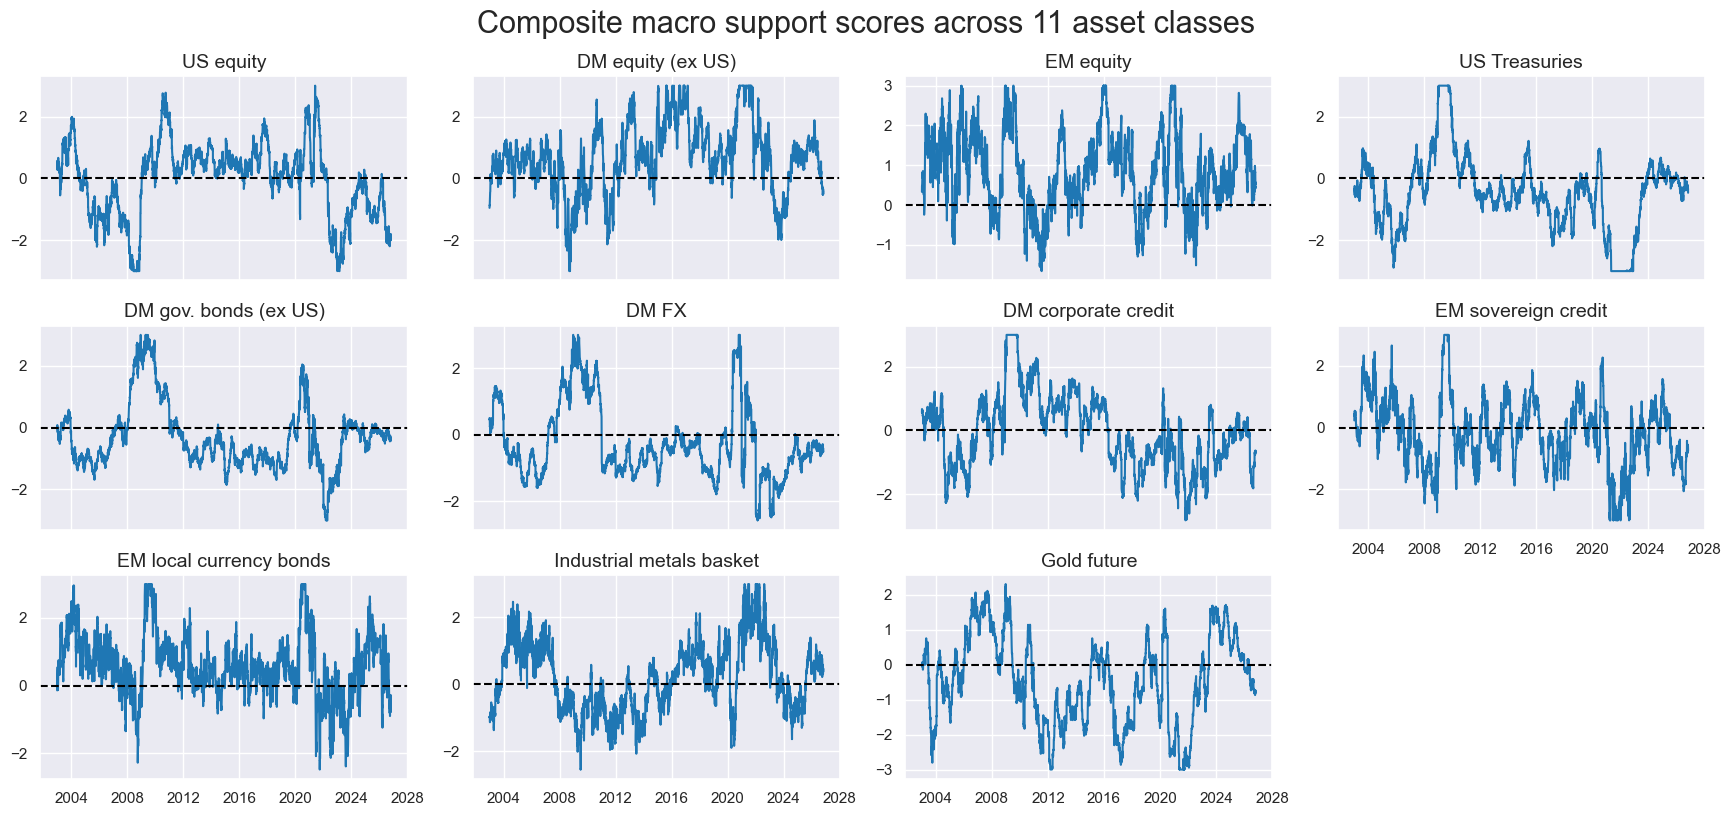

In [228]:
# Composite macro support scores by asset class

msp.view_timelines(
    dfx,
    xcats=["COMPOSITE_ZN"],
    cids=asset_classes,
    start="2003-01-01",  # burn-in: display starts once the z-scores have history
    title=f"Composite macro support scores across {len(asset_classes)} asset classes",
    cid_labels=ac_labels,
    legend_fontsize=18,
    title_fontsize=22,
    height=1.8,
    ncol=4,
    same_y=False,
    size=(12, 12),
    all_xticks=False,
    cumsum=False,
    xcat_grid=False,
)

### Broad factor set for learning


#### Factor universe settings


In [229]:
# Factor universe cross-sections and coverage thresholds

GLB_MIN_CIDS = 5      # minimum cross-sections for a global aggregate
MIN_LIVE_MONTHS = 60  # a scored column needs five years of live score to enter

# the market universe a "market"-domain concept is constructed over; the loop intersects it with the cross-sections the category actually carries
CIDS_MKT_ALL = sorted(
    set(cids_eq) | set(cids_fx) | set(cids_cr) | set(cids_lc_em) | set(cids_co)
)

# construction universes for recipes whose panel is narrower or wider than the generic macro and market universes
CIDS_DM_BROAD = sorted(set(cids_eq_dm) | set(cids_du_dm) | set(cids_fx_dm) | {"NOK", "NZD"})
CIDS_EM_BROAD = sorted(set(cids_eq_em) | set(cids_fx_em) | set(cids_cr_em) | set(cids_lc_em))

# panel lists the source research documents explicitly (wider than DM-broad)
CIDS_BLS = ["CAD", "CZK", "EUR", "GBP", "INR", "JPY", "NOK", "NZD", "PHP", "PLN", "TRY", "USD"]
CIDS_DSR = ["AUD", "CAD", "CHF", "CZK", "EUR", "GBP", "JPY", "KRW", "NOK", "NZD", "PLN", "RON", "USD"]
CIDS_HHFLOW = ["AUD", "CAD", "CHF", "EUR", "GBP", "JPY", "KRW", "NOK", "SEK", "SGD", "USD"]

# base currencies, as in the Macrosynergy FX research notebooks
CIDS_EURBASE = ["CHF", "CZK", "HUF", "NOK", "PLN", "RON", "SEK"]  # trading against EUR
CIDS_EUDBASE = ["GBP", "TRY"]  # trading against EUR and USD

# cids for macro indicators and for market indicators
dict_sleeve_cids = {
    "USEQ": {"macro": ["USD"],        "market": ["USD"]},
    "DXEQ": {"macro": cids_eq_dmx,    "market": cids_eq_dmx},
    "EMEQ": {"macro": cids_eq_em,     "market": cids_eq_em},
    "USDU": {"macro": ["USD"],        "market": ["USD"]},
    "DXDU": {"macro": cids_du_fact,   "market": cids_du_dm},
    "DXFX": {"macro": cids_fx_dm,     "market": cids_fx_dm},
    "G2CR": {"macro": ["EUR", "USD"], "market": cids_cr_dm},
    "EMCR": {"macro": cids_cr_em,     "market": cids_cr_em},
    "EMLC": {"macro": cids_lc_em,     "market": cids_lc_em},
    "MTL":  {"macro": [],             "market": cids_mtl},
    "GLD":  {"macro": [],             "market": ["GLD"]},
}
assert set(dict_sleeve_cids) == set(asset_classes), "sleeve constituent rows do not match the sleeves"

# the blacklist each sleeve's baskets inherit, from basket_specs and from the geo_specs rows that aggregate over the same cross-sections
dict_sleeve_blacklists = {"DXFX": fxblack, "EMLC": fxblack, "DXDU": fxblack}


In [230]:
# Factor definitions

dict_recipes = {}


#### Growth factors


In [231]:
# Growth and demand factor definitions

dict_recipes.update({
    "GDPACCEL": {
        # gdp-growth-acceleration: the 3m/3m change of the nowcast, used raw.
        "inputs": ["INTRGDP_NSA_P1M1ML12_D3M3ML3", "RGDPTECH_SA_P1M1ML12_D3M3ML3"],
        "domain": "macro",
        "family": "growth",
        "concept": "gdp-growth-acceleration",
    },
    "INTRGDPVBM": {
        # gdp-growth-relative-to-base-currency.
        "formula": "INTRGDPVBM = INTRGDP_NSA_P1M1ML12_3MMA - iBM_INTRGDP_NSA_P1M1ML12_3MMA",
        "inputs": ["INTRGDP_NSA_P1M1ML12_3MMA"],
        "domain": "macro",
        "family": "growth",
        "glb_deny": "the legs are benchmark-relative, so the GDP-weighted"
                    " global average is degenerate by construction",
        "concept": "gdp-growth-relative-to-base-currency",
    },
    "GDPSHORTVGLB": {
        # RGDPGROWTHvGLB_NEG of "Cross-country rates relative value with macro factors": both 5-year-excess growth nowcasts, intuitive and technical, relative to the equal-weighted panel, averaged and negated (a shortfall).
        "formula": "GDPSHORTVGLB = -0.5 * ( INTRGDPv5Y_NSA_P1M1ML12_3MMA"
                   " .sub( INTRGDPv5Y_NSA_P1M1ML12_3MMA.mean(axis=1), axis=0 )"
                   " + RGDPTECHv5Y_SA_P1M1ML12_3MMA"
                   " .sub( RGDPTECHv5Y_SA_P1M1ML12_3MMA.mean(axis=1), axis=0 ) )",
        "inputs": ["INTRGDPv5Y_NSA_P1M1ML12_3MMA", "RGDPTECHv5Y_SA_P1M1ML12_3MMA"],
        "domain": "macro",
        "family": "growth",
        "glb_deny": "the legs are cross-country demeaned, so the global"
                    " aggregate is approximately zero",
        "concept": "gdp-growth-relative-to-global-panel",
    },
    "RGDPTREND": {
        # relative-growth-trend-composite: the four base-currency-relative growth variants, equally weighted.
        "formula": "RGDPTREND = ( INTRGDP_NSA_P1M1ML12_3MMA + INTRGDPv5Y_NSA_P1M1ML12_3MMA"
                   " + RGDPTECH_SA_P1M1ML12_3MMA + RGDPTECHv5Y_SA_P1M1ML12_3MMA ) / 4"
                   " - ( iBM_INTRGDP_NSA_P1M1ML12_3MMA + iBM_INTRGDPv5Y_NSA_P1M1ML12_3MMA"
                   " + iBM_RGDPTECH_SA_P1M1ML12_3MMA + iBM_RGDPTECHv5Y_SA_P1M1ML12_3MMA ) / 4",
        "inputs": [
            "INTRGDP_NSA_P1M1ML12_3MMA",
            "INTRGDPv5Y_NSA_P1M1ML12_3MMA",
            "RGDPTECH_SA_P1M1ML12_3MMA",
            "RGDPTECHv5Y_SA_P1M1ML12_3MMA",
        ],
        "domain": "macro",
        "family": "growth",
        "glb_deny": "every leg is base-currency-relative, so a GDP-weighted"
                    " global average of the four relative legs is degenerate",
        "concept": "relative-growth-trend-composite",
    },
    "INTRGDPPG": {
        # potential-growth-composite, primary form INTRGDP_P1M1ML12_3MMAsPG: (growth level + growth versus its own five-year trajectory) / 2, which blends the trend/potential level with the excess.
        "inputs": ["INTRGDP_NSA_P1M1ML12_3MMA", "INTRGDPv5Y_NSA_P1M1ML12_3MMA"],
        "domain": "macro",
        "family": "growth",
        "concept": "potential-growth-composite",
    },
    "XRRSALES": {
        # excess-real-retail-sales: real retail sales growth over the GDP trend.
        "formula": "XRRSALES = RRSALES_SA_P1M1ML12_3MMA - RGDP_SA_P1Q1QL4_20QMA",
        "inputs": ["RRSALES_SA_P1M1ML12_3MMA", "RGDP_SA_P1Q1QL4_20QMA"],
        "domain": "macro",
        "family": "growth",
        "concept": "excess-real-retail-sales",
    },
    "XIMPORTS": {
        # excess-imports: merchandise import growth over the nominal GDP trend, benchmarks exactly as the source states (trend real GDP plus the official target).
        "formula": "XIMPORTS = IMPORTS_SA_P6M6ML6AR - RGDP_SA_P1Q1QL4_20QMA - INFTARGET_NSA",
        "inputs": ["IMPORTS_SA_P6M6ML6AR", "RGDP_SA_P1Q1QL4_20QMA", "INFTARGET_NSA"],
        "domain": "macro",
        "family": "growth",
        "concept": "excess-imports",
    },
    "XIMPORTSV2Y": {
        # excess-imports-vs-nominal-yield: import growth less the 2-year NOMINAL yield, which the source builds as the real swap yield plus the 2-year inflation expectation.
        "formula": "XIMPORTSV2Y = ( IMPORTS_SA_P3M3ML3AR + IMPORTS_SA_P6M6ML6AR"
                   " + IMPORTS_SA_P1M1ML12_3MMA ) / 3 - RYLDIRS02Y_NSA - INFE2Y_JA",
        "inputs": [
            "IMPORTS_SA_P3M3ML3AR",
            "IMPORTS_SA_P6M6ML6AR",
            "IMPORTS_SA_P1M1ML12_3MMA",
            "RYLDIRS02Y_NSA",
            "INFE2Y_JA",
        ],
        "domain": "macro",
        "family": "growth",
        "concept": "excess-imports-vs-nominal-yield",
    },
})


In [232]:
# Construction and confidence factor definitions

dict_recipes.update({
    "XCSTR": {
        # excess-construction-activity: construction output growth over the GDP trend.
        "formula": "XCSTR = CSTR_SA_P1M1ML12_3MMA - RGDP_SA_P1Q1QL4_20QMM",
        "inputs": ["CSTR_SA_P1M1ML12_3MMA", "RGDP_SA_P1Q1QL4_20QMM"],
        "domain": "macro",
        "family": "growth",
        "concept": "excess-construction-activity",
    },
    "XDEMAND": {
        # aggregate-demand-composite: the equal average of four demand sub-scores (growth, retail sales, credit, imports), each the equal average of its own legs.
        "formula": "XDEMAND = ( ( INTRGDPv5Y_NSA_P1M1ML12_3MMA + RGDPTECHv5Y_SA_P1M1ML12_3MMA ) / 2"
                   " + ( NRSALES_SA_P1M1ML12_3MMA - INFTARGET_NSA - RGDP_SA_P1Q1QL4_20QMA"
                   " + RRSALES_SA_P1M1ML12_3MMA - RGDP_SA_P1Q1QL4_20QMA ) / 2"
                   " + ( PCREDITBN_SJA_P1M1ML12 - INFTARGET_NSA - RGDP_SA_P1Q1QL4_20QMA"
                   " + PCREDITGDP_SJA_D1M1ML12"
                   " - PCREDITGDP_SA * ( INFTARGET_NSA + RGDP_SA_P1Q1QL4_20QMA ) / 100 ) / 2"
                   " + ( IMPORTS_SA_P6M6ML6AR + IMPORTS_SA_P1M1ML12_3MMA"
                   " - 2 * INFTARGET_NSA - 2 * RGDP_SA_P1Q1QL4_20QMA ) / 2 ) / 4",
        "inputs": [
            "INTRGDPv5Y_NSA_P1M1ML12_3MMA",
            "RGDPTECHv5Y_SA_P1M1ML12_3MMA",
            "NRSALES_SA_P1M1ML12_3MMA",
            "RRSALES_SA_P1M1ML12_3MMA",
            "PCREDITBN_SJA_P1M1ML12",
            "PCREDITGDP_SJA_D1M1ML12",
            "PCREDITGDP_SA",
            "IMPORTS_SA_P6M6ML6AR",
            "IMPORTS_SA_P1M1ML12_3MMA",
            "INFTARGET_NSA",
            "RGDP_SA_P1Q1QL4_20QMA",
        ],
        "domain": "macro",
        "family": "growth",
        "concept": "aggregate-demand-composite",
    },
    "MBOSCHG": {
        # manufacturing-orders-confidence: the change of the manufacturing orders survey score.
        "inputs": ["MBOSCORE_SA_D1M1ML1", "MBOSCORE_SA_D3M3ML3", "MBOSCORE_SA_D6M6ML6"],
        "domain": "macro",
        "family": "growth",
        "concept": "manufacturing-orders-confidence",
    },
    "SBCSCLVL": {
        # services-confidence, level leg.
        "formula": "SBCSCLVL = SBCSCORE_SA_3MMA",
        "inputs": ["SBCSCORE_SA_3MMA"],
        "domain": "macro",
        "family": "growth",
        "concept": "services-confidence",
    },
    "SBCSCCHG": {
        # services-confidence, change leg.
        "formula": "SBCSCCHG = SBCSCORE_SA_D3M3ML3",
        "inputs": ["SBCSCORE_SA_D3M3ML3"],
        "domain": "macro",
        "family": "growth",
        "concept": "services-confidence",
    },
    "CCSCLVL": {
        # consumer-confidence, level leg.
        "formula": "CCSCLVL = CCSCORE_SA_3MMA",
        "inputs": ["CCSCORE_SA_3MMA"],
        "domain": "macro",
        "family": "growth",
        "concept": "consumer-confidence",
    },
    "CCSCCHG": {
        # consumer-confidence, change leg.
        "formula": "CCSCCHG = CCSCORE_SA_D3M3ML3",
        "inputs": ["CCSCORE_SA_D3M3ML3"],
        "domain": "macro",
        "family": "growth",
        "concept": "consumer-confidence",
    },
    "CONFLEVEL": {
        # economic-confidence-composite, level form: the equal average of the consumer, services and manufacturing confidence levels, the source's own CONFLEVEL.
        "inputs": ["CCSCORE_SA_3MMA", "SBCSCORE_SA_3MMA", "MBCSCORE_SA_3MMA"],
        "domain": "macro",
        "family": "growth",
        "concept": "economic-confidence-composite",
    },
    "CONFCHANGE": {
        # economic-confidence-composite, change form: the matching 3m/3m changes, the source's own CONFCHANGE.
        "inputs": ["CCSCORE_SA_D3M3ML3", "SBCSCORE_SA_D3M3ML3", "MBCSCORE_SA_D3M3ML3"],
        "domain": "macro",
        "family": "growth",
        "concept": "economic-confidence-composite",
    },
})


In [233]:
# Growth risk and inventory factor definitions

dict_recipes.update({
    "XGHI": {
        # growth-inflation-pressure-composite, primary form XGHI: excess growth and excess headline inflation, equally weighted, both percentage points.
        "formula": "XGHI = ( INTRGDPv5Y_NSA_P1M1ML12_3MMA"
                   " + CPIH_SJA_P6M6ML6AR - INFTEFF_NSA ) / 2",
        "inputs": ["INTRGDPv5Y_NSA_P1M1ML12_3MMA", "CPIH_SJA_P6M6ML6AR", "INFTEFF_NSA"],
        "domain": "macro",
        "family": "growth",
        "concept": "growth-inflation-pressure-composite",
    },
    "OVERHEAT": {
        # overheating-composite (OVERHEAT_CS): four equally weighted legs, growth, labor tightness, excess inflation scaled by the target (floored at 2), and excess credit.

        # Labor tightness is employment growth over its own median, less the unemployment gap; the source takes the full-sample median, here it is the expanding median (two years minimum) so the leg is point in time.
        "formula": "OVERHEAT = ( INTRGDPv5Y_NSA_P1M1ML12_3MMA"
                   " + ( EMPL_NSA_P1M1ML12_3MMA - EMPL_NSA_P1M1ML12_3MMA.expanding(522).median()"
                   " - UNEMPLRATE_SA_3MMAv5YMM ) / 2"
                   " + ( CPIH_SJA_P6M6ML6AR - INFTEFF_NSA ) / INFTEFF_NSA.clip(lower=2)"
                   " + PCREDITBN_SJA_P1M1ML12 - INFTEFF_NSA - RGDP_SA_P1Q1QL4_20QMM ) / 4",
        "inputs": [
            "INTRGDPv5Y_NSA_P1M1ML12_3MMA",
            "EMPL_NSA_P1M1ML12_3MMA",
            "UNEMPLRATE_SA_3MMAv5YMM",
            "CPIH_SJA_P6M6ML6AR",
            "INFTEFF_NSA",
            "PCREDITBN_SJA_P1M1ML12",
            "RGDP_SA_P1Q1QL4_20QMM",
        ],
        "domain": "macro",
        "family": "growth",
        "concept": "overheating-composite",
    },
    "EMGROWRISK": {
        # em-growth-risk-score (GROWTHRISK): minus the equally weighted average of realized quarterly GDP growth and its 20-quarter trend, so a high value is growth risk.
        "inputs": ["RGDP_SA_P1Q1QL4_20QMA", "RGDP_SA_P1Q1QL4"],
        "signs": [-1, -1],
        "cids": CIDS_EM_BROAD, "domain": "macro",
        "family": "growth",
        "concept": "em-growth-risk-score",
    },
    "GDPPCLVL": {
        # gdp-per-capita, level leg: USD GDP per capita.
        "formula": "GDPPCLVL = GDPPC_SA",
        "inputs": ["GDPPC_SA"],
        "domain": "macro",
        "family": "growth",
        "concept": "gdp-per-capita",
    },
    "GDPPCGAP": {
        # gdp-per-capita, gap leg: the latest quarter against its own five-year moving average.
        "formula": "GDPPCGAP = GDPPC_SA_P1Qv5YMA",
        "inputs": ["GDPPC_SA_P1Qv5YMA"],
        "domain": "macro",
        "family": "growth",
        "concept": "gdp-per-capita",
    },
    "USBINVGROW": {
        # US business inventory growth, used directly and scored against zero below.
        "formula": "USBINVGROW = BINVENTORIES_SA_P1M1ML12_3MMA",
        "inputs": ["BINVENTORIES_SA_P1M1ML12_3MMA"],
        "cids": ["USD"], "domain": "macro",
        "family": "growth",
        "glb_deny": "US-only coverage is one macro cross-section, below the"
                    " five-cid floor",
        "concept": "us-inventory-and-orders-cycle",
    },
    "USINVORD": {
        # us-inventory-and-orders-cycle, short-term cycle leg (IOST_ZC): the equal average of short-term inventory growth and durable goods orders, both annualized 3m/3m rates.
        "inputs": ["BINVENTORIES_SA_P3M3ML3AR", "DGORDERS_SA_P3M3ML3AR"],
        "cids": ["USD"], "domain": "macro",
        "family": "growth",
        "glb_deny": "US-only coverage is one macro cross-section, below the"
                    " five-cid floor",
        "concept": "us-inventory-and-orders-cycle",
    },
})


#### Labor market factors


In [234]:
# Labor market factor definitions

dict_recipes.update({
    "LABSLACK": {
        # labor-market-slack-composite (LABSLACK_CZS): the equal average of negated excess employment growth, negated excess wage growth and the unemployment gap, so a high value is slack.
        "formula": "LABSLACK = ( ( WFORCE_NSA_P1Y1YL1_5YMM - EMPL_NSA_P1M1ML12_3MMA )"
                   " + ( RGDP_SA_P1Q1QL4_20QMM - WFORCE_NSA_P1Y1YL1_5YMM"
                   " + INFTEFF_NSA - WAGES_NSA_P1M1ML12_3MMA )"
                   " + UNEMPLRATE_SA_3MMAv5YMM ) / 3",
        "inputs": [
            "EMPL_NSA_P1M1ML12_3MMA",
            "WFORCE_NSA_P1Y1YL1_5YMM",
            "WAGES_NSA_P1M1ML12_3MMA",
            "RGDP_SA_P1Q1QL4_20QMM",
            "INFTEFF_NSA",
            "UNEMPLRATE_SA_3MMAv5YMM",
        ],
        "domain": "macro",
        "family": "labor",
        "concept": "labor-market-slack-composite",
    },
    "XWAGES": {
        # excess-wage-growth: wages less the labor productivity trend (LPGT, trend GDP growth less trend workforce growth) less the effective inflation target.
        "formula": "XWAGES = WAGES_NSA_P1M1ML12_3MMA"
                   " - ( RGDP_SA_P1Q1QL4_20QMM - WFORCE_NSA_P1Y1YL1_5YMM ) - INFTEFF_NSA",
        "inputs": [
            "WAGES_NSA_P1M1ML12_3MMA",
            "RGDP_SA_P1Q1QL4_20QMM",
            "WFORCE_NSA_P1Y1YL1_5YMM",
            "INFTEFF_NSA",
        ],
        "domain": "macro",
        "family": "labor",
        "concept": "excess-wage-growth",
    },
    "USCLAIMS4W": {
        # us-jobless-claims: continuing claims, four-week over four-week a year ago, used raw as the source's primary form.
        "formula": "USCLAIMS4W = COJLCLAIMS_SA_D4W4WL52",
        "inputs": ["COJLCLAIMS_SA_D4W4WL52"],
        "cids": ["USD"], "domain": "macro",
        "family": "labor",
        "glb_deny": "US-only coverage is one macro cross-section, below the"
                    " five-cid floor",
        "concept": "us-jobless-claims",
    },
})


#### Inflation factors


In [235]:
# Inflation factor definitions

dict_recipes.update({
    "CPIACCEL": {
        "inputs": ["CPIH_SA_P1M1ML12_D1M1ML3", "CPIC_SA_P1M1ML12_D1M1ML3"],
        "domain": "macro",
        "family": "inflation",
        "concept": "inflation-acceleration",
    },
    "XCPIE": {
        "formula": "XCPIE = CPIE_SA_P1M1ML12 - INFTEFF_NSA",
        "inputs": ["CPIE_SA_P1M1ML12", "INFTEFF_NSA"],
        "domain": "macro",
        "family": "inflation",
        "concept": "excess-energy-cpi",
    },
    "XCPIF": {
        "formula": "XCPIF = CPIF_SA_P1M1ML12 - INFTEFF_NSA",
        "inputs": ["CPIF_SA_P1M1ML12", "INFTEFF_NSA"],
        "domain": "macro",
        "family": "inflation",
        "concept": "excess-food-cpi",
    },
    "XCPICGOODS": {
        "formula": "XCPICGOODS = CPICGOODS_SA_P1M1ML12 - INFTEFF_NSA",
        "inputs": ["CPICGOODS_SA_P1M1ML12", "INFTEFF_NSA"],
        "domain": "macro",
        "family": "inflation",
        "concept": "excess-goods-services-cpi",
    },
    "XCPISERV": {
        "formula": "XCPISERV = CPISERVICES_SA_P1M1ML12 - INFTEFF_NSA",
        "inputs": ["CPISERVICES_SA_P1M1ML12", "INFTEFF_NSA"],
        "domain": "macro",
        "family": "inflation",
        "concept": "excess-goods-services-cpi",
    },
    "XPPIH": {
        "formula": "XPPIH = PPIH_NSA_P1M1ML12 - INFTEFF_NSA",
        "inputs": ["PPIH_NSA_P1M1ML12", "INFTEFF_NSA"],
        "domain": "macro",
        "family": "inflation",
        "concept": "excess-ppi",
    },
    "XPGDPTECH": {
        "formula": "XPGDPTECH = ( PGDPTECH_SA_P1M1ML12_3MMA - INFTEFF_NSA )"
                   " / INFTEFF_NSA.clip(lower=2)",
        "inputs": ["PGDPTECH_SA_P1M1ML12_3MMA", "INFTEFF_NSA"],
        "domain": "macro",
        "family": "inflation",
        "concept": "excess-gdp-deflator-nowcast",
    },
    "XCPIVBM": {
        "formula": "XCPIVBM = XCPIB_PAR - iBM_XCPIB_PAR",
        "inputs": ["XCPIB_PAR"],
        "domain": "macro",
        "family": "inflation",
        "glb_deny": "an anchor-relative leg in the style of vUSD or vEUR, whose"
                    " GDP-weighted global average is degenerate by construction",
        "concept": "relative-inflation-vs-benchmark-currency",
    },
    "EMINFLRISK": {
        "formula": "EMINFLRISK = ( np.sqrt( np.abs( CPIH_SA_P1M1ML12 - 2 ) )"
                   " + np.sqrt( np.abs( CPIC_SA_P1M1ML12 - 2 ) ) ) / 2",
        "inputs": ["CPIH_SA_P1M1ML12", "CPIC_SA_P1M1ML12"],
        "cids": CIDS_EM_BROAD, "domain": "macro",
        "family": "inflation",
        "concept": "em-inflation-risk-score",
    },
})


#### Money and credit factors


In [236]:
# Money and credit factor definitions

dict_recipes.update({
    "XPCREDITGDP": {
        "formula": "XPCREDITGDP = PCREDITGDP_SJA_D1M1ML12 - PCREDITGDP_SA"
                   " * ( INFTARGET_NSA + RGDP_SA_P1Q1QL4_20QMA ) / 100",
        "inputs": ["PCREDITGDP_SJA_D1M1ML12", "PCREDITGDP_SA", "INFTARGET_NSA",
                   "RGDP_SA_P1Q1QL4_20QMA"],
        "domain": "macro",
        "family": "money-credit",
        "concept": "excess-credit-to-gdp-expansion",
    },
    "XFINEXP": {
        "formula": "XFINEXP = ( PCREDITBN_SJA_P1M1ML12 + HPI_SA_P1M1ML12_3MMA )"
                   " / 2 - INFTEFF_NSA - RGDP_SA_P1Q1QL4_20QMM",
        "inputs": ["PCREDITBN_SJA_P1M1ML12", "HPI_SA_P1M1ML12_3MMA",
                   "INFTEFF_NSA", "RGDP_SA_P1Q1QL4_20QMM"],
        "domain": "macro",
        "family": "money-credit",
        "concept": "excess-financial-expansion-composite",
    },
    "INTLIQDAR": {
        "formula": "INTLIQDAR = ( INTLIQGDP_NSA_D1M1ML1 * 12"
                   " + INTLIQGDP_NSA_D1M1ML3 * 4"
                   " + INTLIQGDP_NSA_D1M1ML6 * 2 ) / 3",
        "inputs": ["INTLIQGDP_NSA_D1M1ML1", "INTLIQGDP_NSA_D1M1ML3",
                   "INTLIQGDP_NSA_D1M1ML6"],
        "domain": "macro",
        "family": "money-credit",
        "concept": "intervention-liquidity-expansion",
    },
    "MBASEDAR": {
        "formula": "MBASEDAR = ( MBASEGDP_SA_D1M1ML1 * 12"
                   " + MBASEGDP_SA_D1M1ML3 * 4"
                   " + MBASEGDP_SA_D1M1ML6 * 2 ) / 3",
        "inputs": ["MBASEGDP_SA_D1M1ML1", "MBASEGDP_SA_D1M1ML3",
                   "MBASEGDP_SA_D1M1ML6"],
        "domain": "macro",
        "family": "money-credit",
        "concept": "monetary-base-expansion",
    },
    "CRESFXDAR": {
        "formula": "CRESFXDAR = ( CRESFXGDP_NSA_D1M1ML1 * 12"
                   " + CRESFXGDP_NSA_D1M1ML3 * 4"
                   " + CRESFXGDP_NSA_D1M1ML6 * 2 ) / 3",
        "inputs": ["CRESFXGDP_NSA_D1M1ML1", "CRESFXGDP_NSA_D1M1ML3",
                   "CRESFXGDP_NSA_D1M1ML6"],
        "domain": "macro",
        "family": "money-credit",
        "concept": "fx-reserve-expansion",
    },
    "HHDSRNET": {
        "formula": "HHDSRNET = HHINTNETGDP_SA_D1Q1QL4",
        "inputs": ["HHINTNETGDP_SA_D1Q1QL4"],
        "cids": CIDS_DSR, "domain": "macro",
        "family": "money-credit",
        "concept": "household-debt-servicing",
    },
    "CORPDSRNET": {
        "formula": "CORPDSRNET = CORPINTNETGDP_SA_D1Q1QL4",
        "inputs": ["CORPINTNETGDP_SA_D1Q1QL4"],
        "cids": CIDS_DSR, "domain": "macro",
        "family": "money-credit",
        "concept": "corporate-debt-servicing",
    },
    "BLSDEMAND": {
        "formula": "BLSDEMAND = BLSDSCORE_NSA",
        "inputs": ["BLSDSCORE_NSA"],
        "cids": CIDS_BLS, "domain": "macro",
        "family": "money-credit",
        "concept": "bank-lending-survey-scores",
    },
    "BLSSUPPLY": {
        "inputs": ["BLSCSCORE_NSA", "BLSCSCORE_NSA_D2Q2QL2"],
        "cids": CIDS_BLS, "domain": "macro",
        "family": "money-credit",
        "concept": "bank-lending-survey-scores",
    },
    "HHMORTFLOW": {
        "formula": "HHMORTFLOW = HHMORTGAGEGDPRATIO_SA_D1Q1QL4",
        "inputs": ["HHMORTGAGEGDPRATIO_SA_D1Q1QL4"],
        "cids": CIDS_HHFLOW, "domain": "macro",
        "family": "money-credit",
        "concept": "household-mortgage-credit-flow",
    },
    "HHCCREDFLOW": {
        "formula": "HHCCREDFLOW = HHCCREDITGDPRATIO_SA_D1Q1QL4",
        "inputs": ["HHCCREDITGDPRATIO_SA_D1Q1QL4"],
        "cids": CIDS_HHFLOW, "domain": "macro",
        "family": "money-credit",
        "concept": "household-mortgage-credit-flow",
    },
    "DCREDITDEPTH": {
        # domestic credit to GDP; the source examines four nested ratios (total, private, private bank, debt securities) separately and never averages them, so the broadest is used.
        "formula": "DCREDITDEPTH = DCREDITGDP_NSA",
        "inputs": ["DCREDITGDP_NSA"],
        "domain": "macro",
        "family": "money-credit",
        "concept": "domestic-credit-depth",
    },
})


#### External balances factors


In [237]:
# External balance and debt factor definitions

dict_recipes.update({
    "XEXPORTS": {
        "formula": "XEXPORTS = EXPORTS_SA_P1M1ML12_3MMA - RGDP_SA_P1Q1QL4_20QMM - INFTEFF_NSA",
        "inputs": ["EXPORTS_SA_P1M1ML12_3MMA", "RGDP_SA_P1Q1QL4_20QMM", "INFTEFF_NSA"],
        "domain": "macro",
        "family": "external",
        "concept": "excess-exports",
    },
    "XBLONGAVG": {
        # XBTREND_AVG of "FX trends and external balance headwinds": equal thirds of the basic-balance 1y-vs-5y deviation and the two merchandise 3m-vs-5y and 3m-vs-10y deviations.
        "inputs": [
            "BXBGDPRATIO_NSA_12MMAv60MMA",
            "MTBGDPRATIO_SA_3MMAv60MMA",
            "MTBGDPRATIO_SA_3MMAv120MMA",
        ],
        "domain": "macro",
        "family": "external",
        "glb_deny": "trade and current-account balance ratios are near-zero-sum"
                    " across a world-spanning panel, so the GDP-weighted aggregate carries"
                    " no information",
        "concept": "external-balance-vs-long-average",
    },
    "NIIPLEVEL": {
        "formula": "NIIPLEVEL = NIIPGDP_NSA",
        "inputs": ["NIIPGDP_NSA"],
        "domain": "macro",
        "family": "external",
        "glb_deny": "net international investment positions sum to approximately"
                    " zero across a world-spanning panel",
        "concept": "niip-level",
    },
    "REERAPPR4W": {
        # the unadjusted twin of REEROADJ_NSA_P1W4WL1: same window, no openness scaling.
        "formula": "REERAPPR4W = REER_NSA_P1W4WL1",
        "inputs": ["REER_NSA_P1W4WL1"],
        "domain": "macro",
        "family": "external",
        "glb_deny": "real effective appreciation is a competitiveness measure"
                    " that is near-zero-sum across countries by construction",
        "concept": "real-effective-appreciation-unadjusted",
    },
    "TRADEOPEN": {
        # total external trade openness (goods plus services over GDP, 1-year MA); the merchandise-only EXMOPENNESS_NSA_1YMA is the narrower variant of the same ratio
        "formula": "TRADEOPEN = EXALLOPENNESS_NSA_1YMA",
        "inputs": ["EXALLOPENNESS_NSA_1YMA"],
        "domain": "macro",
        "family": "external",
        "concept": "trade-openness",
    },
    "XFLOWMIX": {
        # net FDI, net portfolio investment and net foreign lending, all published as % of nominal GDP by the same theme note, averaged equally: the concept is the decomposition of the external financial account into its three flow legs
        "inputs": [
            "NFDIGDPRATIO_NSA_12MMA",
            "NFPIGDPRATIO_NSA",
            "NFLGDPRATIO_NSA",
        ],
        "domain": "macro",
        "family": "external",
        "glb_deny": "net capital flows are zero-sum across countries",
        "concept": "external-flow-decomposition",
    },
    "RESCOVGDP": {
        # FX reserves over nominal GDP, the first of the six published bases.
        "formula": "RESCOVGDP = CRESFXGDP_NSA",
        "inputs": ["CRESFXGDP_NSA"],
        "domain": "macro",
        "family": "external",
        "concept": "reserve-coverage-ratios",
    },
    "FCDEBTRATIO": {
        # the XDEBTRISK leg of the EM credit-risk framework, before scoring: equal weights on all-issuer and general-government international foreign-currency debt securities, both published as % of GDP
        "inputs": ["ALLIFCDSGDP_NSA", "GGIFCDSGDP_NSA"],
        "domain": "macro",
        "family": "external",
        "concept": "foreign-currency-debt-ratio",
    },
    "FCDEBTREER": {
        # GGIFCDSGDP_FX of the source note: the 5-year real effective appreciation scaled by the government foreign-currency debt ratio
        "formula": "FCDEBTREER = REER_NSA_P1M60ML1 * GGIFCDSGDP_NSA / 100",
        "inputs": ["REER_NSA_P1M60ML1", "GGIFCDSGDP_NSA"],
        "domain": "macro",
        "family": "external",
        "glb_deny": "the real effective appreciation leg is a competitiveness"
                    " measure that is near-zero-sum across countries",
        "concept": "fc-debt-weighted-real-appreciation",
    },
})


In [238]:
# External risk factor definitions

dict_recipes.update({
    "FCDEBTFXVOL": {
        # GGIFCDSGDP_FXVOLN of the source note: FX volatility scored on each country's own history (mean neutral, three years minimum, capped at 3), times the government foreign-currency debt ratio.

        # The source scores weekly with make_zn_scores; the expanding daily score here is the same idea in one formula.
        "formula": "FCDEBTFXVOL = ( ( FXXRUSDxEASD_NSA - FXXRUSDxEASD_NSA.expanding(783).mean() )"
                   " / FXXRUSDxEASD_NSA.expanding(783).std() ).clip( -3, 3 ) * GGIFCDSGDP_NSA",
        "inputs": ["FXXRUSDxEASD_NSA", "GGIFCDSGDP_NSA"],
        "domain": "macro",
        "family": "external",
        "concept": "fc-debt-weighted-fx-volatility",
    },
    "EMXRISKAVG": {
        # the five external-facing published risk legs of the two EM score frameworks (basic balance, balances, international position, foreign-currency debt, reserve adequacy), each already a re-normalized score on a common scale
        "inputs": [
            "EXTERNALRISK_NSA",
            "XBALRISK_NSA",
            "XLIABRISK_NSA",
            "XDEBTRISK_NSA",
            "RESERVERISK_NSA",
        ],
        "cids": CIDS_EM_BROAD, "domain": "macro",
        "family": "external",
        "concept": "em-external-risk-scores",
    },
    "TDBALGROWTH": {
        # BALGROWTH of "Growth and FX forward returns": the mean of three (growth, trade-leg) pairs collapses to half the growth leg plus a sixth of each trade leg; the growth leg averages the nowcast and its 5-year excess, each relative to the base currency.
        "formula": "TDBALGROWTH = 0.25 * ( INTRGDP_NSA_P1M1ML12_3MMA - iBM_INTRGDP_NSA_P1M1ML12_3MMA"
                   " + INTRGDPv5Y_NSA_P1M1ML12_3MMA - iBM_INTRGDPv5Y_NSA_P1M1ML12_3MMA )"
                   " + ( MTBGDPRATIO_NSA_12MMA_D1M1ML3 + MTBGDPRATIO_SA_6MMA_D1M1ML6"
                   " + MTBGDPRATIO_SA_3MMAv60MMA ) / 6",
        "inputs": [
            "INTRGDP_NSA_P1M1ML12_3MMA",
            "INTRGDPv5Y_NSA_P1M1ML12_3MMA",
            "MTBGDPRATIO_NSA_12MMA_D1M1ML3",
            "MTBGDPRATIO_SA_6MMA_D1M1ML6",
            "MTBGDPRATIO_SA_3MMAv60MMA",
        ],
        "domain": "macro",
        "family": "external",
        "glb_deny": "the growth leg is benchmark-relative and the other two"
                    " legs are trade-balance changes, which are zero-sum across countries",
        "concept": "trade-balanced-growth",
    },
})


#### Positioning and flows factors


In [239]:
# Positioning and flows factor definitions

dict_recipes.update({
    "FXBETAGDRB": {
        "formula": "FXBETAGDRB = FXXRBETAvGDRB_NSA",
        "inputs": ["FXXRBETAvGDRB_NSA"],
        "domain": "market",
        "family": "positioning-flow",
        "concept": "fx-beta-vs-global-risk",
    },
    "FXVOLPREM1M": {
        # the 1-month expiry, the canonical tenor of the published maturities.
        "formula": "FXVOLPREM1M = FXVRP1M_NSA",
        "inputs": ["FXVRP1M_NSA"],
        "domain": "market",
        "family": "positioning-flow",
        "concept": "fx-volatility-risk-premium",
    },
    "FXTAILDOWN": {
        # both tail legs are published, already averaged over 7-day to 3-month maturities, and the source documents them as two directions of the same ratio with different content, so the concept enters as two rows
        "formula": "FXTAILDOWN = FXPPTAILDOWN_NSA",
        "inputs": ["FXPPTAILDOWN_NSA"],
        "domain": "market",
        "family": "positioning-flow",
        "concept": "fx-tail-risk-premium",
    },
    "FXTAILUP": {
        "formula": "FXTAILUP = FXPPTAILUP_NSA",
        "inputs": ["FXPPTAILUP_NSA"],
        "domain": "market",
        "family": "positioning-flow",
        "concept": "fx-tail-risk-premium",
    },
})


#### Fiscal policy and sovereign risk factors


In [240]:
# Fiscal policy factor definitions

dict_recipes.update({
    "FISCBALGAP": {
        # BALA_GAP of "Fiscal policy criteria for fixed-income allocation": ((GGSB + 3) + (GGOB + 3)) / 2, i.e. the mean of the structural and overall balance measured against a 3% deficit threshold
        "formula": "FISCBALGAP = ( GGSBGDPRATIO_NSA + GGOBGDPRATIO_NSA ) / 2 + 3",
        "inputs": ["GGSBGDPRATIO_NSA", "GGOBGDPRATIO_NSA"],
        "domain": "macro",
        "family": "other",
        "concept": "fiscal-balance-gap",
    },
    "FISCBALTHRUST": {
        # BALTHRUST_XCS of the same source: equal composite of the balance gap and fiscal thrust with signs +1 and -1.
        "inputs": ["FISCBALGAP", "GGFTGDPRATIO_NSA"],
        "signs": [1, -1],
        "domain": "macro",
        "family": "other",
        "concept": "composite-fiscal-score",
    },
    "GOVDEBTGDP": {
        # the gross general-government debt ratio: already downloaded for the theory-guided factors for the euro-area DEBTWGT weight, but never carried as a factor
        "formula": "GOVDEBTGDP = GGDGDPRATIO_NSA",
        "inputs": ["GGDGDPRATIO_NSA"],
        "domain": "macro",
        "family": "other",
        "concept": "government-debt-ratio",
    },
    "DEBTSUSTGAP": {
        # the debt sustainability gap named in the source note's feature list: projected 10-year debt ratio minus the current ratio
        "formula": "DEBTSUSTGAP = GGDGDPRATIOX10_NSA - GGDGDPRATIO_NSA",
        "inputs": ["GGDGDPRATIOX10_NSA", "GGDGDPRATIO_NSA"],
        "domain": "macro",
        "family": "other",
        "concept": "projected-debt-ratio",
    },
    "DEBTX10TREND": {
        # the three-window fiscal trend of "Public finance pressure as a trading factor": short rolling mean minus lagged long rolling mean, winsorized at the source's per-window thresholds (10, 15, 20 ratio points), negated so a falling projected debt ratio reads positive, then averaged equally.
        "formula": "DEBTX10TREND = -1 * ( ( GGDGDPRATIOX10_NSA.rolling(1).mean()"
                   " - GGDGDPRATIOX10_NSA.rolling(21).mean().shift(1) ).clip(-10, 10)"
                   " + ( GGDGDPRATIOX10_NSA.rolling(5).mean()"
                   " - GGDGDPRATIOX10_NSA.rolling(63).mean().shift(5) ).clip(-15, 15)"
                   " + ( GGDGDPRATIOX10_NSA.rolling(21).mean()"
                   " - GGDGDPRATIOX10_NSA.rolling(252).mean().shift(21) ).clip(-20, 20)"
                   " ) / 3",
        "inputs": ["GGDGDPRATIOX10_NSA"],
        "domain": "macro",
        "family": "other",
        "concept": "debt-sustainability-trend",
    },
    "XPRIMBALGAP": {
        # the published excess primary balance: actual primary balance minus the Blanchard debt-stabilizing primary balance, so no re-derivation is needed
        "formula": "XPRIMBALGAP = XGGPBGDPRATIO_NSA",
        "inputs": ["XGGPBGDPRATIO_NSA"],
        "domain": "macro",
        "family": "other",
        "concept": "debt-stabilizing-primary-balance",
    },
    "GOVBORROWREQ": {
        # the 12-month average net borrowing requirement, the concept's distinct quantity (gross funding need including redemptions, not the deficit).
        "formula": "GOVBORROWREQ = GNBRGDP_NSA_12MMA",
        "inputs": ["GNBRGDP_NSA_12MMA"],
        "domain": "macro",
        "family": "other",
        "concept": "government-borrowing-requirement",
    },
    "GOVREVGDP": {
        # revenue and expenditure ratios are the concept's two named quantities and their difference is the balance, which FISCBALGAP already carries, so the concept enters as the two levels rather than as one blend
        "formula": "GOVREVGDP = GGRGDPRATIO_NSA",
        "inputs": ["GGRGDPRATIO_NSA"],
        "domain": "macro",
        "family": "other",
        "concept": "government-revenue-expenditure",
    },
    "GOVEXPGDP": {
        "formula": "GOVEXPGDP = GGEGDPRATIO_NSA",
        "inputs": ["GGEGDPRATIO_NSA"],
        "domain": "macro",
        "family": "other",
        "concept": "government-revenue-expenditure",
    },
    "EMMACRORISK": {
        # the published composite of the seven macroeconomic risk score legs
        "formula": "EMMACRORISK = MACROECONRISK_NSA",
        "inputs": ["MACROECONRISK_NSA"],
        "cids": CIDS_EM_BROAD, "domain": "macro",
        "family": "other",
        "concept": "em-macro-risk-score",
    },
})


In [241]:
# Sovereign risk factor definitions

dict_recipes.update({
    "EMSOVRISK": {
        # the published composite of the seven sovereign credit risk score legs
        "formula": "EMSOVRISK = SOVCREDITRISKSCORE_NSA",
        "inputs": ["SOVCREDITRISKSCORE_NSA"],
        "cids": CIDS_EM_BROAD, "domain": "macro",
        "family": "other",
        "concept": "em-sovereign-credit-risk-score",
    },
    "EMSOVRPS": {
        # MACROALL_RPS: the market risk score minus the fundamental score, where the market score is the equal blend of the spread and rating legs.
        "inputs": ["SOVCREDITSPREADRPS_NSA", "SOVCREDITRATINGRPS_NSA"],
        "cids": CIDS_EM_BROAD, "domain": "macro",
        "family": "other",
        "concept": "em-macro-risk-premium-score",
    },
    "SOVRATINGFC": {
        # the 1-to-23 foreign-currency rating index (higher = better).
        "formula": "SOVRATINGFC = LTFCRATING_NSA",
        "inputs": ["LTFCRATING_NSA"],
        "domain": "macro",
        "family": "other",
        "concept": "sovereign-credit-rating-index",
    },
    "GOVQUALITY3": {
        # GOVERNANCE_MEAN: the three World Bank dimensions the GOVRISK leg is built from (voice and accountability, political stability, control of corruption), all on the same -2.5 to +2.5 estimate scale.
        "inputs": ["ACCOUNTABILITY_NSA", "POLSTAB_NSA", "CORRCONTROL_NSA"],
        "domain": "macro",
        "family": "other",
        "concept": "governance-scores",
    },
})


#### Terms of trade factors


In [242]:
# Terms of trade factor definitions

dict_recipes.update({
    "CTOTCURADJ": {
        # Half-adjusted terms of trade: the ToT change net of half the real effective appreciation over the matched horizon.
        "formula": "CTOTCURADJ = CTOT_NSA_P1M1ML12 - 0.5 * REEROADJ_NSA_P1M1ML12",
        "inputs": ["CTOT_NSA_P1M1ML12", "REEROADJ_NSA_P1M1ML12"],
        "domain": "macro",
        "family": "terms-of-trade",
        "glb_deny": "terms-of-trade and REER are both zero-sum competitiveness"
                    " quantities that lose meaning when GDP-weighted globally",
        "concept": "currency-adjusted-terms-of-trade",
    },
    "XPGDPVBM": {
        # Output-price growth differential against the base currency.
        "formula": "XPGDPVBM = PGDPTECH_SA_P1M1ML12 - iBM_PGDPTECH_SA_P1M1ML12",
        "inputs": ["PGDPTECH_SA_P1M1ML12"],
        "domain": "macro",
        "family": "terms-of-trade",
        "glb_deny": "a vUSD/vEUR-style anchor-relative construction",
        "concept": "relative-output-price-growth",
    },
    "CMXPINFL": {
        # The two price indices CTOT is built from, as annual inflation rates rather than as their ratio: 252 business days is the one-year lag on the daily information-state frame.

        # Both are % changes since inception, which can sit at or below zero, so each is turned into a level (100 + change) before the ratio.
        "formula": "CMXPINFL = 100 * ( ( 100 + CMPI_NSA_PI ) / ( 100 + CMPI_NSA_PI.shift(252) )"
                   " + ( 100 + CXPI_NSA_PI ) / ( 100 + CXPI_NSA_PI.shift(252) ) - 2 ) / 2",
        "inputs": ["CMPI_NSA_PI", "CXPI_NSA_PI"],
        "domain": "macro",
        "family": "terms-of-trade",
        "concept": "commodity-trade-price-indices",
    },
    "NETCOMEXPGDP": {
        # Net commodity exports over GDP, the six commodity groups equally weighted.
        "inputs": [
            "NETENERGYGDPRATIO_NSA_12MMA",
            "NETIMETALSGDPRATIO_NSA_12MMA",
            "NETPMETALSGDPRATIO_NSA_12MMA",
            "NETGRAINSGDPRATIO_NSA_12MMA",
            "NETSOFTSGDPRATIO_NSA_12MMA",
            "NETLIVESTOCKGDPRATIO_NSA_12MMA",
        ],
        "domain": "macro",
        "family": "terms-of-trade",
        "glb_deny": "net commodity exports by group sum to approximately zero"
                    " across countries",
        "concept": "commodity-balance-ratios",
    },
})


#### Carry factors


In [243]:
# Equity, FX, commodity, and duration carry definitions

dict_recipes.update({
    "EQCRRPEER": {
        # EQCRRvGLB of the equity allocation scorecard: four real equity carries (the native one and nominal carry plus CPIH, CPIC and PPIH inflation), averaged and made relative to the equal-weighted panel.
        "formula": "EQCRRPEER = ( ( EQCRR_NSA + 3 * EQCRY_NSA + CPIH_SA_P1M1ML12"
                   " + CPIC_SA_P1M1ML12 + PPIH_NSA_P1M1ML12 ) / 4 )"
                   " .sub( ( ( EQCRR_NSA + 3 * EQCRY_NSA + CPIH_SA_P1M1ML12"
                   " + CPIC_SA_P1M1ML12 + PPIH_NSA_P1M1ML12 ) / 4 ).mean(axis=1), axis=0 )",
        "inputs": ["EQCRR_NSA", "EQCRY_NSA", "CPIH_SA_P1M1ML12", "CPIC_SA_P1M1ML12",
                   "PPIH_NSA_P1M1ML12"],
        "domain": "market",
        "family": "carry",
        "glb_deny": "vDM, vEM and vGLB legs are cross-country demeaned by construction",
        "concept": "relative-real-equity-carry",
    },
    "FXCRRHEDGE": {
        # Real FX carry net of the beta-weighted global directional risk basket carry: a native category, so a passthrough.
        "formula": "FXCRRHEDGE = FXCRRHvGDRB_NSA",
        "inputs": ["FXCRRHvGDRB_NSA"],
        "domain": "market",
        "family": "carry",
        "glb_deny": "FX carry is a differential against the base currency and the"
                    " hedge leg is relative to the global basket",
        "concept": "hedged-fx-carry",
    },
    "FXCRRVALADJ": {
        # Carry-overvaluation balance, the source's _PvBMvLTM_3A: 5-day median carry winsorized at +/-25, minus a sixth of the PPP overvaluation (% of fair value, against the natural benchmark: USD, EUR or both) over its own expanding median (min 504 observations).
        "formula": {
            "EUR": "FXCRRVALADJ = FXCRR_NSA.rolling(5).median().clip( -25, 25 ) - ( ( 100 * ( PPPFXOVERVALUE_NSA / iEUR_PPPFXOVERVALUE_NSA - 1 ) ) - ( 100 * ( PPPFXOVERVALUE_NSA / iEUR_PPPFXOVERVALUE_NSA - 1 ) ).expanding(504).median() ) / 6",
            "EUD": "FXCRRVALADJ = FXCRR_NSA.rolling(5).median().clip( -25, 25 ) - ( ( 50 * ( PPPFXOVERVALUE_NSA - 1 ) + 50 * ( PPPFXOVERVALUE_NSA / iEUR_PPPFXOVERVALUE_NSA - 1 ) ) - ( 50 * ( PPPFXOVERVALUE_NSA - 1 ) + 50 * ( PPPFXOVERVALUE_NSA / iEUR_PPPFXOVERVALUE_NSA - 1 ) ).expanding(504).median() ) / 6",
            "USD": "FXCRRVALADJ = FXCRR_NSA.rolling(5).median().clip( -25, 25 ) - ( ( 100 * ( PPPFXOVERVALUE_NSA - 1 ) ) - ( 100 * ( PPPFXOVERVALUE_NSA - 1 ) ).expanding(504).median() ) / 6",
        },
        "inputs": ["FXCRR_NSA", "PPPFXOVERVALUE_NSA"],
        "domain": "market",
        "family": "carry",
        "glb_deny": "both legs (anchor-relative carry, overvaluation versus the"
                    " anchor) are benchmark-relative",
        "concept": "valuation-adjusted-fx-carry",
    },
    "COCRRPEER": {
        # Seasonally adjusted, vol-targeted commodity carry minus the equal-weight basket average (the source's vGCO).
        "formula": "COCRRPEER = COCRR_SAVT10 .sub( COCRR_SAVT10.mean(axis=1), axis=0 )",
        "inputs": ["COCRR_SAVT10"],
        "cids": cids_co, "domain": "market",
        "family": "carry",
        "glb_deny": "commodity-only coverage implies no macro cross-sections",
        "concept": "relative-commodity-carry",
    },
    "CRCRYSPRDMOM": {
        # Credit spread widening momentum, negated as in the source: the 1-month mean against the prior 3-month mean, and the 3-month mean against the prior 6-month mean, each as a relative change, averaged.
        "formula": "CRCRYSPRDMOM = -1 * ( ( CRCRY_NSA.rolling(21).mean()"
                   " - CRCRY_NSA.shift(21).rolling(63).mean() )"
                   " / CRCRY_NSA.shift(21).rolling(63).mean()"
                   " + ( CRCRY_NSA.rolling(63).mean()"
                   " - CRCRY_NSA.shift(63).rolling(126).mean() )"
                   " / CRCRY_NSA.shift(63).rolling(126).mean() ) / 2",
        "inputs": ["CRCRY_NSA"],
        "domain": "market",
        "family": "carry",
        "glb_deny": "EUR-only coverage implies two macro cross-sections, below the floor",
        "concept": "credit-spread-momentum",
    },
    "DUCRY5Y": {
        # 5-year IRS carry: fixed rate minus floating minus duration times slope.
        "formula": "DUCRY5Y = DU05YCRY_NSA",
        "inputs": ["DU05YCRY_NSA"],
        "domain": "market",
        "family": "carry",
        "concept": "duration-carry",
    },
    "DUCRYTREND": {
        # Week-versus-year duration carry trend, the first of the source's two trend forms (the second is the 21d-versus-504d form on the 10Y tenor).
        "formula": "DUCRYTREND = DU05YCRY_NSA.rolling(5).mean()"
                   " - DU05YCRY_NSA.shift(5).rolling(252).mean()",
        "inputs": ["DU05YCRY_NSA"],
        "domain": "market",
        "family": "carry",
        "concept": "duration-carry-trend",
    },
    "GBCRY5Y": {
        # 5-year cash government bond carry (pull to par plus roll), a native category.
        "formula": "GBCRY5Y = GB05YCRY_NSA",
        "inputs": ["GB05YCRY_NSA"],
        "cids": CIDS_DM_BROAD, "domain": "market",
        "family": "carry",
        "concept": "government-bond-carry",
    },
})


In [244]:
# Bond carry and relative carry definitions

dict_recipes.update({
    "LCBICRYEM": {
        # EM local-currency bond index carry (yield to maturity over one plus the local funding rate), a native category.
        "formula": "LCBICRYEM = LCBICRY_NSA",
        "inputs": ["LCBICRY_NSA"],
        "domain": "market",
        "family": "carry",
        "concept": "em-local-bond-carry",
    },
    "FCBICRYEM": {
        # EM foreign-currency (USD-denominated) sovereign bond index carry, a native category and a different instrument from the local-currency one.
        "formula": "FCBICRYEM = FCBICRY_NSA",
        "inputs": ["FCBICRY_NSA"],
        "domain": "market",
        "family": "carry",
        "concept": "em-fc-bond-carry",
    },
    "EQDUCRY": {
        # Risk-parity carry: vol-targeted equity carry plus vol-targeted 5-year duration carry.
        "formula": "EQDUCRY = EQCRY_VT10 + DU05YCRY_VT10",
        "inputs": ["EQCRY_VT10", "DU05YCRY_VT10"],
        "cids": CIDS_DM_BROAD, "domain": "market",
        "family": "carry",
        "concept": "equity-duration-carry",
    },
    "EQFXCRYSPRD": {
        # XEQCRCRP: eight legs at 1/8 each, the equity-minus-FX carry spreads at the 1-month, 6-month and 1-year tenors, equity carry against the base currency, and the real short rate and 2-year real swap yield (sign -1), each also against the base currency.
        "formula": "EQFXCRYSPRD = ( 4 * EQCRR_VT10 - FXCRR_VT10 - FX06MCRR_VT10"
                   " - FX01YCRR_VT10 - iBM_EQCRR_VT10 - 2 * RIR_NSA + iBM_RIR_NSA"
                   " - 2 * RYLDIRS02Y_NSA + iBM_RYLDIRS02Y_NSA ) / 8",
        "inputs": [
            "EQCRR_VT10", "FXCRR_VT10", "FX06MCRR_VT10", "FX01YCRR_VT10",
            "RIR_NSA", "RYLDIRS02Y_NSA",
        ],
        "domain": "market",
        "family": "carry",
        "glb_deny": "the FX carry and relative real interest rate legs are"
                    " benchmark-relative by construction",
        "concept": "equity-minus-fx-carry-spread",
    },
})


#### Valuation factors


In [245]:
# Valuation factor definitions

dict_recipes.update({
    "PPPOVERVAL": {
        # Market exchange rate over the PPP rate estimate, a native category taken as the level (the construction field's primary form).
        "formula": "PPPOVERVAL = PPPFXOVERVALUE_NSA",
        "inputs": ["PPPFXOVERVALUE_NSA"],
        "domain": "macro",
        "family": "valuation",
        "glb_deny": "a competitiveness or misalignment measure relative to the"
                    " anchor, which loses meaning when aggregated",
        "concept": "ppp-fx-overvaluation",
    },
    "FXWEAKCOMP": {
        # Currency weakness: overvaluation at 1/2 and three real appreciation horizons at 1/6 each, all negated.
        "inputs": [
            "PPPFXOVERVALUE_NSA_P1M12ML1",
            "REEROADJ_NSA_P1M12ML1",
            "REEROADJ_NSA_P1M1ML12",
            "REEROADJ_NSA_P1W4WL1",
        ],
        "weights": [0.5, 1 / 6, 1 / 6, 1 / 6],
        "signs": [-1, -1, -1, -1],
        "domain": "macro",
        "family": "valuation",
        "glb_deny": "both legs are competitiveness or misalignment measures",
        "concept": "currency-weakness-composite",
    },
})


#### Rates and risk premia factors


In [246]:
# Real rate and volatility premium definitions

dict_recipes.update({
    "RIRDEVTREND": {
        # Real short-term rate minus its own lagged one-year mean (the source's _D1D252DL1).
        "formula": "RIRDEVTREND = RIR_NSA - RIR_NSA.shift(1).rolling(252).mean()",
        "inputs": ["RIR_NSA"],
        "domain": "macro",
        "family": "rates-premia",
        "concept": "real-rate-deviation-from-own-trend",
    },
    "GBRYLD5Y": {
        # 5-year government bond real yield: nominal yield minus formulaic 5-year inflation expectations.
        "formula": "GBRYLD5Y = GB05YYLD_NSA - INFE5Y_JA",
        "inputs": ["GB05YYLD_NSA", "INFE5Y_JA"],
        "cids": CIDS_DM_BROAD, "domain": "market",
        "family": "rates-premia",
        "concept": "government-bond-real-yield",
    },
    "GBRYLDBE5Y": {
        # The same yield deflated by market breakeven inflation instead.
        "formula": "GBRYLDBE5Y = GB05YYLD_NSA - IMPINFB5Y_NSA",
        "inputs": ["GB05YYLD_NSA", "IMPINFB5Y_NSA"],
        "cids": CIDS_DM_BROAD, "domain": "market",
        "family": "rates-premia",
        "concept": "breakeven-real-yield",
    },
    "GBRYLDCDA5Y": {
        # Real yield net of the sovereign CDS spread.
        "formula": "GBRYLDCDA5Y = GB05YYLD_NSA - INFE5Y_JA - CDS05YSPRD_NSA",
        "inputs": ["GB05YYLD_NSA", "INFE5Y_JA", "CDS05YSPRD_NSA"],
        "cids": CIDS_DM_BROAD, "domain": "market",
        "family": "rates-premia",
        "concept": "cds-adjusted-real-yield",
    },
    "XDU10V2RYLD": {
        # Real 10s2s differential net of a 1pp prior for the normal term premium: the 10-year real yield uses half the 5-year inflation expectation plus half the effective target, the 2-year uses the 2-year expectation.
        "formula": "XDU10V2RYLD = DU10YYLD_NSA - 0.5 * ( INFE5Y_JA + INFTEFF_NSA )"
                   " - DU02YYLD_NSA + INFE2Y_JA - 1",
        "inputs": [
            "DU10YYLD_NSA", "DU02YYLD_NSA", "INFE5Y_JA", "INFE2Y_JA", "INFTEFF_NSA",
        ],
        "domain": "market",
        "family": "rates-premia",
        "concept": "real-curve-differential-vs-prior",
    },
    "RATEPRESGAP": {
        # Rate-pressure gap: the real 2-year swap yield minus macro trend pressure XGHI, which the source defines as the average of excess growth and excess inflation.
        "formula": "RATEPRESGAP = RYLDIRS02Y_NSA"
                   " - ( INTRGDPv5Y_NSA_P1M1ML12_3MMA + CPIH_SJA_P6M6ML6AR"
                   " - INFTEFF_NSA ) / 2",
        "inputs": [
            "RYLDIRS02Y_NSA", "INTRGDPv5Y_NSA_P1M1ML12_3MMA",
            "CPIH_SJA_P6M6ML6AR", "INFTEFF_NSA",
        ],
        "domain": "macro",
        "family": "rates-premia",
        "concept": "rate-pressure-gap",
    },
    "XRIRNEG": {
        # Ease of financing, the source's XRIR_NSA_NEG: potential growth (the 20-quarter GDP trend less workforce growth) minus the real short rate, so a high value is easy financing.
        "formula": "XRIRNEG = RGDP_SA_P1Q1QL4_20QMM - WFORCE_NSA_P1Y1YL1_5YMA"
                   " - RIR_NSA",
        "inputs": [
            "RGDP_SA_P1Q1QL4_20QMM", "WFORCE_NSA_P1Y1YL1_5YMA", "RIR_NSA",
        ],
        "domain": "macro",
        "family": "rates-premia",
        "concept": "ease-of-financing-excess-real-rate",
    },
    "RYLDCRYPEER": {
        # Real 5-year swap yield at 1/2 with the two duration-carry legs at 1/4 each, then made relative to the global panel.
        "formula": "RYLDCRYPEER = ( 0.5 * RYLDIRS05Y_NSA + 0.25 * DU05YCRY_NSA"
                   " + 0.25 * DU05YCRY_VT10 ) .sub( ( 0.5 * RYLDIRS05Y_NSA"
                   " + 0.25 * DU05YCRY_NSA + 0.25 * DU05YCRY_VT10 ).mean(axis=1),"
                   " axis=0 )",
        "inputs": ["RYLDIRS05Y_NSA", "DU05YCRY_NSA", "DU05YCRY_VT10"],
        "domain": "market",
        "family": "rates-premia",
        "glb_deny": "made relative to the global panel, so the GDP-weighted global"
                    " average is approximately zero",
        "concept": "relative-real-yield-and-carry",
    },
    "IRVRPAVG": {
        # IRVRP_AVG: the nine swaption variance premia (three option maturities by three swap tenors) equally weighted.
        "inputs": [
            "IRVRP03M02Y_NSA", "IRVRP03M03Y_NSA", "IRVRP03M05Y_NSA",
            "IRVRP06M02Y_NSA", "IRVRP06M03Y_NSA", "IRVRP06M05Y_NSA",
            "IRVRP01Y02Y_NSA", "IRVRP01Y03Y_NSA", "IRVRP01Y05Y_NSA",
        ],
        "cids": CIDS_DM_BROAD, "domain": "market",
        "family": "rates-premia",
        "concept": "duration-volatility-risk-premium",
    },
})


In [247]:
# Volatility premium spreads, sovereign spreads, and debt ownership

dict_recipes.update({
    "IRVRPTS": {
        # IRVRP_TS_AVG: the 5-year-minus-2-year premium averaged over the three option maturities.
        "formula": "IRVRPTS = ( IRVRP03M05Y_NSA - IRVRP03M02Y_NSA"
                   " + IRVRP06M05Y_NSA - IRVRP06M02Y_NSA"
                   " + IRVRP01Y05Y_NSA - IRVRP01Y02Y_NSA ) / 3",
        "inputs": [
            "IRVRP03M05Y_NSA", "IRVRP03M02Y_NSA", "IRVRP06M05Y_NSA",
            "IRVRP06M02Y_NSA", "IRVRP01Y05Y_NSA", "IRVRP01Y02Y_NSA",
        ],
        "cids": CIDS_DM_BROAD, "domain": "market",
        "family": "rates-premia",
        "concept": "duration-vrp-term-and-maturity-spreads",
    },
    "CDSSPRD5Y": {
        # 5-year sovereign CDS spread, a native category taken raw; the log form and the 2-year and 10-year tenors are the collapsed variants.
        "formula": "CDSSPRD5Y = CDS05YSPRD_NSA",
        "inputs": ["CDS05YSPRD_NSA"],
        "domain": "market",
        "family": "rates-premia",
        "concept": "sovereign-cds-spread",
    },
    "GOVDEBTFF": {
        # Free-floating share of outstanding government securities, as its 3-month change: the form the source relates to subsequent asset-swap returns.
        "formula": "GOVDEBTFF = CGFREEFLOATDSRATIO_NSA_D3M3ML3",
        "inputs": ["CGFREEFLOATDSRATIO_NSA_D3M3ML3"],
        "cids": CIDS_DM_BROAD, "domain": "macro",
        "family": "rates-premia",
        "concept": "government-debt-ownership",
    },
})


#### Commodity inventories factors


In [248]:
# Commodity inventories factor definitions

dict_recipes.update({
    "INVSCOREMGEO": {
        # Multi-geography excess inventory score: the Chinese, US and LME legs equally weighted, following the documented gas composite's equal-weight pattern.
        "inputs": ["XINVSCORECN_SA", "XINVSCOREUS_SA", "XINVSCORELME_SA"],
        "cids": cids_mtl, "domain": "market",
        "family": "commodity-specific",
        "glb_deny": "commodity-only coverage implies no macro cross-sections",
        "concept": "multi-geography-inventory-score",
    },
})


#### Theory-guided concepts


In [249]:
# Theory-guided concept definitions in the recipe format

# the concepts of the theory-guided allocation enter the factor universe like every other recipe
# tokens are renamed because a recipe token must not shadow an existing category
# global aggregates are denied by the same rules as the other recipes: zero-sum, benchmark-relative, or US-only

theory_recipes = {
    "XIPGROWTH": {"inputs": ["XIP"], "domain": "macro", "family": "growth",
                  "concept": "excess-industrial-production-growth"},
    "XCONSGROWTH": {"inputs": ["XRPCONS"], "domain": "macro", "family": "growth",
                    "concept": "excess-private-consumption-growth"},
    "XGDPNOWCAST": {"inputs": ["INTRGDPv5Y_NSA_P1M1ML12_3MMA"], "domain": "macro", "family": "growth",
                    "concept": "excess-gdp-growth-nowcast"},
    "MFGCONFLVL": {"inputs": ["MBCSCORE_SA_3MMA"], "domain": "macro", "family": "growth",
                   "concept": "manufacturing-confidence-level"},
    "MFGCONFCHG": {"inputs": ["MBCSCORE_SA_D3M3ML3"], "domain": "macro", "family": "growth",
                   "concept": "manufacturing-confidence-change"},
    "MBISCORECHG": {"inputs": ["MBISCORE_SA_D3M3ML3"], "domain": "macro", "family": "growth",
                    "concept": "manufacturing-survey-score-change"},
    "CBCSCORECHG": {"inputs": ["CBCSCORE_SA_D3M3ML3"], "domain": "macro", "family": "growth",
                    "concept": "survey-confidence-change"},
    "XCPIBROAD": {"inputs": ["XCPIB_PAR"], "domain": "macro", "family": "inflation",
                  "concept": "excess-broad-cpi"},
    "XHOUSEPRICE": {"inputs": ["XHPI"], "domain": "macro", "family": "money-credit",
                    "concept": "excess-house-price-growth"},
    "XINFEXP5Y": {"inputs": ["XINFE5Y"], "domain": "macro", "family": "inflation",
                  "concept": "excess-inflation-expectations"},
    "XBEINFL5Y": {"inputs": ["XIMPINFB5Y"], "domain": "macro", "family": "inflation",
                  "concept": "excess-breakeven-inflation"},
    "XMKTINFL5Y": {"inputs": ["XIMPINFM5Y"], "domain": "macro", "family": "inflation",
                   "concept": "excess-market-implied-inflation"},
    "HHINFEXP": {"inputs": ["HHINFESCORE_NSA"], "domain": "macro", "family": "inflation",
                 "concept": "household-inflation-expectations"},
    "RIRYCOMP": {"inputs": ["RIRY"], "domain": "macro", "family": "rates-premia",
                 "concept": "real-interest-rates"},
    "TERMPREM5Y": {"inputs": ["DU05YETP_NSA"], "domain": "macro", "family": "rates-premia",
                   "concept": "term-premium"},
    "XMONEYGROWTH": {"inputs": ["XMONGROWTH"], "domain": "macro", "family": "money-credit",
                     "concept": "excess-money-growth"},
    "FISCTHRUST": {"inputs": ["GGFTGDPRATIO_NSA"], "domain": "macro", "family": "other",
                   "concept": "fiscal-thrust"},
    "XEQCARRY": {"inputs": ["XEQCRR_VT10"], "domain": "market", "family": "carry",
                 "concept": "excess-equity-carry"},
    "FXCARRY": {"inputs": ["FXCRR_NSA"], "domain": "market", "family": "carry",
                "concept": "fx-forward-carry"},
    "XBALRATIOS": {"inputs": ["XBRATIO"], "domain": "macro", "family": "external",
                   "glb_deny": "external balance ratios are near-zero-sum across a world-spanning panel",
                   "concept": "external-balance-ratios"},
    "XBALTREND": {"inputs": ["XBTREND"], "domain": "macro", "family": "external",
                  "glb_deny": "trade balance changes are near-zero-sum across a world-spanning panel",
                  "concept": "trade-balance-trend"},
    "NIIPSTREN": {"inputs": ["NIIPSTRENGTH"], "domain": "macro", "family": "external",
                  "glb_deny": "investment positions are near-zero-sum across a world-spanning panel",
                  "concept": "niip-strength"},
    "TOTTRENDS": {"inputs": ["TOTTREND"], "domain": "macro", "family": "terms-of-trade",
                  "concept": "terms-of-trade-trend"},
    "IPVSUSD": {"inputs": ["IPvUSD"], "domain": "macro", "family": "growth",
                "glb_deny": "the leg is relative to the US, so the global average is degenerate",
                "concept": "industrial-production-growth-vs-us"},
    "GDPVSUSD": {"inputs": ["INTRGDPvUSD"], "domain": "macro", "family": "growth",
                 "glb_deny": "the leg is relative to the US, so the global average is degenerate",
                 "concept": "gdp-growth-vs-us"},
    "REERAPPRADJ": {"inputs": ["REEROADJ_NSA_P1W4WL1"], "domain": "macro", "family": "external",
                    "glb_deny": "real effective appreciation is near-zero-sum across countries",
                    "concept": "openness-adjusted-real-appreciation"},
    "EMXSPREAD": {"inputs": ["SPREADIFFRATIO"], "domain": "market", "family": "rates-premia",
                  "concept": "em-excess-spread-ratio"},
    "CREDITCARRY": {"inputs": ["CRCRY_NSA"], "domain": "market", "family": "carry",
                    "concept": "credit-carry"},
    "LMEINVSCORE": {"inputs": ["XINVSCORELME_SA"], "domain": "market", "family": "commodity-specific",
                    "concept": "lme-inventory-score"},
    "LMEINVCHG": {"inputs": ["XINVSCORELME_D36"], "domain": "market", "family": "commodity-specific",
                  "concept": "lme-inventory-change"},
    "COMCARRY": {"inputs": ["COCRR_SA"], "domain": "market", "family": "carry",
                 "concept": "commodity-carry"},
    "LABTIGHTUS": {"inputs": ["LABTIGHT"], "cids": ["USD"], "domain": "macro", "family": "labor",
                   "glb_deny": "US-only coverage is one macro cross-section, below the five-cid floor",
                   "concept": "us-labor-market-tightness"},
    "USDDIRECTION": {"inputs": ["USDDIR"], "cids": ["USD"], "domain": "macro", "family": "other",
                     "glb_deny": "US-only coverage is one macro cross-section, below the five-cid floor",
                     "concept": "usd-appreciation-pressure"},
}
assert not set(theory_recipes) & set(dict_recipes), "a theory-guided token collides with an existing recipe"
dict_recipes.update(theory_recipes)
THEORY_TOKENS = list(theory_recipes)
print(f"{len(THEORY_TOKENS)} theory-guided concepts added to the registry")


33 theory-guided concepts added to the registry


#### Factor definition checks


In [250]:
# Recipe and theory-guided factor integrity checks

print(f"registry: {len(dict_recipes)} recipes")

# ------------------------------------------------------------------ validation checked before anything is built, so a malformed row fails under its own name

REQ_FIELDS = {"inputs", "domain", "family", "concept"}
OPT_FIELDS = {"formula", "weights", "signs", "cids", "glb_deny"}
have_xcats = set(dfx["xcat"].unique())
have_facts = set(df_factz["xcat"].unique())

for factor, recipe in dict_recipes.items():
    assert factor.replace("_", "").isalnum() and factor.upper() == factor, f"bad token: {factor}"
    assert len(factor) <= 24, f"token too long for a column stem: {factor}"
    assert REQ_FIELDS <= set(recipe), f"{factor}: missing fields {sorted(REQ_FIELDS - set(recipe))}"
    assert set(recipe) <= REQ_FIELDS | OPT_FIELDS, f"{factor}: unknown fields {sorted(set(recipe) - REQ_FIELDS - OPT_FIELDS)}"
    assert recipe["domain"] in ("macro", "market"), f"{factor}: unknown domain {recipe['domain']}"
    if "formula" in recipe:
        formulas = recipe["formula"].values() if isinstance(recipe["formula"], dict) else [recipe["formula"]]
        assert all(f.split("=")[0].strip() == factor for f in formulas), f"{factor}: formula names another token"

# tokens must not shadow existing categories or scored names: update_df resolves a collision by overwriting
shadow = sorted(set(dict_recipes) & have_xcats)
assert not shadow, f"tokens shadowing existing categories: {shadow}"
clash = sorted(
    n for factor in dict_recipes for n in (f"GLB_{factor}_ZN", f"OWN_{factor}_ZN") if n in have_facts
)
assert not clash, f"factor column names colliding with scored series: {clash}"

# a chained recipe must be declared after the recipe it reads
declared_factors = set()
for factor, recipe in dict_recipes.items():
    late = [i for i in recipe["inputs"] if i in dict_recipes and i not in declared_factors]
    assert not late, f"{factor}: reads {late}, which the registry declares later"
    declared_factors.add(factor)

# fingerprint of the theory-guided scored columns, re-checked after the factor universe is built
INCUMBENT_FP = int(
    pd.util.hash_pandas_object(
        df_factz[df_factz["xcat"].isin(facts_base)]
        .sort_values(["xcat", "real_date"])[["xcat", "real_date", "value"]]
        .reset_index(drop=True),
        index=False,
    ).sum()
)

families = sorted({r["family"] for r in dict_recipes.values()})
print(
    f"{len(dict_recipes)} recipes validated: "
    + ", ".join(f"{f} {sum(1 for r in dict_recipes.values() if r['family'] == f)}" for f in families)
)
print(
    f"global aggregate denied by declaration for "
    f"{sum(1 for r in dict_recipes.values() if 'glb_deny' in r)} concepts; "
    f"theory-guided fingerprint {INCUMBENT_FP}"
)


registry: 142 recipes
142 recipes validated: carry 16, commodity-specific 3, external 16, growth 33, inflation 14, labor 4, money-credit 14, other 16, positioning-flow 4, rates-premia 15, terms-of-trade 5, valuation 2
global aggregate denied by declaration for 34 concepts; theory-guided fingerprint 18176919088221904671


#### Country factor construction


In [251]:
# Concept construction: the registry executed defensively

# one country-level category per recipe, built into the side frame df_menu so the theory-guided path is untouched; a failing recipe is printed and skipped, and only the integrity assertions can stop the run

MISSING_CIDS_FLOOR = 1  # a concept needs at least one live cross-section


raw_categories = {
    xcat for recipe in dict_recipes.values() for xcat in recipe["inputs"] if xcat not in dict_recipes
}
df_recipe_inputs = dfx.loc[dfx["xcat"].isin(raw_categories), ["cid", "xcat", "real_date", "value"]]
dict_raw_inputs = {
    xcat: group for xcat, group in df_recipe_inputs.groupby("xcat", observed=True, sort=False)
}
del df_recipe_inputs
dict_constructed = {}
built, skipped, factor_parts = [], {}, []
for factor, recipe in dict_recipes.items():
    # the construction universe: the recipe's own list, else its domain's
    cidx = recipe.get("cids") or (cids_eco if recipe["domain"] == "macro" else CIDS_MKT_ALL)

    # the narrow source frame: only the categories this recipe names, taken from the download for raw categories and from df_menu for chained tokens
    raw_inputs = [i for i in recipe["inputs"] if i not in dict_recipes]
    derived_inputs = [i for i in recipe["inputs"] if i in dict_recipes]
    source_parts = [dict_raw_inputs[xcat] for xcat in raw_inputs if xcat in dict_raw_inputs]
    source_parts += [dict_constructed[xcat] for xcat in derived_inputs if xcat in dict_constructed]
    df_source = pd.concat(source_parts, ignore_index=True) if source_parts else pd.DataFrame(
        columns=["cid", "xcat", "real_date", "value"]
    )

    missing_inputs = sorted(set(recipe["inputs"]) - set(df_source["xcat"].unique()))
    if missing_inputs:
        skipped[factor] = f"inputs absent from the download: {missing_inputs}"
        print(f"{factor}: skipped, inputs absent {missing_inputs}")
        del df_source
        continue

    # cross-sections that carry every input; panel_calculator needs the full set
    cids_per_input = [set(df_source.loc[df_source["xcat"] == i, "cid"].unique()) for i in recipe["inputs"]]
    available_cids = sorted(set(cidx).intersection(*cids_per_input))
    if len(available_cids) < MISSING_CIDS_FLOOR:
        skipped[factor] = "no cross-section carries every input"
        print(f"{factor}: skipped, no cross-section carries every input")
        del df_source
        continue

    try:
        if "formula" in recipe and (
            isinstance(recipe["formula"], dict) or "iBM_" in recipe["formula"]
        ):
            # USD itself is excluded; each group retains its original benchmark.
            cids_eur = [cid for cid in available_cids if cid in CIDS_EURBASE]
            cids_eud = [cid for cid in available_cids if cid in CIDS_EUDBASE]
            cids_usd = [cid for cid in available_cids if cid not in set(cids_eur + cids_eud) | {"USD"}]
            dict_benchmark_cids = {"EUR": cids_eur, "EUD": cids_eud, "USD": cids_usd}
            dict_benchmark_terms = {
                "EUR": "iEUR_{0}",
                "EUD": "( 0.5 * ( iEUR_{0} + iUSD_{0} ) )",
                "USD": "iUSD_{0}",
            }
            benchmark_parts = []
            for benchmark, benchmark_cids in dict_benchmark_cids.items():
                if not benchmark_cids:
                    continue
                if isinstance(recipe["formula"], dict):
                    formula = recipe["formula"][benchmark]
                else:
                    terms = []
                    for term in recipe["formula"].split(" "):
                        if term.startswith("iBM_"):
                            term = dict_benchmark_terms[benchmark].format(term[4:])
                        terms.append(term)
                    formula = " ".join(terms)
                benchmark_parts.append(
                    msp.panel_calculator(df=df_source, calcs=[formula], cids=benchmark_cids)
                )
            dfa = pd.concat(benchmark_parts, ignore_index=True)
        elif "formula" in recipe:
            dfa = msp.panel_calculator(df=df_source, calcs=[recipe["formula"]], cids=available_cids)
        else:
            dfa = msp.linear_composite(
                df=df_source, xcats=recipe["inputs"], cids=available_cids,
                weights=recipe.get("weights"), signs=recipe.get("signs"),
                complete_xcats=False, new_xcat=factor,
            )
    except Exception as err:  # a malformed formula must not end the run
        skipped[factor] = f"{type(err).__name__}: {err}"
        print(f"{factor}: skipped, {type(err).__name__}: {err}")
        del df_source
        continue

    dfa = dfa[dfa["xcat"] == factor] if "xcat" in dfa else dfa
    if dfa.empty:
        skipped[factor] = "construction returned no rows"
        print(f"{factor}: skipped, construction returned no rows")
        del df_source
        continue

    # an infinite value is a formula error, not missing data: the scoring steps below would otherwise drop the column with only a printed line
    infinite_values = int(np.isinf(dfa["value"]).sum())
    assert infinite_values == 0, f"{factor}: {infinite_values} infinite values, check the recipe's arithmetic"

    dict_constructed[factor] = dfa[["cid", "xcat", "real_date", "value"]]
    factor_parts.append(dict_constructed[factor])
    built.append(factor)
    del df_source, dfa

df_menu = pd.concat(factor_parts, ignore_index=True)
df_menu["cid"] = df_menu["cid"].astype("category")
df_menu["xcat"] = df_menu["xcat"].astype("category")
del factor_parts, dict_raw_inputs, dict_constructed, source_parts
_ = gc.collect()


In [252]:
# Country factor coverage checks

cov_menu = df_menu.groupby("xcat", observed=True)["cid"].nunique()
print(
    f"\n{len(built)} of {len(dict_recipes)} concepts built, {len(skipped)} skipped; "
    f"{len(df_menu):,} rows, median coverage {int(cov_menu.median())} cross-sections"
)
if skipped:
    print("skipped concepts and their reasons:")
    for factor, why in skipped.items():
        print(f"  {factor}: {why}")

# a run that loses most of the factor universe must fail loudly
assert len(built) >= 0.5 * len(dict_recipes), (
    f"only {len(built)} of {len(dict_recipes)} concepts built: this is not the "
    "universe documented above, fix the download before reading results"
)



142 of 142 concepts built, 0 skipped; 22,540,111 rows, median coverage 28 cross-sections


#### Global factor aggregation


In [253]:
# Global variant: GDP-weighted aggregates, scored like the theory-guided factors

# Global scores are shared across asset classes; separate models can respond differently.

# Use GDP weights when every included cross-section has the weight category.

# Otherwise, equal-weight the entire basket.

# Denied when declared in the recipe or when coverage is below GLB_MIN_CIDS

glb_built, glb_denied, glb_parts = [], {}, []
df_gdp_weights = dfx.loc[dfx["xcat"] == GDP_W, ["cid", "xcat", "real_date", "value"]]
cids_with_gdp_weights = set(df_gdp_weights["cid"].unique())
menu_rows = df_menu.groupby("xcat", observed=True, sort=False).indices

for factor in built:
    recipe = dict_recipes[factor]
    df_factor = df_menu.iloc[menu_rows[factor]]
    available_cids = set(df_factor["cid"].unique())

    if "glb_deny" in recipe:
        glb_denied[factor] = f"declared: {recipe['glb_deny']}"
        continue

    cidx = sorted(available_cids)  # live is already inside the construction universe
    if len(cidx) < GLB_MIN_CIDS:
        glb_denied[factor] = f"coverage {len(cidx)} below the {GLB_MIN_CIDS}-cid floor"
        continue

    # Any missing GDP-weight category triggers equal weights for the entire basket.

    cids_without_weights = sorted(set(cidx) - cids_with_gdp_weights)
    weights = None if cids_without_weights else GDP_W
    if cids_without_weights:
        print(f"{factor}/GLB: equal weights, {len(cids_without_weights)} of {len(cidx)} cids lack {GDP_W}")

    # concept (df_menu) and weights (dfx) combined into one frame for linear_composite
    df_source = pd.concat(
        [
            df_factor[["cid", "xcat", "real_date", "value"]],
            df_gdp_weights.loc[
                df_gdp_weights["cid"].isin(cidx),
                ["cid", "xcat", "real_date", "value"],
            ],
        ],
        ignore_index=True,
    )
    df_source = QuantamentalDataFrame(df_source)

    try:
        dfa = msp.linear_composite(
            df=df_source, xcats=factor, cids=cidx, new_cid="GLB",
            weights=weights, complete_cids=False,
        )
    except Exception as err:
        glb_denied[factor] = f"{type(err).__name__}: {err}"
        print(f"{factor}/GLB: skipped, {type(err).__name__}: {err}")
        del df_source
        continue
    del df_source

    if dfa.empty:
        glb_denied[factor] = "aggregation returned no rows"
        continue

    # same naming as the theory-guided factors: one scored series per column stem, under the generic cid
    dfa["xcat"] = f"GLB_{factor}"
    dfa["cid"] = "XXX"
    glb_parts.append(dfa[["cid", "xcat", "real_date", "value"]])
    glb_built.append(factor)

df_menu_glb = pd.concat(glb_parts, ignore_index=True) if glb_parts else pd.DataFrame(
    columns=["cid", "xcat", "real_date", "value"]
)
del glb_parts

del df_gdp_weights, menu_rows, df_factor


LMEINVSCORE/GLB: equal weights, 5 of 5 cids lack USDGDPWGT_SA_3YMA
LMEINVCHG/GLB: equal weights, 5 of 5 cids lack USDGDPWGT_SA_3YMA
COMCARRY/GLB: equal weights, 7 of 7 cids lack USDGDPWGT_SA_3YMA


#### Global factor scoring


In [254]:
# Global factor scoring

score_parts, glb_zn_dropped = [], {}
for factor in glb_built:
    try:
        dfa = msp.make_zn_scores(
            df_menu_glb.loc[df_menu_glb["xcat"] == f"GLB_{factor}"], xcat=f"GLB_{factor}", cids=["XXX"], neutral="zero", thresh=3,
            est_freq="M", min_obs=5 * 261, pan_weight=0, postfix="_ZN",
        )
    except Exception as err:
        glb_zn_dropped[factor] = f"{type(err).__name__}: {err}"
        print(f"GLB_{factor}: scoring failed, column dropped ({type(err).__name__})")
        continue
    score_parts.append(dfa[["cid", "xcat", "real_date", "value"]])
assert score_parts, "every global column failed scoring: not an availability accident"
if glb_zn_dropped:
    print(f"{len(glb_zn_dropped)} global columns dropped at scoring")

df_menu_glbz = pd.concat(score_parts, ignore_index=True)
facts_menu_glb_raw = sorted(df_menu_glbz["xcat"].unique())
del score_parts, df_menu_glb
gc.collect()

overlap = sorted(set(facts_menu_glb_raw) & set(df_factz["xcat"].unique()))
assert not overlap, f"global variant would overwrite existing scored series: {overlap}"
df_factz = msm.update_df(df_factz, df_menu_glbz)
del df_menu_glbz
gc.collect()

print(
    f"\nglobal variant: {len(facts_menu_glb_raw)} columns built, "
    f"{len(glb_denied)} concepts denied"
)
for factor, reason in glb_denied.items():
    print(f"  {factor}: {reason}")



global variant: 105 columns built, 37 concepts denied
  INTRGDPVBM: declared: the legs are benchmark-relative, so the GDP-weighted global average is degenerate by construction
  GDPSHORTVGLB: declared: the legs are cross-country demeaned, so the global aggregate is approximately zero
  RGDPTREND: declared: every leg is base-currency-relative, so a GDP-weighted global average of the four relative legs is degenerate
  USBINVGROW: declared: US-only coverage is one macro cross-section, below the five-cid floor
  USINVORD: declared: US-only coverage is one macro cross-section, below the five-cid floor
  USCLAIMS4W: declared: US-only coverage is one macro cross-section, below the five-cid floor
  XCPIVBM: declared: an anchor-relative leg in the style of vUSD or vEUR, whose GDP-weighted global average is degenerate by construction
  XBLONGAVG: declared: trade and current-account balance ratios are near-zero-sum across a world-spanning panel, so the GDP-weighted aggregate carries no informati

#### Asset-class factor aggregation


In [255]:
# Own-sleeve variant: one column whose value differs by sleeve

# Average each concept over the asset class constituents, using equal weights and its blacklist.

# For baskets with more than two configured constituents, require at least three source cross-sections per date.

# Count coverage before applying the asset class blacklist.

# Model inputs are forward-filled; remaining gaps become zero during model preparation.

own_parts, own_cov = [], {}
menu_rows = df_menu.groupby("xcat", observed=True, sort=False).indices
for factor in built:
    domain = dict_recipes[factor]["domain"]
    df_source = QuantamentalDataFrame(df_menu.iloc[menu_rows[factor]].copy())
    available_cids = set(df_source["cid"].unique())
    for asset_class in asset_classes:
        constituent_cids = dict_sleeve_cids[asset_class][domain]
        cidx = sorted(set(constituent_cids) & available_cids)
        own_cov[(factor, asset_class)] = len(cidx)
        if not cidx:
            continue
        try:
            dfa = msp.linear_composite(
                df=df_source, xcats=factor, cids=cidx, new_cid=asset_class,
                weights=None, complete_cids=False, blacklist=dict_sleeve_blacklists.get(asset_class),
            )
        except Exception as err:
            print(f"{factor}/{asset_class}: skipped, {type(err).__name__}: {err}")
            own_cov[(factor, asset_class)] = 0
            continue
        if len(constituent_cids) > 2:
            # Count source rows before blacklisting, matching the return-basket date filter.

            constituent_counts = (
                df_source[df_source["cid"].isin(cidx)].groupby("real_date")["cid"].nunique()
            )
            eligible_dates = constituent_counts[constituent_counts >= 3].index
            dfa = dfa[dfa["real_date"].isin(eligible_dates)]
        if dfa.empty:
            own_cov[(factor, asset_class)] = 0
            continue
        dfa["xcat"] = f"OWN_{factor}"
        own_parts.append(dfa[["cid", "xcat", "real_date", "value"]])
    del df_source

df_menu_own = pd.concat(own_parts, ignore_index=True)
del own_parts, menu_rows
_ = gc.collect()


#### Asset-class factor scoring


In [256]:
# Asset-class factor scoring with individual-sleeve fallback

score_parts, own_names, own_zn_dropped = [], sorted(df_menu_own["xcat"].unique()), {}
own_rows = df_menu_own.groupby("xcat", observed=True, sort=False).indices
for xcat in own_names:
    df_source = df_menu_own.iloc[own_rows[xcat]]
    cidx = sorted(df_source["cid"].unique())
    try:
        dfa = msp.make_zn_scores(
            df_source, xcat=xcat, cids=cidx, neutral="zero", thresh=3,
            est_freq="M", min_obs=5 * 261, pan_weight=0, postfix="_ZN",
        )
        score_parts.append(dfa[["cid", "xcat", "real_date", "value"]])
    except Exception:
        scored_sleeves = []
        for cid in cidx:
            try:
                dfa = msp.make_zn_scores(
                    df_source, xcat=xcat, cids=[cid], neutral="zero", thresh=3,
                    est_freq="M", min_obs=5 * 261, pan_weight=0, postfix="_ZN",
                )
                scored_sleeves.append(dfa[["cid", "xcat", "real_date", "value"]])
            except Exception:
                pass
        if scored_sleeves:
            score_parts.extend(scored_sleeves)
            print(f"{xcat}: {len(cidx) - len(scored_sleeves)} of {len(cidx)} sleeves unscorable, kept the rest")
        else:
            own_zn_dropped[xcat] = "unscorable on every sleeve"
            print(f"{xcat}: scoring failed on every sleeve, column dropped")
if own_zn_dropped:
    print(f"{len(own_zn_dropped)} own-sleeve columns dropped at scoring")

df_factz_own = pd.concat(score_parts, ignore_index=True)
df_factz_own["cid"] = df_factz_own["cid"].astype("category")
df_factz_own["xcat"] = df_factz_own["xcat"].astype("category")
facts_menu_own_raw = sorted(df_factz_own["xcat"].unique())

del own_rows, df_source


In [257]:
# Country factor panel retention

# The country-level values behind the own-sleeve columns are kept for the Appendix's country panels; the rest of df_menu is released

panel_factors = sorted({str(xcat)[len("OWN_"):-len("_ZN")] for xcat in facts_menu_own_raw})
panel_cids_all = sorted(
    {c for ac1, xc1, cidx1, bl1 in basket_specs if len(cidx1) > 1 for c in cidx1}
)
df_menu_panel = df_menu[
    df_menu["xcat"].isin(panel_factors) & df_menu["cid"].isin(panel_cids_all)
][["cid", "xcat", "real_date", "value"]].copy()
df_menu_panel["cid"] = df_menu_panel["cid"].cat.remove_unused_categories()
df_menu_panel["xcat"] = df_menu_panel["xcat"].cat.remove_unused_categories()
print(
    f"country concept panel kept for the appendix: {len(df_menu_panel):,} rows, "
    f"{len(panel_factors)} concepts on {len(panel_cids_all)} cross-sections"
)

del score_parts, df_menu_own, df_menu
_ = gc.collect()


country concept panel kept for the appendix: 21,053,940 rows, 142 concepts on 39 cross-sections


In [258]:
# Asset-class factor coverage

# Sleeve rows per column, and how many cells are neutral by absence
df_sleeve_coverage = (
    pd.Series(own_cov)
    .unstack()
    .reindex(index=built, columns=asset_classes)
    .fillna(0)
    .astype(int)
)
sleeve_reach = (df_sleeve_coverage > 0).sum(axis=1)
print(
    f"own-sleeve variant: {len(facts_menu_own_raw)} columns, "
    f"{int((df_sleeve_coverage > 0).sum().sum())} of {df_sleeve_coverage.size} concept-by-sleeve cells carry data, "
    f"median sleeve reach {int(sleeve_reach.median())} of {len(asset_classes)}"
)
print("sleeve reach, concepts per sleeve:")
print("  " + ", ".join(f"{asset_class} {int((df_sleeve_coverage[asset_class] > 0).sum())}" for asset_class in asset_classes))
limited_coverage = sorted(sleeve_reach[sleeve_reach < 3].index)
if limited_coverage:
    print(f"{len(limited_coverage)} concepts reach fewer than three sleeves: " + ", ".join(limited_coverage))


own-sleeve variant: 142 columns, 1032 of 1562 concept-by-sleeve cells carry data, median sleeve reach 9 of 11
sleeve reach, concepts per sleeve:
  USEQ 108, DXEQ 121, EMEQ 116, USDU 108, DXDU 110, DXFX 121, G2CR 105, EMCR 118, EMLC 118, MTL 5, GLD 2
7 concepts reach fewer than three sleeves: COCRRPEER, COMCARRY, CRCRYSPRDMOM, CREDITCARRY, INVSCOREMGEO, LMEINVCHG, LMEINVSCORE


#### Feature availability and correlation filters


In [259]:
# Correlation filter: near-duplicate factor columns

# Filter features without using returns.

# First remove columns with fewer than MIN_LIVE_MONTHS of history or no variation.

# Compare absolute correlations only with at least MIN_OVERLAP_M shared month-end dates.

# Process all columns by longest history; no column has priority.

# Drop a column only when its absolute correlation with a kept column exceeds RHO_MENU.


RHO_MENU = 0.95  # of two columns with month-end |rho| above it, only one enters the model
MIN_OVERLAP_M = 60  # month-end dates a pair must share before it is comparable

cand_menu_raw = facts_menu_glb_raw + facts_menu_own_raw

# broadcast block: global columns, the same row for every sleeve
df_shared_scores = df_factz[df_factz["xcat"].isin(facts_menu_glb_raw)].pivot(
    index="real_date", columns="xcat", values="value"
)
me_menu = df_shared_scores.index.to_series().groupby([df_shared_scores.index.year, df_shared_scores.index.month]).max().values

# one block per sleeve, stacked; row index is (sleeve, month-end date)
monthly_panels = []
for asset_class in asset_classes:
    df_sleeve_scores = (
        df_factz_own[df_factz_own["cid"] == asset_class]
        .pivot(index="real_date", columns="xcat", values="value")
        .reindex(columns=facts_menu_own_raw)
    )
    monthly_panels.append(pd.concat([df_shared_scores.reindex(me_menu), df_sleeve_scores.reindex(me_menu)], axis=1))
M_MENU = pd.concat(monthly_panels, axis=0, keys=asset_classes, names=["sleeve", "real_date"])
del monthly_panels, df_shared_scores
_ = gc.collect()


In [260]:
# Feature history and variance filters

monthly_availability = M_MENU.notna().groupby(level="real_date").any()
hist_menu = monthly_availability.sum()

# rule 0, the availability filter
short_history = [column for column in cand_menu_raw if int(hist_menu.get(column, 0)) < MIN_LIVE_MONTHS]
constant_columns = [
    column for column in cand_menu_raw
    if column not in short_history and M_MENU[column].notna().sum() and M_MENU[column].std(skipna=True) == 0
]
if short_history:
    print(
        f"{len(short_history)} new columns below the {MIN_LIVE_MONTHS}-month live-score "
        f"floor, dropped before the gate: " + ", ".join(short_history[:12])
        + (" ..." if len(short_history) > 12 else "")
    )
if constant_columns:
    print(f"{len(constant_columns)} zero-variance new columns dropped: " + ", ".join(constant_columns[:12]))
cand_menu = [column for column in cand_menu_raw if column not in set(short_history) | set(constant_columns)]
M_MENU = M_MENU.drop(columns=short_history + constant_columns)
monthly_availability = monthly_availability.drop(columns=short_history + constant_columns)


In [261]:
# Correlation and overlap filters


overlap_months = pd.DataFrame(
    monthly_availability.values.T.astype(np.int32) @ monthly_availability.values.astype(np.int32),
    index=monthly_availability.columns, columns=monthly_availability.columns,
)
menu_correlations = M_MENU.corr().abs()

# rules 3 and 4
order_menu = sorted(cand_menu, key=lambda column: (-int(hist_menu[column]), column))
droppable = set(cand_menu)
kept_menu, dropped_menu = [], {}
for kept_factor in order_menu:
    if kept_factor in dropped_menu:
        continue
    kept_menu.append(kept_factor)
    for candidate_factor in order_menu:
        if candidate_factor in dropped_menu or candidate_factor in kept_menu or candidate_factor not in droppable:
            continue
        if overlap_months.at[kept_factor, candidate_factor] >= MIN_OVERLAP_M and menu_correlations.at[kept_factor, candidate_factor] > RHO_MENU:
            dropped_menu[candidate_factor] = (kept_factor, float(menu_correlations.at[kept_factor, candidate_factor]))

facts_menu_glb = [column for column in facts_menu_glb_raw if column in droppable and column not in dropped_menu]
facts_menu_own = [column for column in facts_menu_own_raw if column in droppable and column not in dropped_menu]

print(
    f"\ngate at |rho| > {RHO_MENU} on >= {MIN_OVERLAP_M} shared month-ends: "
    f"{len(dropped_menu)} of {len(cand_menu)} comparable columns dropped, "
    f"{len(facts_menu_glb)} global and {len(facts_menu_own)} own-sleeve columns survive"
)
if dropped_menu:
    print("dropped column -> kept representative, |rho|:")
    for candidate_factor, (kept_factor, correlation) in sorted(dropped_menu.items(), key=lambda kv: -kv[1][1]):
        print(f"  {candidate_factor} -> {kept_factor} {correlation:.3f}")

del M_MENU, monthly_availability, overlap_months, menu_correlations
_ = gc.collect()



gate at |rho| > 0.95 on >= 60 shared month-ends: 11 of 247 comparable columns dropped, 101 global and 135 own-sleeve columns survive
dropped column -> kept representative, |rho|:
  OWN_LMEINVCHG_ZN -> GLB_LMEINVCHG_ZN 1.000
  OWN_LMEINVSCORE_ZN -> GLB_LMEINVSCORE_ZN 1.000
  OWN_CMXPINFL_ZN -> GLB_CMXPINFL_ZN 0.988
  OWN_XPRIMBALGAP_ZN -> OWN_DEBTSUSTGAP_ZN 0.972
  OWN_FCBICRYEM_ZN -> GLB_FCBICRYEM_ZN 0.972
  OWN_XINFEXP5Y_ZN -> OWN_XCPIBROAD_ZN 0.967
  GLB_XINFEXP5Y_ZN -> GLB_XCPIBROAD_ZN 0.964
  OWN_REERAPPRADJ_ZN -> OWN_REERAPPR4W_ZN 0.964
  GLB_XEXPORTS_ZN -> GLB_XDEMAND_ZN 0.963
  GLB_FISCBALTHRUST_ZN -> GLB_FISCBALGAP_ZN 0.955
  GLB_XIMPORTS_ZN -> GLB_XDEMAND_ZN 0.952


#### Model feature sets


In [262]:
# Feature registry: one uniform factor universe for the model

# every column comes from the recipe registry: a global version shared by all asset classes and an own-sleeve version built from each asset class's own cross-sections

FACTS_BCAST = list(facts_menu_glb)  # carried under the generic cid
FACTS_OWN = list(facts_menu_own)    # carried per sleeve
facts_menu = FACTS_BCAST + FACTS_OWN

dict_sleeve_features = {asset_class: list(FACTS_BCAST) for asset_class in asset_classes}

print(f"model columns per sleeve: {len(FACTS_BCAST)} global and {len(FACTS_OWN)} own-sleeve")

assert len(facts_menu) == len(set(facts_menu)), "duplicate model feature names"


model columns per sleeve: 101 global and 135 own-sleeve


In [263]:
# Feature origins, families, concepts, and labels

# origin: whether the concept is one the theory-guided allocation uses
dict_factor_origins = {
    **{c: ("theory" if c[4:-3] in THEORY_TOKENS else "new") + " GLB" for c in facts_menu_glb},
    **{c: ("theory" if c[4:-3] in THEORY_TOKENS else "new") + " OWN" for c in facts_menu_own},
}
dict_factor_families = {}
for factor, recipe in dict_recipes.items():
    for c in (f"GLB_{factor}_ZN", f"OWN_{factor}_ZN"):
        if c in dict_factor_origins:
            dict_factor_families[c] = recipe["family"]
dict_factor_concepts = {
    c: recipe["concept"]
    for factor, recipe in dict_recipes.items()
    for c in (f"GLB_{factor}_ZN", f"OWN_{factor}_ZN")
    if c in dict_factor_origins
}

# labels for the selection diagnostic
fact_labels_menu = {
    c: f"{'global' if c.startswith('GLB_') else 'own sleeve'}: {dict_factor_concepts[c]}"
    for c in dict_factor_concepts
}

assert set(dict_factor_families) == set(facts_menu), "a selected factor has no economic family"


In [264]:
# Final feature integrity checks

# the theory-guided scored columns must be unchanged by the factor universe
fp_now = int(
    pd.util.hash_pandas_object(
        df_factz[df_factz["xcat"].isin(facts_base)]
        .sort_values(["xcat", "real_date"])[["xcat", "real_date", "value"]]
        .reset_index(drop=True),
        index=False,
    ).sum()
)
assert fp_now == INCUMBENT_FP, (
    "the theory-guided scored columns changed during the universe construction: "
    f"{INCUMBENT_FP} before, {fp_now} after"
)
assert set(FACTS_BCAST) <= set(df_factz["xcat"].unique()), "a global column is missing from df_factz"
assert set(FACTS_OWN) <= set(df_factz_own["xcat"].unique()), "an own-sleeve column is missing from the sleeve frame"
assert not set(FACTS_BCAST) & set(FACTS_OWN), "a column is registered in both blocks"

origin_counts = pd.Series(dict_factor_origins).reindex(facts_menu).value_counts()
print(
    f"the learning-based model reads {len(facts_menu)} columns: "
    + ", ".join(f"{origin} {count}" for origin, count in origin_counts.items())
)
print(
    "family composition of the choice set: "
    + ", ".join(
        f"{f} {sum(1 for c in facts_menu if dict_factor_families.get(c) == f)}"
        for f in sorted({dict_factor_families.get(c, "unclassified") for c in facts_menu})
    )
)

# the theory-guided concepts in the universe: which versions survived, and why the others did not
print("\ntheory-guided concepts in the universe:")
for token in THEORY_TOKENS:
    fates = []
    for prefix in ("GLB", "OWN"):
        column = f"{prefix}_{token}_ZN"
        if column in facts_menu:
            fates.append(f"{prefix} kept")
        elif column in dropped_menu:
            fates.append(f"{prefix} dropped for {dropped_menu[column][0]} ({dropped_menu[column][1]:.3f})")
        elif column in short_history or column in constant_columns:
            fates.append(f"{prefix} below the history or variance floor")
        elif prefix == "GLB" and token in glb_denied:
            fates.append("GLB denied")
        else:
            fates.append(f"{prefix} not built")
    print(f"  {token} [{dict_recipes[token]['concept']}]: " + "; ".join(fates))

# Categorical identifiers are local to factor construction; preserve downstream frame types.

dfx = pd.DataFrame(dfx).astype({"cid": "object", "xcat": "object"})
df_factz = pd.DataFrame(df_factz).astype({"cid": "object", "xcat": "object"})


the learning-based model reads 236 columns: new OWN 106, new GLB 79, theory OWN 29, theory GLB 22
family composition of the choice set: carry 24, commodity-specific 3, external 20, growth 58, inflation 24, labor 6, money-credit 28, other 29, positioning-flow 8, rates-premia 28, terms-of-trade 6, valuation 2

theory-guided concepts in the universe:
  XIPGROWTH [excess-industrial-production-growth]: GLB kept; OWN kept
  XCONSGROWTH [excess-private-consumption-growth]: GLB kept; OWN kept
  XGDPNOWCAST [excess-gdp-growth-nowcast]: GLB kept; OWN kept
  MFGCONFLVL [manufacturing-confidence-level]: GLB kept; OWN kept
  MFGCONFCHG [manufacturing-confidence-change]: GLB kept; OWN kept
  MBISCORECHG [manufacturing-survey-score-change]: GLB kept; OWN kept
  CBCSCORECHG [survey-confidence-change]: GLB kept; OWN kept
  XCPIBROAD [excess-broad-cpi]: GLB kept; OWN kept
  XHOUSEPRICE [excess-house-price-growth]: GLB kept; OWN kept
  XINFEXP5Y [excess-inflation-expectations]: GLB dropped for GLB_XCPIBR

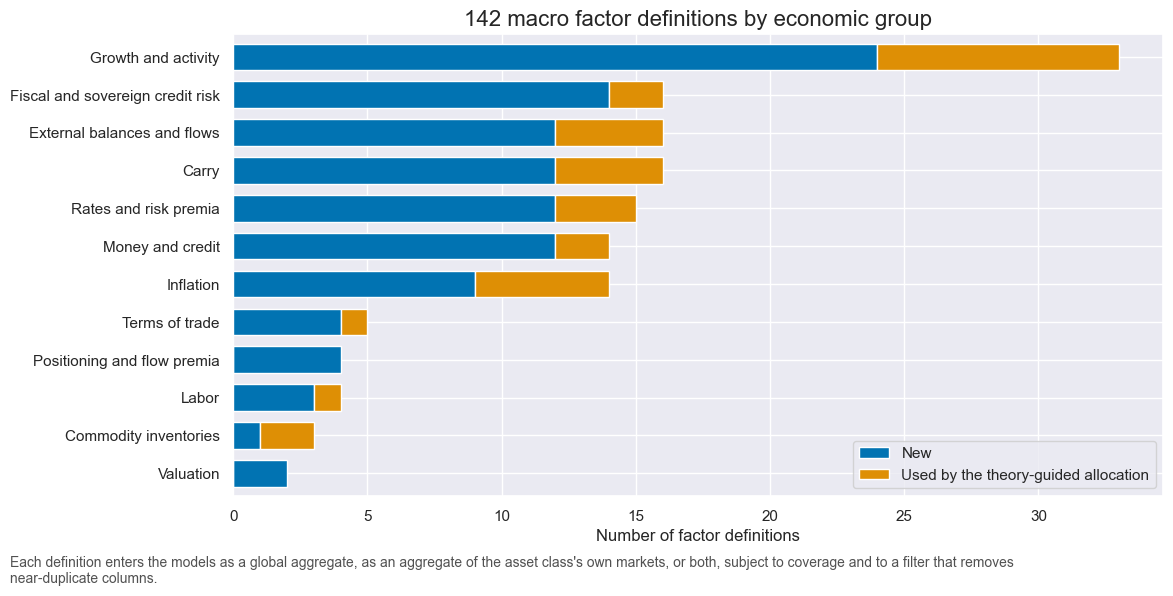

predictors per asset-class model: 103 to 218, median 207; 101 global and up to 117 own-market columns


In [265]:
# Factor definitions by economic group

dict_family_labels = {
    "growth": "Growth and activity",
    "inflation": "Inflation",
    "labor": "Labor",
    "money-credit": "Money and credit",
    "external": "External balances and flows",
    "terms-of-trade": "Terms of trade",
    "other": "Fiscal and sovereign credit risk",
    "rates-premia": "Rates and risk premia",
    "carry": "Carry",
    "valuation": "Valuation",
    "positioning-flow": "Positioning and flow premia",
    "commodity-specific": "Commodity inventories",
}

# one row per factor definition, split by whether the theory-guided allocation already uses it
df_groups = (
    pd.DataFrame(
        {
            "group": [dict_family_labels[recipe["family"]] for recipe in dict_recipes.values()],
            "origin": ["Used by the theory-guided allocation" if token in THEORY_TOKENS else "New" for token in dict_recipes],
        }
    )
    .value_counts()
    .unstack(fill_value=0)
)
df_groups = df_groups.loc[df_groups.sum(axis=1).sort_values().index, ["New", "Used by the theory-guided allocation"]]

ax = df_groups.plot.barh(stacked=True, figsize=(12, 6), width=0.7, color=["#0173b2", "#de8f05"])
ax.set_title(f"{len(dict_recipes)} macro factor definitions by economic group", fontsize=16)
ax.set_xlabel("Number of factor definitions", fontsize=12)
ax.set_ylabel("")
ax.legend(title=None, fontsize=11)
show_with_footnote(
    ax.figure,
    "Each definition enters the models as a global aggregate, as an aggregate of the asset class's own markets, "
    "or both, subject to coverage and to a filter that removes near-duplicate columns.",
)

# predictors each asset-class model reads after the filters: all global columns plus its own-market columns with data
own_per_class = df_factz_own[df_factz_own["xcat"].isin(FACTS_OWN)].groupby("cid", observed=True)["xcat"].nunique()
n_predictors = len(FACTS_BCAST) + own_per_class.reindex(asset_classes).fillna(0).astype(int)
print(
    f"predictors per asset-class model: {n_predictors.min()} to {n_predictors.max()}, median {int(n_predictors.median())}; "
    f"{len(FACTS_BCAST)} global and up to {own_per_class.max()} own-market columns"
)


## Learning-based signal generation

### Model targets


In [266]:
# Create vol-targeted asset class returns

dfa = msp.historic_vol(
    dfx,
    xcat="XR_NSA",
    cids=asset_classes,
    lback_periods=261,
    lback_meth="ma",
    est_freq="m",
    postfix="ASD",
)
dfx = msm.update_df(dfx, dfa)
dfa = msp.panel_calculator(dfx, calcs=["XRVT = XR_NSA * 10 / XR_NSAASD"], cids=asset_classes)
dfx = msm.update_df(dfx, dfa)


In [267]:
# Reformat vol-targeted asset class returns for SignalOptimizer

cols = ["cid", "xcat", "real_date", "value"]
rets_rf = [f"{ac}_XRVT" for ac in asset_classes]
df_rf_rets = dfx[(dfx["xcat"] == "XRVT") & (dfx["cid"].isin(asset_classes))].copy()
df_rf_rets["xcat"] = df_rf_rets["cid"] + "_XRVT"
df_rf_rets["cid"] = "GLB"

dfrf = df_rf_rets[cols].reset_index(drop=True)
print(f"{len(rets_rf)} vol-targeted targets, panel from {dfrf['real_date'].min().date()}")


11 vol-targeted targets, panel from 2000-01-03


### Sequential learning

In [268]:
# Set learning parameters for mapping features to asset class return forecasts

# Maximum number of iterations for each Lasso fit
ML_MAX_ITER = 50_000 

# Ridge penalty strengths
ML_RIDGE_ALPHAS = [10.0, 1_000.0]

# Lasso penalty strengths
ML_LASSO_ALPHAS = [0.01, 0.1]

# Time-weighted least squares half-lives, in months (5 and 10 years)
ML_TWLS_HALF_LIVES = [60, 120]

# Plain OLS without and with an intercept
ML_OLS_INTERCEPTS = [False]

# Number of principal components to consider
ML_COMPONENTS = [5, 6, 7, 8, 10]

# Total number of model members
ML_N_PER_COMPONENT = (
    len(ML_RIDGE_ALPHAS) + len(ML_LASSO_ALPHAS) + len(ML_TWLS_HALF_LIVES) + len(ML_OLS_INTERCEPTS)
)
ML_N_MEMBERS = len(ML_COMPONENTS) * ML_N_PER_COMPONENT

# Minimum number of periods required for model fitting
ML_MIN_PERIODS = 48


In [269]:
# Prepares the input shared by all asset class models

# Ensures that targets exist

assert set(rets_rf) <= set(dfrf["xcat"]), "run the model targets cell first"

# Builds the shared-feature table, one column per feature and one row per date

df_broadcast_features = (
    df_factz[df_factz["xcat"].isin(FACTS_BCAST)]
    .pivot(index="real_date", columns="xcat", values="value")
    .reindex(columns=FACTS_BCAST)
)
cols_std = ["cid", "xcat", "real_date", "value"]


In [270]:
# Main operation: Sequential learning of models and signals for all asset classes

so_ml, ml_signals, ml_iters, ml_topw = {}, [], {}, {}

# Loop through asset classes
for asset_class in asset_classes:
    # Asset-class specific features
    df_own_features = (
        df_factz_own[df_factz_own["cid"] == asset_class]
        .pivot(index="real_date", columns="xcat", values="value")
        .reindex(columns=FACTS_OWN)
        .reindex(df_broadcast_features.index)
    )
    # Shared features across asset classes
    df_sleeve_broadcast = df_broadcast_features.reindex(
        columns=dict_sleeve_features[asset_class]
    )
    # Filling gaps
    df_model_features = (
        pd.concat([df_sleeve_broadcast, df_own_features], axis=1).ffill().fillna(0.0)
    )
    assert (
        list(df_model_features.columns) == dict_sleeve_features[asset_class] + FACTS_OWN
    ), "feature order drifted from the registry"
    assert (
        not df_model_features.isna().any().any()
    ), "NaN in the design matrix: drop_nas would eat rows"

    # Re-shape table to long format
    df_features_long = df_model_features.stack().rename("value").reset_index()
    df_features_long.columns = ["real_date", "xcat", "value"]
    df_features_long["cid"] = "GLB"
    df_target = dfrf.loc[dfrf["xcat"] == f"{asset_class}_XRVT", cols_std]
    dfp_ml = pd.concat([df_features_long[cols_std], df_target], ignore_index=True)

    # Instantiate optimizer class
    signal_optimizer = msl.SignalOptimizer(
        df=dfp_ml,
        xcats=list(df_model_features.columns) + [f"{asset_class}_XRVT"],
        cids=["GLB"],
        freq="M",
        lag=1,
        xcat_aggs=["last", "sum"],
        drop_nas=True,
    )

    # Define the 40 candidate models: two each of Ridge, Lasso, time-weighted least squares and OLS
    regressors = [
        (f"ridge_{alpha:g}", Ridge(alpha=alpha, fit_intercept=False))
        for alpha in ML_RIDGE_ALPHAS
    ]
    regressors += [
        (
            f"lasso_{alpha:g}",
            Lasso(alpha=alpha, fit_intercept=False, max_iter=ML_MAX_ITER),
        )
        for alpha in ML_LASSO_ALPHAS
    ]
    regressors += [
        (
            f"twls_{half_life}",
            msl.TimeWeightedLinearRegression(fit_intercept=False, half_life=half_life),
        )
        for half_life in ML_TWLS_HALF_LIVES
    ]
    regressors += [
        ("ols_intercept" if intercept else "ols", LinearRegression(fit_intercept=intercept))
        for intercept in ML_OLS_INTERCEPTS
    ]
    model_members = [
        (
            f"pc{n_components}_{regressor_name}",
            Pipeline(
                [
                    ("pca", PCA(n_components=n_components, random_state=42)),
                    ("reg", regressor),
                ]
            ).set_output(transform="pandas"),
            {},
        )
        for n_components in ML_COMPONENTS
        for regressor_name, regressor in regressors
    ]

    # Actual sequential signal generation
    signal_optimizer.calculate_predictions(
        name="ML",
        models={
            "AVG": msl.ModelAveragingRegressor(
                estimators=model_members,
                scoring=make_scorer(msl.correlation_coefficient),
                cv=msl.ExpandingKFoldPanelSplit(n_splits=3),
            )
        },
        hyperparameters=None,
        scorers=None,
        inner_splitters=None,
        store_additional_data=[
            "weights_",
            "best_estimators_",
        ],  # member weights and fitted members
        min_cids=1,  # the training panel is a single synthetic cross-section
        min_periods=ML_MIN_PERIODS,
        test_size=3,  # quarterly retraining
        n_jobs_outer=4,  # explicit worker count; -1 can crash lazy worker imports
    )
    so_ml[asset_class] = signal_optimizer

    # Collect and check forecasts
    dfa = signal_optimizer.get_optimized_signals()
    assert len(dfa), f"{asset_class}: no signal rows, check drop_nas and min_periods"
    assert np.isfinite(
        dfa["value"]
    ).all(), f"{asset_class}: non-finite forecasts, the averager's weights collapsed"
    dfa["cid"], dfa["xcat"] = asset_class, "ML_PRED"
    ml_signals.append(dfa)

    # Retrieves the forecasts and checks they are not empty, NaN or infinity
    optimal_models = signal_optimizer.get_optimal_models("ML")
    fitted_details = [
        details
        for details in optimal_models["additional_data"]
        if isinstance(details, dict)
    ]
    member_weights = pd.DataFrame(
        [
            details["weights_"]
            for details in fitted_details
            if isinstance(details.get("weights_"), dict)
        ]
    )
    assert (
        len(member_weights) == len(optimal_models)
        and np.isfinite(member_weights.to_numpy()).all()
    ), (
        f"{asset_class}: NaN member weights at {int(member_weights.isna().any(axis=1).sum())} retrains; a member "
        "scored NaN in cross-validation and the optimizer would carry stale forecasts forward"
    )
    assert (
        member_weights.shape[1] == ML_N_MEMBERS
    ), f"{asset_class}: {member_weights.shape[1]} member weights, expected {ML_N_MEMBERS}"

    # Record the top member weight and Lasso iteration counts
    ml_topw[asset_class] = float(member_weights.max(axis=1).mean())
    ml_iters[asset_class] = sum(
        1
        for details in fitted_details
        for member_name, estimator in (details.get("best_estimators_") or {}).items()
        if "lasso" in member_name
        and int(getattr(estimator.named_steps["reg"], "n_iter_", 0)) >= ML_MAX_ITER
    )
    print(
        f"{asset_class}: {len(dfa)} signal rows from {dfa['real_date'].min().date()}, {len(optimal_models)} retrains, "
        f"mean top member weight {ml_topw[asset_class]:.3f}"
        + (
            f", {ml_iters[asset_class]} Lasso fits at the iteration ceiling"
            if ml_iters[asset_class]
            else ""
        )
    )

    # Drop large data tables to save memory
    del df_own_features, df_model_features, df_features_long, df_target, dfp_ml
    gc.collect()

  0%|          | 0/89 [00:00<?, ?it/s]

USEQ: 5762 signal rows from 2004-09-30, 89 retrains, mean top member weight 0.044


  0%|          | 0/89 [00:00<?, ?it/s]

DXEQ: 5762 signal rows from 2004-09-30, 89 retrains, mean top member weight 0.047


  0%|          | 0/89 [00:00<?, ?it/s]

EMEQ: 5762 signal rows from 2004-09-30, 89 retrains, mean top member weight 0.043


... (12 outputs left out)

  0%|          | 0/89 [00:00<?, ?it/s]

MTL: 5762 signal rows from 2004-09-30, 89 retrains, mean top member weight 0.044


  0%|          | 0/89 [00:00<?, ?it/s]

GLD: 5762 signal rows from 2004-09-30, 89 retrains, mean top member weight 0.047


In [271]:
# Sequential forecast registration and summary

dfx = msm.update_df(dfx, pd.concat(ml_signals, ignore_index=True))
del df_broadcast_features
gc.collect()

print(
    f"\nmean top member weight across sleeves {np.mean(list(ml_topw.values())):.3f} "
    f"against {1 / ML_N_MEMBERS:.3f} for equal weights over {ML_N_MEMBERS} members"
)
if sum(ml_iters.values()):
    print(
        "coordinate descent hit the iteration ceiling in "
        f"{sum(ml_iters.values())} Lasso member fits: those members are not converged "
        "optima and the weighted map should be read with that in mind"
    )
else:
    print("every Lasso member fit converged inside the iteration ceiling")



mean top member weight across sleeves 0.045 against 0.029 for equal weights over 35 members
every Lasso member fit converged inside the iteration ceiling


### In-sample PCA diagnostics

In [272]:
# Set PCA parameters and input table

# PCA_K: number of components fitted per asset class
# PCA_TOP: number of top components to retain for analysis
# PCA_REF: reference asset class for orienting loadings
PCA_K, PCA_TOP, PCA_REF = 10, 8, "USEQ"

# Take the standardised factors in df_factz that apply to every asset class
df_broadcast_features = (
    df_factz[df_factz["xcat"].isin(FACTS_BCAST)]
    .pivot(index="real_date", columns="xcat", values="value")
    .reindex(columns=FACTS_BCAST)
)


In [273]:
# Fit PCA non-sequentially for each asset class and compute explained variance shares

pca_fit, pca_share = {}, {}  # dictionaries to fill in loop

# Loop over each asset class
for asset_class in asset_classes:

    # Extract features for the current asset class
    df_own_features = (
        df_factz_own[df_factz_own["cid"] == asset_class]
        .pivot(index="real_date", columns="xcat", values="value")
        .reindex(columns=FACTS_OWN)
        .reindex(df_broadcast_features.index)
    )
    # Combine with features shared across asset classes
    df_model_features = (
        pd.concat(
            [
                df_broadcast_features.reindex(columns=dict_sleeve_features[asset_class]),
                df_own_features,
            ],
            axis=1,
        )
        .ffill()
        .fillna(0.0)
    )
    # Filter out rows with all zero values
    df_model_features = df_model_features.loc[df_model_features.abs().sum(axis=1) > 0]
    # Find the last date in the table for each month
    month_end_dates = (
        df_model_features.index.to_series()
        .groupby([df_model_features.index.year, df_model_features.index.month])
        .max()
    )
    # Keep only end-of-month rows
    df_monthly_features = df_model_features.loc[month_end_dates.values]
    # Fit scikit-learn PCA on the monthly features
    fitted_pca = PCA(n_components=PCA_K, random_state=42).fit(df_monthly_features.values)
    # Store the fitted model
    pca_fit[asset_class] = (fitted_pca, list(df_monthly_features.columns))
    # Extract summary figures
    pca_share[ac_labels[asset_class]] = {
        "months": len(df_monthly_features),
        "first five": fitted_pca.explained_variance_ratio_[:5].sum(),
        "first ten": fitted_pca.explained_variance_ratio_.sum(),
    }

# Summary table for display
df_variance_shares = pd.DataFrame(pca_share).T
display(df_variance_shares.round(3))
print(
    f"the first five components carry {df_variance_shares['first five'].median():.0%} of the menu's "
    f"variance in the median sleeve, from {df_variance_shares['first five'].min():.0%} to "
    f"{df_variance_shares['first five'].max():.0%}; the first ten carry {df_variance_shares['first ten'].median():.0%}"
)

,months,first five,first ten
US equity,322.0,0.574,0.731
DM equity (ex US),322.0,0.561,0.711
EM equity,322.0,0.542,0.711
US Treasuries,322.0,0.574,0.731
DM gov. bonds (ex US),322.0,0.550,0.713
DM FX,322.0,0.569,0.719
DM corporate credit,322.0,0.593,0.746
EM sovereign credit,322.0,0.540,0.703
EM local currency bonds,322.0,0.542,0.701
Industrial metals basket,322.0,0.594,0.761


the first five components carry 57% of the menu's variance in the median sleeve, from 54% to 60%; the first ten carry 72%


In [274]:
# Analyze PCA of one selected asset class

reference_pca, reference_features = pca_fit[PCA_REF]
df_reference_loadings = pd.DataFrame(
    reference_pca.components_.T,
    index=reference_features,
    columns=[f"PC{component_index + 1}" for component_index in range(PCA_K)],
)
for component in df_reference_loadings.columns:
    if (
        df_reference_loadings[component][
            df_reference_loadings[component].abs().idxmax()
        ]
        < 0
    ):
        df_reference_loadings[component] = -df_reference_loadings[component]
factor_families = df_reference_loadings.index.map(
    lambda feature: dict_factor_families.get(feature, "unclassified")
)
print(f"\nloadings of the {ac_labels[PCA_REF]} menu, full sample, summed by family:")
for component_index, component in enumerate(df_reference_loadings.columns[:5]):
    family_loadings = (
        df_reference_loadings[component].groupby(factor_families).sum().sort_values()
    )
    print(
        f"{component}, {reference_pca.explained_variance_ratio_[component_index]:.1%} of variance. positive: "
        + ", ".join(
            f"{family} {value:+.2f}"
            for family, value in family_loadings.tail(3)[::-1].items()
        )
        + " | negative: "
        + ", ".join(
            f"{family} {value:+.2f}"
            for family, value in family_loadings.head(3).items()
        )
    )


loadings of the US equity menu, full sample, summed by family:
PC1, 20.9% of variance. positive: growth +3.07, inflation +2.01, money-credit +0.53 | negative: rates-premia -0.21, labor -0.20, commodity-specific -0.18
PC2, 13.8% of variance. positive: growth +3.02, carry +0.97, money-credit +0.79 | negative: rates-premia -0.34, inflation -0.29, other -0.13
PC3, 9.3% of variance. positive: growth +2.29, rates-premia +0.72, other +0.04 | negative: inflation -1.78, carry -0.78, money-credit -0.36
PC4, 7.6% of variance. positive: rates-premia +1.71, money-credit +0.60, carry +0.56 | negative: terms-of-trade -0.51, labor -0.01, commodity-specific -0.01
PC5, 5.8% of variance. positive: money-credit +0.97, carry +0.62, terms-of-trade +0.23 | negative: growth -1.36, rates-premia -0.87, inflation -0.61


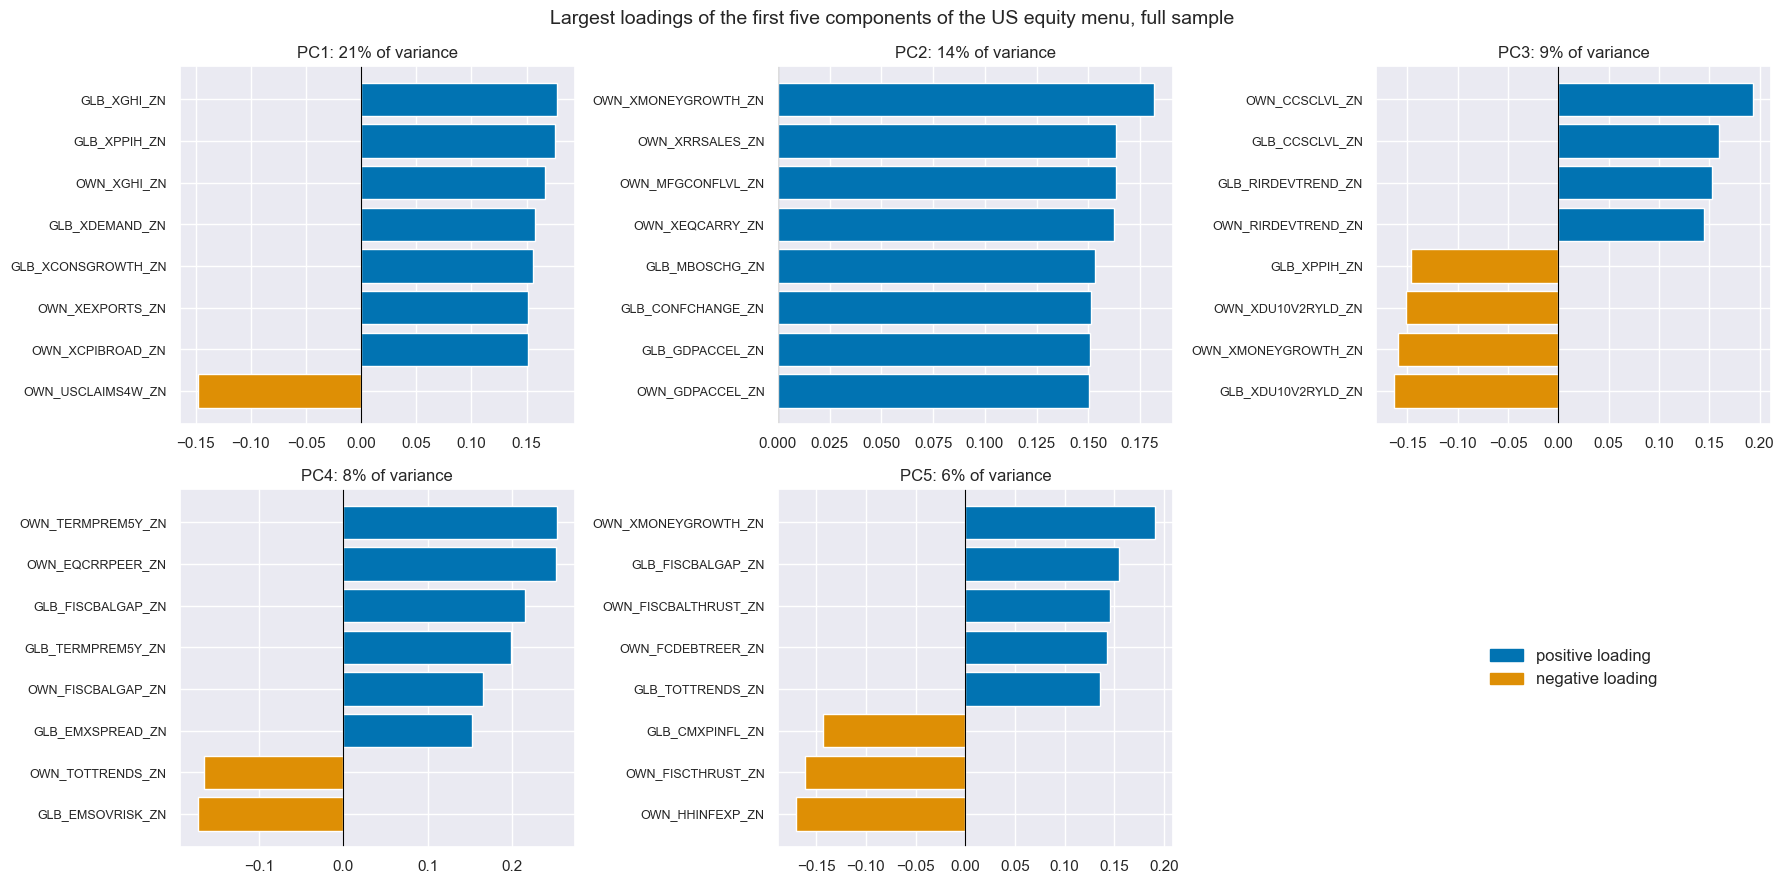

In [275]:
# Visualize PCA of selected asset class

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
axes = axes.ravel()
for component_index, (ax, component) in enumerate(zip(axes, df_reference_loadings.columns[:5])):
    largest_loadings = df_reference_loadings[component].reindex(
        df_reference_loadings[component].abs().sort_values(ascending=False).index[:PCA_TOP]
    )
    largest_loadings = largest_loadings.sort_values()
    ax.barh(
        largest_loadings.index,
        largest_loadings.values,
        color=np.where(largest_loadings.values >= 0, "C0", "C1"),
    )
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(
        f"{component}: {reference_pca.explained_variance_ratio_[component_index]:.0%} of variance",
        fontsize=12,
    )
    ax.tick_params(axis="y", labelsize=9)
axes[-1].axis("off")
axes[-1].legend(
    handles=[
        plt.Rectangle((0, 0), 1, 1, color="C0", label="positive loading"),
        plt.Rectangle((0, 0), 1, 1, color="C1", label="negative loading"),
    ],
    loc="center",
    fontsize=12,
    frameon=False,
)
fig.suptitle(
    f"Largest loadings of the first five components of the {ac_labels[PCA_REF]} menu, full sample",
    fontsize=14,
)
plt.tight_layout()
plt.show()


### What the averaged model leans on

In [276]:
# Original-feature coefficient reconstruction

TOP_K, PERSIST = 10, 0.5

coef_ml, share_ml, members_ml = {}, {}, {}
top_hits = {asset_class: {} for asset_class in asset_classes}
for asset_class, signal_optimizer in so_ml.items():
    optimal_models = signal_optimizer.get_optimal_models("ML")
    fitted_details = [
        details
        for details in optimal_models["additional_data"]
        if isinstance(details, dict) and isinstance(details.get("best_estimators_"), dict)
    ]
    assert fitted_details, f"{asset_class}: no fitted members stored, check store_additional_data"
    feature_names = list(signal_optimizer.X.columns)
    coefficient_rows = []
    for details in fitted_details:
        member_weights = details["weights_"]
        weighted_coefficients = []
        for member_name, estimator in details["best_estimators_"].items():
            # Map component coefficients back to the original feature columns.

            components = np.asarray(estimator.named_steps["pca"].components_, dtype=float)
            component_coefficients = np.asarray(
                estimator.named_steps["reg"].coef_, dtype=float
            ).ravel()
            feature_coefficients = components.T @ component_coefficients
            weighted_coefficients.append(member_weights[member_name] * feature_coefficients)
        # Preserve the fitted members' summation order.

        coefficient_rows.append(sum(weighted_coefficients))
    coefficient_matrix = np.vstack(coefficient_rows)
    assert coefficient_matrix.shape[1] == len(
        feature_names
    ), f"{asset_class}: coefficient width does not match the features"

    coef_ml[asset_class] = pd.Series(coefficient_matrix.mean(axis=0), index=feature_names)
    members_ml[asset_class] = pd.DataFrame(
        [details["weights_"] for details in fitted_details]
    ).mean()
    absolute_totals = np.abs(coefficient_matrix).sum(axis=1, keepdims=True)
    nonzero_rows = absolute_totals.ravel() > 0
    share_ml[asset_class] = pd.Series(
        (
            (np.abs(coefficient_matrix[nonzero_rows]) / absolute_totals[nonzero_rows]).mean(axis=0)
            if nonzero_rows.any()
            else np.zeros(len(feature_names))
        ),
        index=feature_names,
    )
    for absolute_coefficients in np.abs(coefficient_matrix):
        if absolute_coefficients.max() == 0:
            continue
        for feature_index in np.argsort(-absolute_coefficients)[:TOP_K]:
            top_hits[asset_class][feature_names[feature_index]] = (
                top_hits[asset_class].get(feature_names[feature_index], 0) + 1
            )

retrain_counts = {
    asset_class: len(signal_optimizer.get_optimal_models("ML"))
    for asset_class, signal_optimizer in so_ml.items()
}


In [277]:
# Model member weight summaries

df_member_weights = pd.DataFrame(members_ml).reindex(columns=asset_classes)
weights_by_components = df_member_weights.groupby(
    df_member_weights.index.map(lambda member_name: int(member_name.split("_")[0][2:]))
).sum()
weights_by_regressor = df_member_weights.groupby(
    df_member_weights.index.map(lambda member_name: member_name.split("_", 1)[1])
).sum()
print(
    f"mean member weight is {1 / ML_N_MEMBERS:.3f} under equal weights; summed weight by "
    f"component count per sleeve ({1 / len(ML_COMPONENTS):.2f} would be equal):"
)
display(weights_by_components.round(3))
print(
    f"\nsummed weight by regressor, pooled over sleeves "
    f"({1 / ML_N_PER_COMPONENT:.3f} would be equal): "
    + ", ".join(
        f"{group_name} {value:.3f}"
        for group_name, value in weights_by_regressor.mean(axis=1)
        .sort_values(ascending=False)
        .items()
    )
)


mean member weight is 0.029 under equal weights; summed weight by component count per sleeve (0.20 would be equal):


,USEQ,DXEQ,EMEQ,USDU,DXDU,DXFX,G2CR,EMCR,EMLC,MTL,GLD
5,0.197,0.228,0.157,0.141,0.243,0.279,0.198,0.173,0.174,0.187,0.245
6,0.205,0.211,0.194,0.154,0.197,0.199,0.195,0.190,0.191,0.178,0.215
7,0.205,0.183,0.210,0.197,0.186,0.180,0.179,0.217,0.202,0.209,0.205
8,0.193,0.198,0.212,0.232,0.174,0.180,0.205,0.218,0.211,0.219,0.178
10,0.200,0.180,0.228,0.275,0.200,0.161,0.223,0.202,0.222,0.208,0.157



summed weight by regressor, pooled over sleeves (0.143 would be equal): ridge_1000 0.152, ols 0.143, ridge_10 0.143, lasso_0.01 0.143, lasso_0.1 0.142, twls_120 0.139, twls_60 0.138


In [278]:
# Coefficient shares by feature origin

df_coefficient_shares = pd.DataFrame(share_ml).reindex(columns=asset_classes).fillna(0.0)
by_origin = df_coefficient_shares.groupby(
    df_coefficient_shares.index.map(dict_factor_origins)
).sum()
print("\nweight share by origin, per sleeve:")
display(by_origin.round(3))
print(
    "pooled over sleeves: "
    + ", ".join(
        f"{group_name} {value:.3f}"
        for group_name, value in by_origin.mean(axis=1).sort_values(ascending=False).items()
    )
)



weight share by origin, per sleeve:


,USEQ,DXEQ,EMEQ,USDU,DXDU,DXFX,G2CR,EMCR,EMLC,MTL,GLD
new GLB,0.356,0.339,0.371,0.369,0.341,0.320,0.378,0.331,0.336,0.726,0.698
new OWN,0.379,0.429,0.393,0.383,0.398,0.430,0.364,0.424,0.410,0.026,0.019
theory GLB,0.126,0.114,0.125,0.129,0.127,0.118,0.126,0.121,0.125,0.226,0.265
theory OWN,0.140,0.119,0.112,0.119,0.134,0.132,0.132,0.124,0.129,0.022,0.018


pooled over sleeves: new GLB 0.415, new OWN 0.332, theory GLB 0.146, theory OWN 0.107



weight share by family, per sleeve:


,USEQ,DXEQ,EMEQ,USDU,DXDU,DXFX,G2CR,EMCR,EMLC,MTL,GLD
carry,0.064,0.072,0.086,0.062,0.084,0.085,0.043,0.069,0.076,0.089,0.114
commodity-specific,0.009,0.010,0.011,0.009,0.012,0.011,0.012,0.013,0.013,0.035,0.036
external,0.042,0.083,0.100,0.062,0.070,0.075,0.061,0.073,0.075,0.042,0.039
growth,0.218,0.256,0.259,0.237,0.271,0.305,0.272,0.254,0.242,0.261,0.245
inflation,0.165,0.159,0.132,0.144,0.128,0.099,0.186,0.168,0.138,0.106,0.097
labor,0.025,0.012,0.013,0.026,0.014,0.020,0.031,0.021,0.034,0.013,0.019
money-credit,0.135,0.141,0.120,0.172,0.121,0.120,0.138,0.123,0.116,0.195,0.143
other,0.130,0.099,0.130,0.110,0.080,0.066,0.084,0.098,0.107,0.114,0.122
positioning-flow,0.016,0.024,0.031,0.013,0.030,0.038,0.021,0.024,0.027,0.033,0.029
rates-premia,0.155,0.103,0.088,0.136,0.149,0.144,0.113,0.102,0.131,0.101,0.132


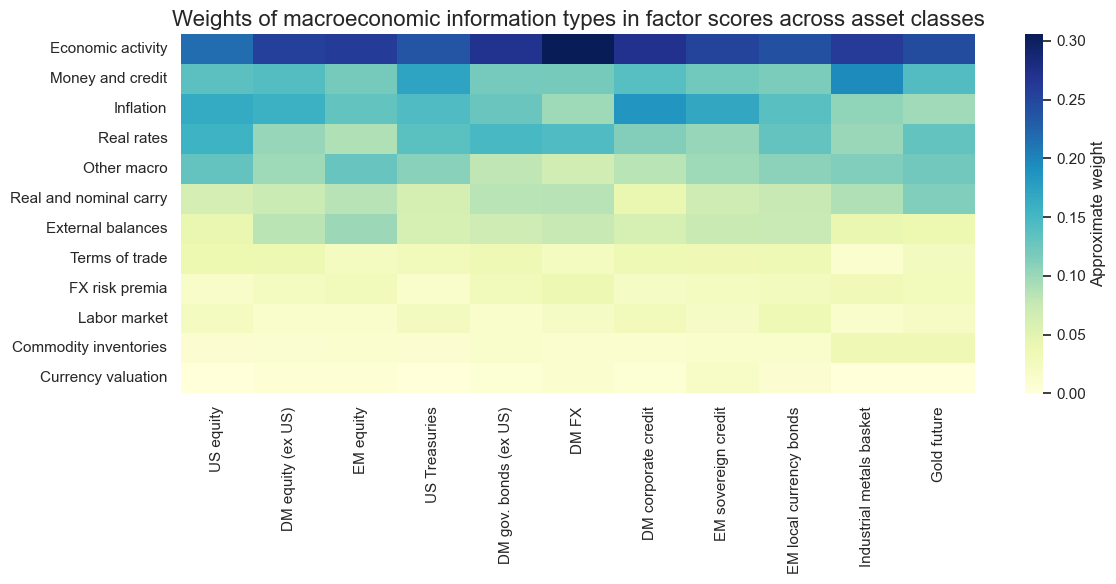

In [279]:
# Weights of macro types in asset class factor scores

dict_relabel = {
    "growth": "Economic activity",
    "money-credit": "Money and credit",
    "inflation": "Inflation",
    "rates-premia": "Real rates",
    "other": "Other macro",
    "carry": "Real and nominal carry",
    "external": "External balances",
    "terms-of-trade": "Terms of trade",
    "positioning-flow": "FX risk premia",
    "labor": "Labor market",
    "commodity-specific": "Commodity inventories",
    "valuation": "Currency valuation",
}

by_family = df_coefficient_shares.groupby(
    df_coefficient_shares.index.map(
        lambda feature: dict_factor_families.get(feature, "unclassified")
    )
).sum()
unclassified = [
    feature for feature in df_coefficient_shares.index if feature not in dict_factor_families
]
if unclassified:
    print(f"{len(unclassified)} columns carry no family tag and roll up as unclassified")
print("\nweight share by family, per sleeve:")
display(by_family.round(3))

fig, ax = plt.subplots(figsize=(12, max(4, 0.5 * len(by_family))))
sns.heatmap(
    by_family.reindex(by_family.mean(axis=1).sort_values(ascending=False).index).rename(
        index=dict_relabel
    ),
    cmap="YlGnBu",
    ax=ax,
    cbar_kws={"label": "Approximate weight"},
    xticklabels=[ac_labels[asset_class] for asset_class in by_family.columns],
)
ax.set_title(
    "Weights of macroeconomic information types in factor scores across asset classes", fontsize=16
)
ax.set_xlabel("")
ax.set_ylabel("")
plt.tight_layout()
plt.show()


In [280]:
# Measuring the stability of feature choices across retraining dates

n_theory_columns = sum(
    1 for c in facts_menu if dict_factor_origins[c].startswith("theory")
)
persistence_rows = []
for asset_class in asset_classes:
    for feature, count in top_hits[asset_class].items():
        persistence_rows.append(
            {
                "sleeve": asset_class,
                "feature": feature,
                "origin": dict_factor_origins.get(feature, "unknown"),
                "family": dict_factor_families.get(feature, "unclassified"),
                "persistence": count / max(retrain_counts[asset_class], 1),
                "mean coefficient": float(coef_ml[asset_class][feature]),
            }
        )
df_persistence = pd.DataFrame(persistence_rows)
print(
    f"\ntop-{TOP_K} slots filled by {df_persistence['feature'].nunique()} distinct columns across "
    f"{len(asset_classes)} sleeves; a fully churning model would fill them with "
    f"{TOP_K * len(asset_classes)} distinct columns and a fully stable one with {TOP_K}"
)

new_feature_persistence = df_persistence[
    (~df_persistence["origin"].str.startswith("theory"))
    & (df_persistence["persistence"] >= PERSIST)
].sort_values("persistence", ascending=False)
print(
    f"\npersistent picks outside the {n_theory_columns} theory-guided concept columns, "
    f"in at least {PERSIST:.0%} of a sleeve's retrains: {len(new_feature_persistence)} rows"
)
if len(new_feature_persistence):
    display(new_feature_persistence.round(3).reset_index(drop=True))
    print("named list, by concept:")
    for feature in new_feature_persistence["feature"].drop_duplicates():
        selected_sleeves = ", ".join(
            new_feature_persistence.loc[
                new_feature_persistence["feature"] == feature, "sleeve"
            ]
        )
        first_sleeve = new_feature_persistence.loc[
            new_feature_persistence["feature"] == feature, "sleeve"
        ].iloc[0]
        sign = "positive" if coef_ml[first_sleeve][feature] > 0 else "negative"
        print(
            f"  {feature} [{dict_factor_concepts.get(feature, 'unknown')}] in {selected_sleeves}, mean sign {sign}"
        )
else:
    print(
        "no column outside the theory-guided concepts clears the persistence bar, which is "
        "itself the finding: the factor universe was sampled but not committed to"
    )

# the same bar applied to the theory-guided concepts, for symmetry

incumbent_persistence = df_persistence[
    (df_persistence["origin"].str.startswith("theory"))
    & (df_persistence["persistence"] >= PERSIST)
]
print(
    f"\nfor comparison, {incumbent_persistence['feature'].nunique()} of the "
    f"{n_theory_columns} theory-guided concept columns clear the same bar in at least one sleeve"
)


top-10 slots filled by 157 distinct columns across 11 sleeves; a fully churning model would fill them with 110 distinct columns and a fully stable one with 10

persistent picks outside the 51 theory-guided concept columns, in at least 50% of a sleeve's retrains: 38 rows


,sleeve,feature,origin,family,persistence,mean coefficient
0,MTL,GLB_XCSTR_ZN,new GLB,growth,0.944,0.127
1,EMCR,OWN_FCDEBTREER_ZN,new OWN,external,0.888,-0.087
2,USEQ,GLB_CPIACCEL_ZN,new GLB,inflation,0.865,-0.044
3,DXEQ,OWN_GDPPCGAP_ZN,new OWN,growth,0.831,0.046
4,MTL,GLB_EMXRISKAVG_ZN,new GLB,external,0.798,-0.090
5,EMCR,OWN_XCPIF_ZN,new OWN,inflation,0.798,-0.069
6,EMCR,OWN_FXWEAKCOMP_ZN,new OWN,valuation,0.764,0.083
7,USDU,GLB_CPIACCEL_ZN,new GLB,inflation,0.742,0.068
8,MTL,GLB_XFINEXP_ZN,new GLB,money-credit,0.708,0.088
9,USEQ,OWN_BLSSUPPLY_ZN,new OWN,money-credit,0.697,0.038


named list, by concept:
  GLB_XCSTR_ZN [excess-construction-activity] in MTL, mean sign positive
  OWN_FCDEBTREER_ZN [fc-debt-weighted-real-appreciation] in EMCR, mean sign negative
  GLB_CPIACCEL_ZN [inflation-acceleration] in USEQ, USDU, EMEQ, EMCR, DXEQ, G2CR, mean sign negative
  OWN_GDPPCGAP_ZN [gdp-per-capita] in DXEQ, EMEQ, mean sign positive
  GLB_EMXRISKAVG_ZN [em-external-risk-scores] in MTL, EMEQ, mean sign negative
  OWN_XCPIF_ZN [excess-food-cpi] in EMCR, mean sign negative
  OWN_FXWEAKCOMP_ZN [currency-weakness-composite] in EMCR, mean sign positive
  GLB_XFINEXP_ZN [excess-financial-expansion-composite] in MTL, USDU, DXEQ, mean sign positive
  OWN_BLSSUPPLY_ZN [bank-lending-survey-scores] in USEQ, mean sign positive
  GLB_XPCREDITGDP_ZN [excess-credit-to-gdp-expansion] in GLD, DXEQ, MTL, mean sign positive
  OWN_RIRDEVTREND_ZN [real-rate-deviation-from-own-trend] in USEQ, mean sign positive
  OWN_CPIACCEL_ZN [inflation-acceleration] in DXEQ, USDU, mean sign negative
  OW

### Allocation weights

In [281]:
# Learning-based asset class forecast scores

dfa = msp.make_zn_scores(
    df=dfx,
    xcat="ML_PRED",
    cids=asset_classes,
    neutral="zero",
    thresh=3,
    est_freq="M",
    min_obs=3 * 261,
    pan_weight=0,
    postfix="_ZN",
)
dfx = msm.update_df(dfx, dfa)


In [282]:
# Month-end forecast scores

df_forecast_scores = (
    dfx[(dfx["xcat"] == "ML_PRED_ZN") & (dfx["cid"].isin(asset_classes))]
    .pivot(index="real_date", columns="cid", values="value")
    .reindex(columns=asset_classes)
    .dropna(how="all")
)
forecast_month_ends = (
    df_forecast_scores.index.to_series()
    .groupby([df_forecast_scores.index.year, df_forecast_scores.index.month])
    .max()
)
logits_ml = df_forecast_scores.loc[forecast_month_ends.values]

# the spread across sleeves drives the tilts, the level drives the cash share

print(
    f"learning-based sleeve logits: level {logits_ml.mean(axis=1).abs().mean():.2f}, "
    f"cross-sectional spread {logits_ml.std(axis=1).mean():.2f}"
)


learning-based sleeve logits: level 0.48, cross-sectional spread 0.85


In [283]:
# Month-end cross-asset class portfolio weights

exponential_scores = np.exp(logits_ml)
w_ml = exponential_scores.div(
    exponential_scores.sum(axis=1) + 1.0, axis=0
)  # +1 is exp(0), the cash logit
w_ml["CASH"] = 1.0 - w_ml.sum(axis=1)


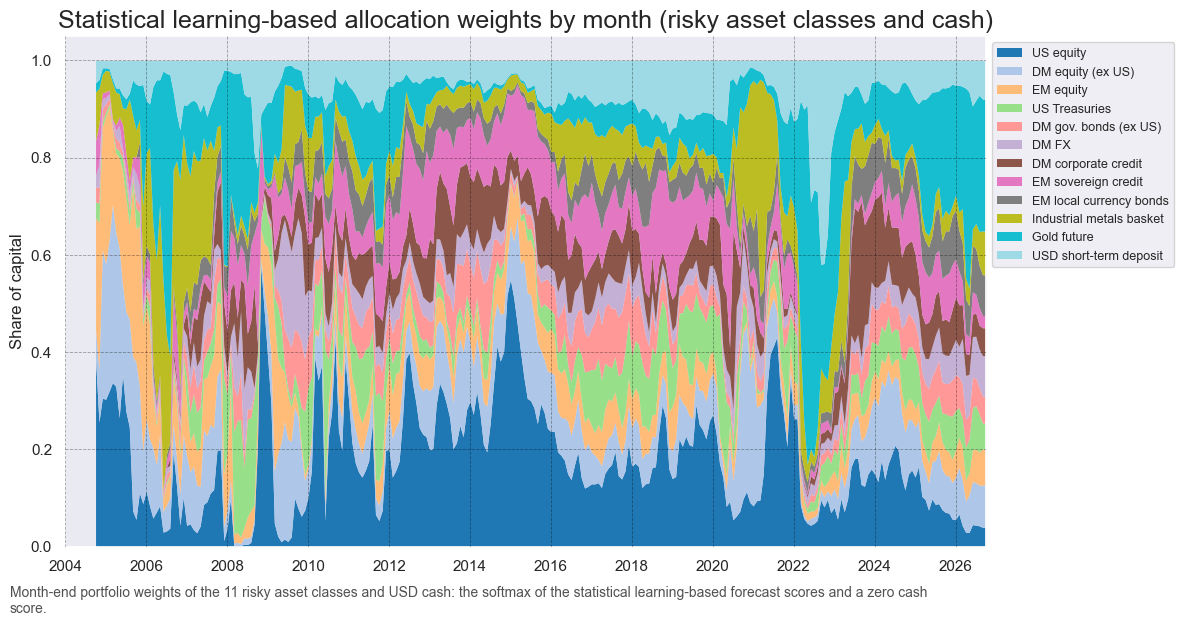

In [284]:
# Learning-based allocation weight visualization

fig = msv.view_weights(
    w_ml,
    cid_labels=ac_labels,
    title="Statistical learning-based allocation weights by month (risky asset classes and cash)",
    title_fontsize=18,
    ylabel="Share of capital",
    figsize=(12, 6),
    return_fig=True,
)
ax = fig.axes[0]

# Gridlines drawn over the stacked areas so they stay visible
ax.grid(True, color="black", linestyle="--", linewidth=0.6, alpha=0.35)
ax.set_axisbelow(False)

# x-axis labels every two years; convert_units handles both the date and the period axis that pandas may produce
tick_years = range((w_ml.index.min().year + 1) // 2 * 2, w_ml.index.max().year + 1, 2)
ax.set_xticks([ax.xaxis.convert_units(pd.Timestamp(f"{year}-01-01")) for year in tick_years])
ax.set_xticklabels([str(year) for year in tick_years], rotation=0, ha="center")
ax.minorticks_off()
show_with_footnote(
    fig,
    "Month-end portfolio weights of the 11 risky asset classes and USD cash: the softmax of the statistical "
    "learning-based forecast scores and a zero cash score.",
)

In [285]:
# Daily sequential weight registration

bdays = pd.DatetimeIndex(sorted(dfx.loc[dfx["xcat"] == "XR_NSA", "real_date"].unique()))
dfa = w_ml.reindex(bdays).ffill().dropna(how="all").stack().rename("value").reset_index()
dfa.columns = ["real_date", "cid", "value"]
dfa["xcat"] = "WGTML"
dfx = msm.update_df(dfx, dfa)


## For reference: theory-guided results

### The theory-guided allocation


In [286]:
# Softmax weights from composite scores

# wide table of composite scores
sw = (
    dfx[(dfx["xcat"] == "COMPOSITE_ZN") & (dfx["cid"].isin(asset_classes))]
    .pivot(index="real_date", columns="cid", values="value")
    .reindex(columns=asset_classes)
    .dropna(how="all")
)

# month-end scores

me_dates = sw.index.to_series().groupby([sw.index.year, sw.index.month]).max()
sm = sw.loc[me_dates.values]

# a sleeve enters the softmax only once its return series is live, so no weight
# goes to a sleeve that cannot be traded yet

live = (
    dfx[(dfx["xcat"] == "XR_NSA") & (dfx["cid"].isin(asset_classes))]
    .pivot(index="real_date", columns="cid", values="value")
    .notna()
    .reindex(sm.index, method="ffill")
    .reindex(columns=sm.columns)
    .fillna(False)
)

# cash logit fixed at zero

logits = sm.where(live)
logits["CASH"] = 0.0

# softmax weights

ew = np.exp(logits)  # exp(NaN) stays NaN, so masked sleeves drop from the sum
weights = ew.div(ew.sum(axis=1), axis=0).fillna(0.0)
display(weights.round(3).tail(3))

cid,USEQ,DXEQ,EMEQ,USDU,DXDU,DXFX,G2CR,EMCR,EMLC,MTL,GLD,CASH
real_date,,,,,,,,,,,,
2026-08-31,0.015,0.137,0.181,0.055,0.061,0.053,0.022,0.020,0.139,0.186,0.052,0.079
2026-09-30,0.014,0.077,0.187,0.094,0.070,0.060,0.043,0.054,0.047,0.202,0.049,0.104
2026-10-30,0.019,0.079,0.172,0.071,0.080,0.075,0.058,0.053,0.052,0.179,0.050,0.113


### Specs and panel test

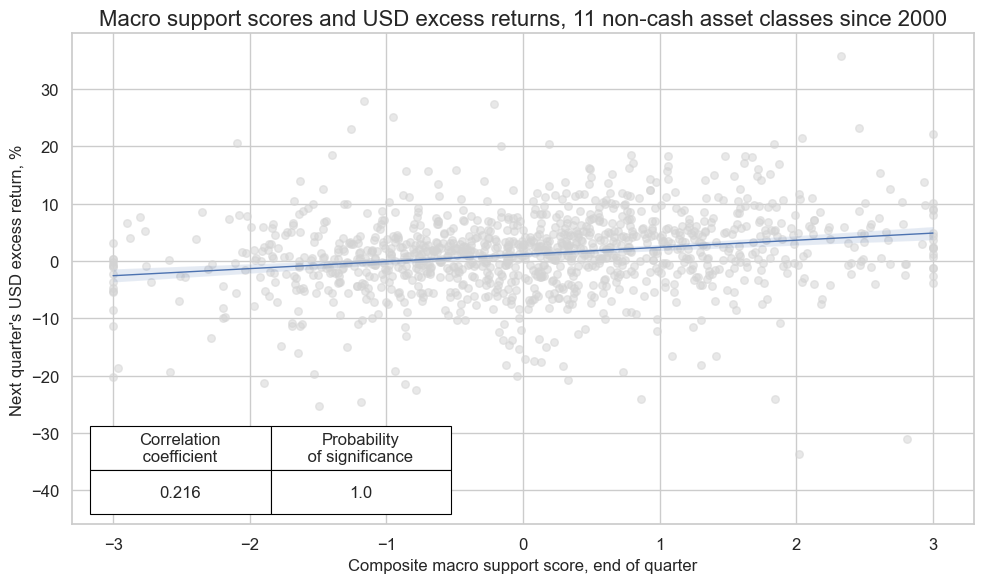

In [287]:
# Panel analysis: month-end composite scores and excess returns

cr = msp.CategoryRelations(
    dfx,
    xcats=["COMPOSITE_ZN", "XR_NSA"],
    cids=asset_classes,
    freq="Q",
    lag=1,
    xcat_aggs=["last", "sum"],
    start=start_date,
)
cr.reg_scatter(
    title=f"Macro support scores and USD excess returns, {len(asset_classes)} non-cash asset classes since {pd.Timestamp(start_date).year}",
    title_fontsize=16,
    labels=False,
    prob_est="map",
    coef_box="lower left",
    xlab="Composite macro support score, end of quarter",
    ylab="Next quarter's USD excess return, %",
    size=(10, 6),
)

In [288]:
# Significance triad for the composite-score relation

# Pearson correlation and panel-test probability from the chart above, plus Kendall
# rank correlation as a check that does not depend on outliers


def significance_triad(cr, label):
    """Pearson, panel-test probability, Kendall tau and its probability for one relation."""
    pearson, prob_map = cr.corr_prob_calc(cr.df, prob_est="map")[0]
    tau, p_tau = stats.kendalltau(cr.df[cr.xcats[0]], cr.df[cr.xcats[1]])
    return {
        "relation": label,
        "Pearson": pearson,
        "panel-test probability": prob_map,
        "Kendall tau": round(float(tau), 3),
        "Kendall probability": round(1 - float(p_tau), 3),
        "observations": len(cr.df),
    }


display(pd.DataFrame([significance_triad(cr, "composite score, next quarter's return")]).set_index("relation"))

,Pearson,panel-test probability,Kendall tau,Kendall probability,observations
relation,,,,,
"composite score, next quarter's return",0.216,1.0,0.165,1.0,1168


### Accuracy and correlation check

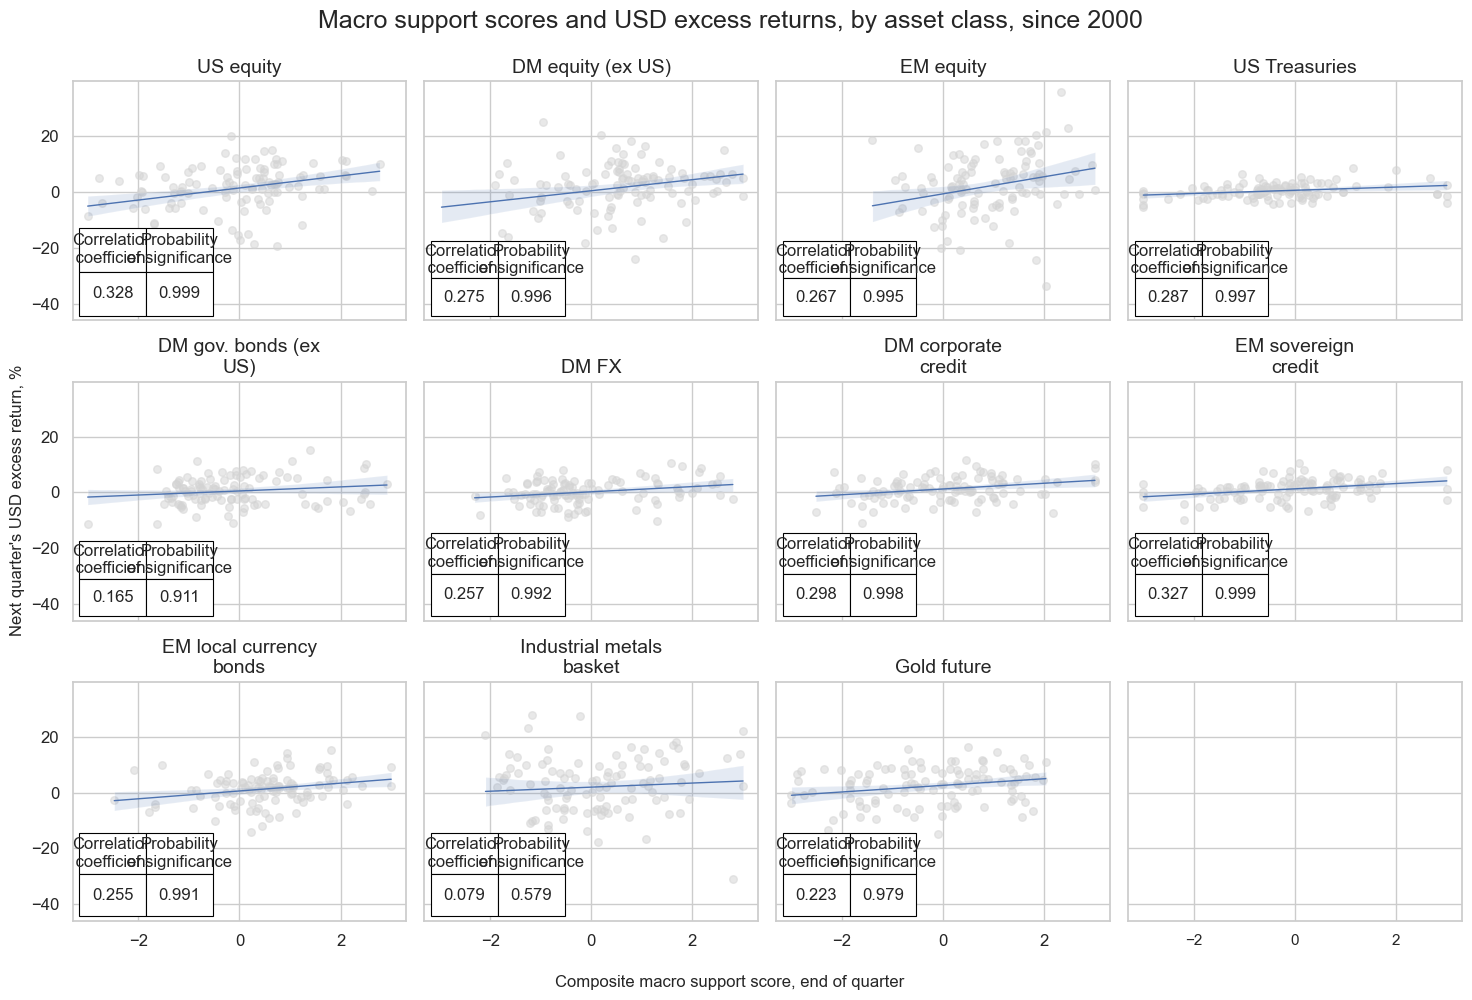

In [289]:
# Predictive power by asset class: composite scores

cr_list = [
    msp.CategoryRelations(
        dfx,
        xcats=["COMPOSITE_ZN", "XR_NSA"],
        cids=[ac],
        freq="Q",
        lag=1,
        xcat_aggs=["last", "sum"],
        start=start_date,
    )
    for ac in asset_classes
]

msv.multiple_reg_scatter(
    cat_rels=cr_list,
    title=f"Macro support scores and USD excess returns, by asset class, since {pd.Timestamp(start_date).year}",
    title_fontsize=18,
    xlab="Composite macro support score, end of quarter",
    ylab="Next quarter's USD excess return, %",
    ncol=4,
    nrow=3,
    figsize=(15, 10),
    prob_est="pool", # single cross-section
    coef_box="lower left",
    subplot_titles=[ac_labels[ac] for ac in asset_classes],
)

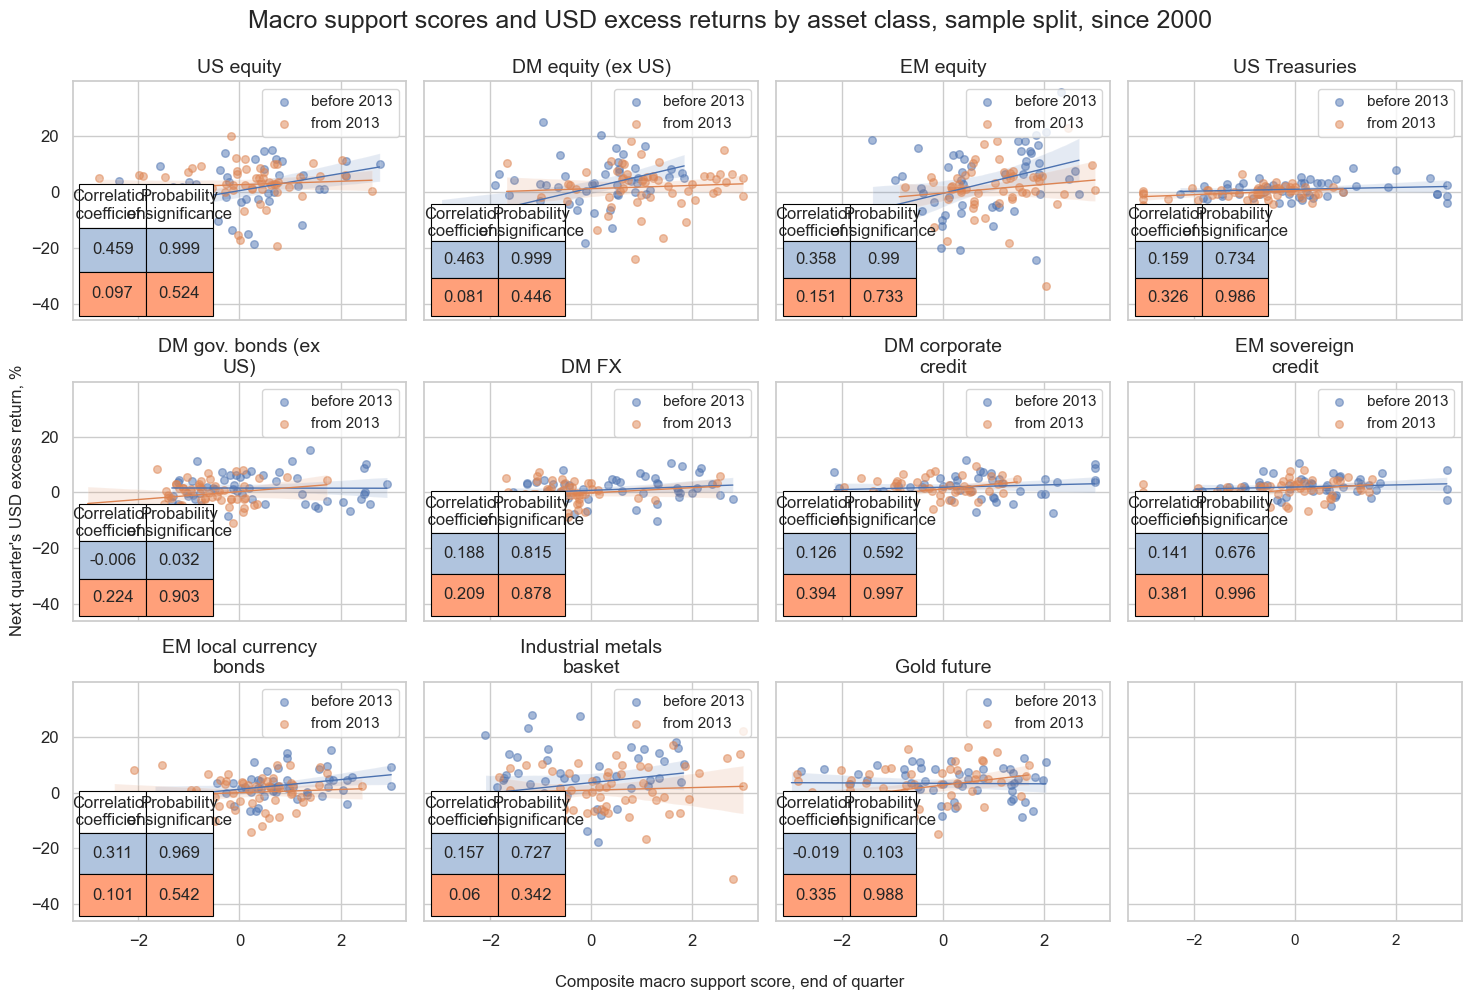

In [290]:
# Stability check for macro support scores

msv.multiple_reg_scatter(
    cat_rels=cr_list,
    title=f"Macro support scores and USD excess returns by asset class, sample split, since {pd.Timestamp(start_date).year}",
    title_fontsize=18,
    xlab="Composite macro support score, end of quarter",
    ylab="Next quarter's USD excess return, %",
    ncol=4,
    nrow=3,
    figsize=(15, 10),
    prob_est="pool", # single cross-section
    coef_box="lower left",
    separator=2013,
    subplot_titles=[ac_labels[ac] for ac in asset_classes],
)

### Naive PnL

In [291]:
# Macro and equal weights for the naive PnLs

# daily macro weights, carried forward from each month-end

bdays = pd.DatetimeIndex(sorted(dfx.loc[dfx["xcat"] == "XR_NSA", "real_date"].unique()))
wd = weights.reindex(bdays).ffill().dropna(how="all")

# equal weights over the sleeves live each day, so the anchor is fully invested
# before every sleeve exists

live_d = (
    dfx[(dfx["xcat"] == "XR_NSA") & (dfx["cid"].isin(asset_classes))]
    .pivot(index="real_date", columns="cid", values="value")
    .notna()
    .reindex(wd.index, method="ffill")
    .reindex(columns=wd.columns)
    .fillna(False)
)
live_d["CASH"] = True  # USD cash is live throughout
wn = live_d.div(live_d.sum(axis=1), axis=0)

for w, xcat in ((wd, "WGTMACRO"), (wn, "WGTEQUAL")):
    dfa = w.stack().rename("value").reset_index()
    dfa.columns = ["real_date", "cid", "value"]
    dfa["xcat"] = xcat
    dfx = msm.update_df(dfx, dfa)

In [292]:
# Naive excess PnLs of equal weights and macro weights

cidx = asset_classes + ["CASH"]

# the signal is already an allocation weight, so sig_op is raw and vol_scale None;
# quarterly rebalancing matches the holding period

xpnl = msn.NaivePnL(
    dfx,
    ret="XR_NSA",
    sigs=["WGTMACRO", "WGTEQUAL"],
    cids=cidx,
    start=start_date,
    bms=["USEQ_XR_NSA"],
)
for sig, name in (("WGTMACRO", "PNL_MACRO"), ("WGTEQUAL", "PNL_EQUAL")):
    xpnl.make_pnl(
        sig=sig,
        sig_op="raw",
        rebal_freq="quarterly",
        rebal_slip=1,
        vol_scale=None,
        pnl_name=name,
    )

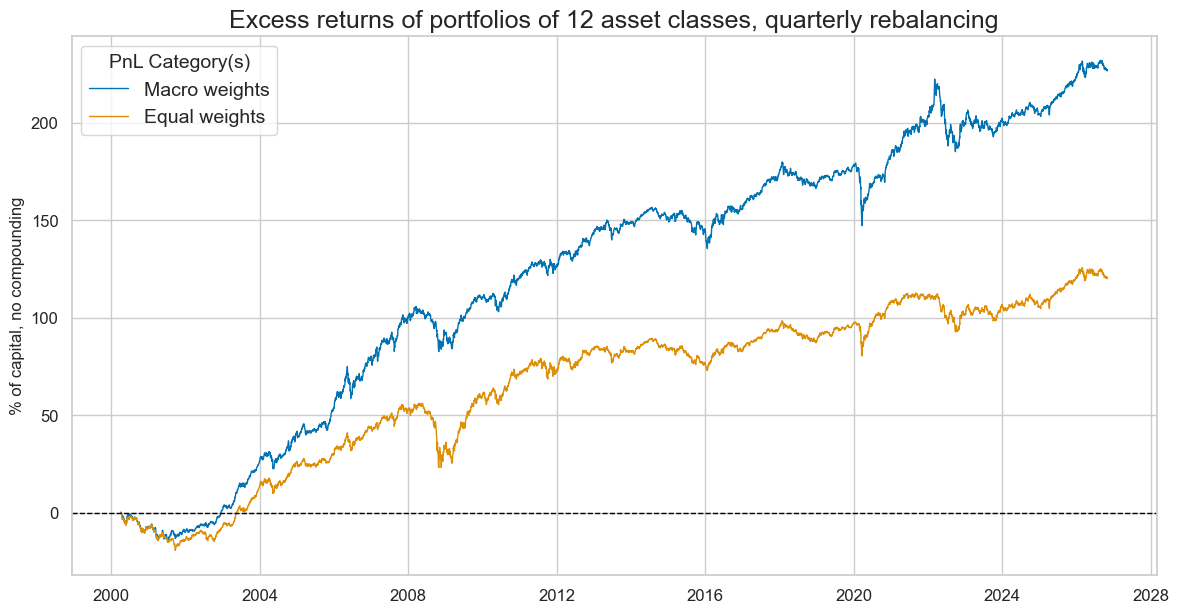

Information ratio of macro versus equal: 0.78


In [293]:
# Plot excess-return PnLs

xpnl.plot_pnls(
    pnl_cats=["PNL_MACRO", "PNL_EQUAL"],
    title=f"Excess returns of portfolios of {len(cidx)} asset classes, quarterly rebalancing",
    title_fontsize=18,
    legend_fontsize=14,
    xcat_labels=["Macro weights", "Equal weights"],
    ylab="% of capital, no compounding",
    figsize=(14, 7),
)
display(
    xpnl.evaluate_pnls_html(
        headline="PNL_MACRO",
        bench="PNL_EQUAL",
        headline_label="Theory-guided",
        bench_label="Equal-weighted benchmark",
        groups={
            "Performance": ["Return %", "St. Dev. %", "Sharpe Ratio", "Sortino Ratio"],
            "Risk and drawdown": ["Max 6-Month Draw %", "Peak to Trough Draw %", "Max Draw Recovery (months)", "Benchmark correlation"],
            "Robustness": ["Sharpe Stability Ratio", "Prob. Sharpe Ratio > 0.5", "Prob. Sharpe Ratio > 0.75"],
        },
        row_labels={"Benchmark correlation": "Correlation with U.S. equity"},
        title="Theory-guided portfolio performance, excess returns",
        subtitle=f"quarterly rebalancing | from {start_date} | gross of costs",
    )
)

# information ratio of the strategy versus the anchor

dfp = xpnl.pnl_df(["PNL_MACRO", "PNL_EQUAL"]).pivot(index="real_date", columns="xcat", values="value")
act = (dfp["PNL_MACRO"] - dfp["PNL_EQUAL"]).dropna()
print(f"Information ratio of macro versus equal: {act.mean() / act.std() * 252 ** 0.5:.2f}")

In [294]:
# Naive total PnLs of equal weights and macro weights

cidx = asset_classes + ["CASH"]

# same PnL settings as the excess-return cell

tpnl = msn.NaivePnL(
    dfx,
    ret="TR_NSA",
    sigs=["WGTMACRO", "WGTEQUAL"],
    cids=cidx,
    start=start_date,
    bms=["USEQ_XR_NSA"],
)
for sig, name in (("WGTMACRO", "PNL_MACRO"), ("WGTEQUAL", "PNL_EQUAL")):
    tpnl.make_pnl(
        sig=sig,
        sig_op="raw",
        rebal_freq="quarterly",
        rebal_slip=1,
        vol_scale=None,
        pnl_name=name,
    )

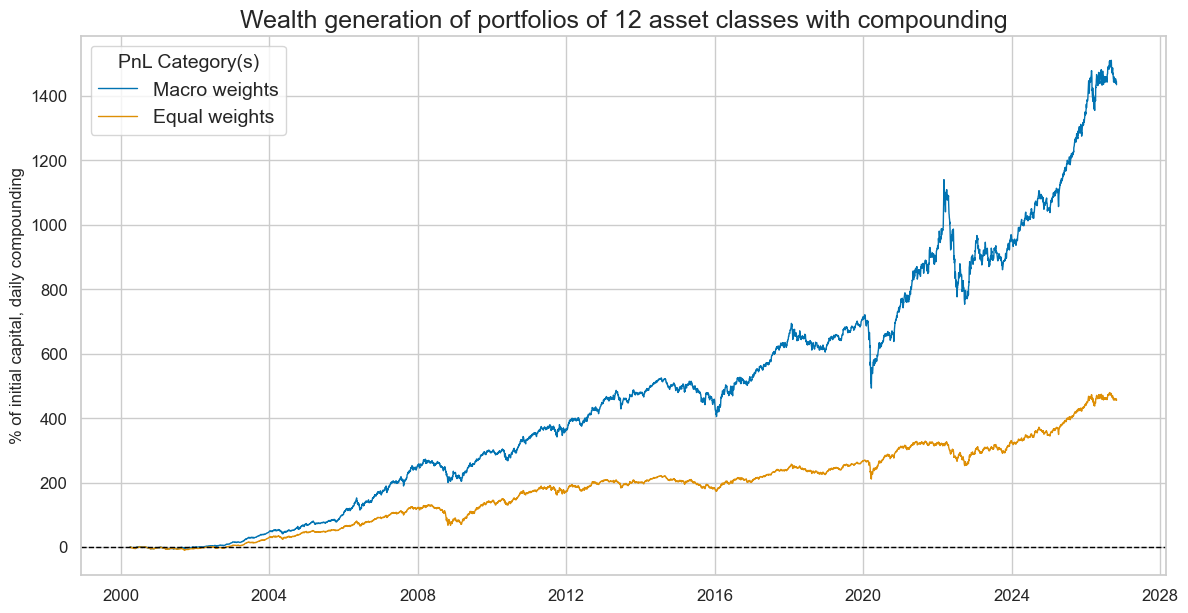

Information ratio of macro versus equal: 0.78


In [295]:
# Plot total-return PnLs

tpnl.plot_pnls(
    pnl_cats=["PNL_MACRO", "PNL_EQUAL"],
    title=f"Wealth generation of portfolios of {len(cidx)} asset classes with compounding",
    title_fontsize=18,
    legend_fontsize=14,
    xcat_labels=["Macro weights", "Equal weights"],
    ylab="% of initial capital, daily compounding",
    figsize=(14, 7),
    compounding=True
)
# Sharpe-type ratios need excess returns, so they are only in the excess-return table above
display(
    tpnl.evaluate_pnls_html(
        headline="PNL_MACRO",
        bench="PNL_EQUAL",
        headline_label="Theory-guided",
        bench_label="Equal-weighted benchmark",
        groups={
            "Performance": ["Return %", "St. Dev. %"],
            "Risk and drawdown": ["Max 6-Month Draw %", "Peak to Trough Draw %", "Max Draw Recovery (months)"],
        },
        title="Theory-guided portfolio performance, total returns",
        subtitle=f"quarterly rebalancing | from {start_date} | gross of costs",
    )
)

# information ratio of the strategy versus the anchor

dfp = tpnl.pnl_df(["PNL_MACRO", "PNL_EQUAL"]).pivot(index="real_date", columns="xcat", values="value")
act = (dfp["PNL_MACRO"] - dfp["PNL_EQUAL"]).dropna()
print(f"Information ratio of macro versus equal: {act.mean() / act.std() * 252 ** 0.5:.2f}")

### Consistency of the macro value-add

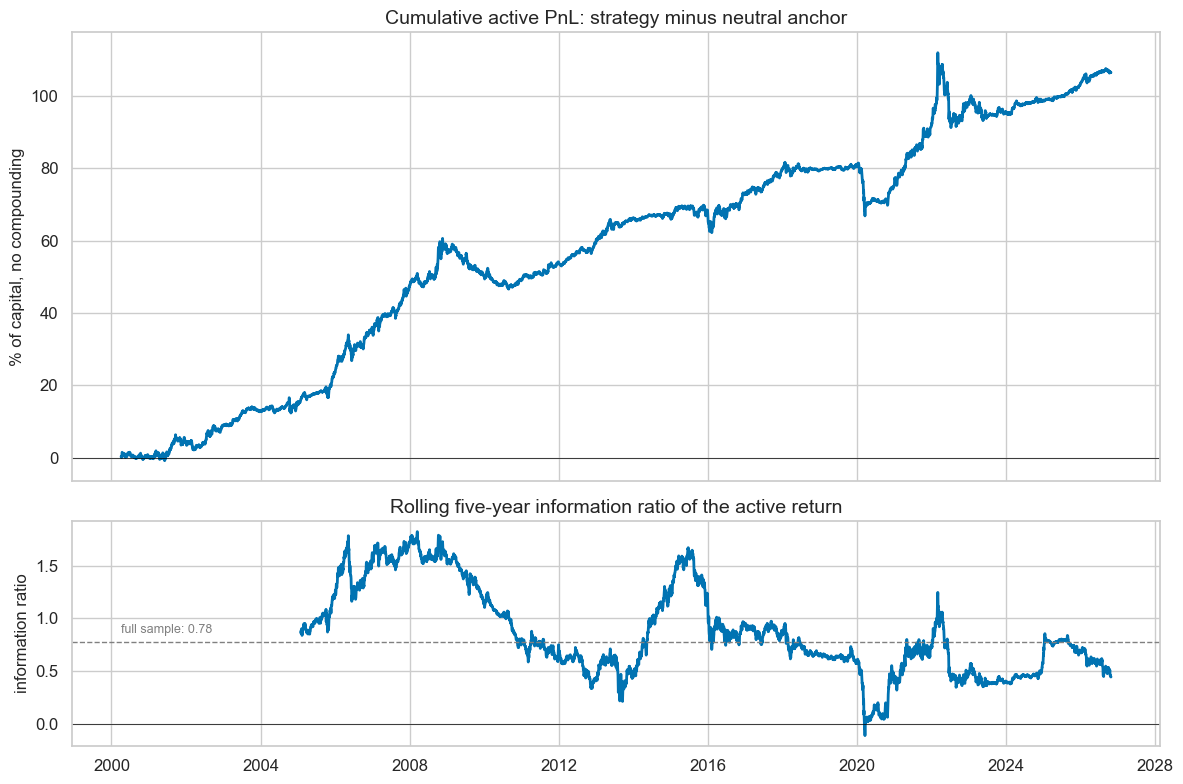

In [296]:
# Consistency of the macro value-add

tpnl.plot_pnl_consistency(
    pnl_cat="PNL_MACRO",
    benchmark_pnl_cat="PNL_EQUAL",
    kind="panels",
    window=252 * 5,
    pnl_title="Cumulative active PnL: strategy minus neutral anchor",
    ir_title="Rolling five-year information ratio of the active return",
    figsize=(12, 8),
)

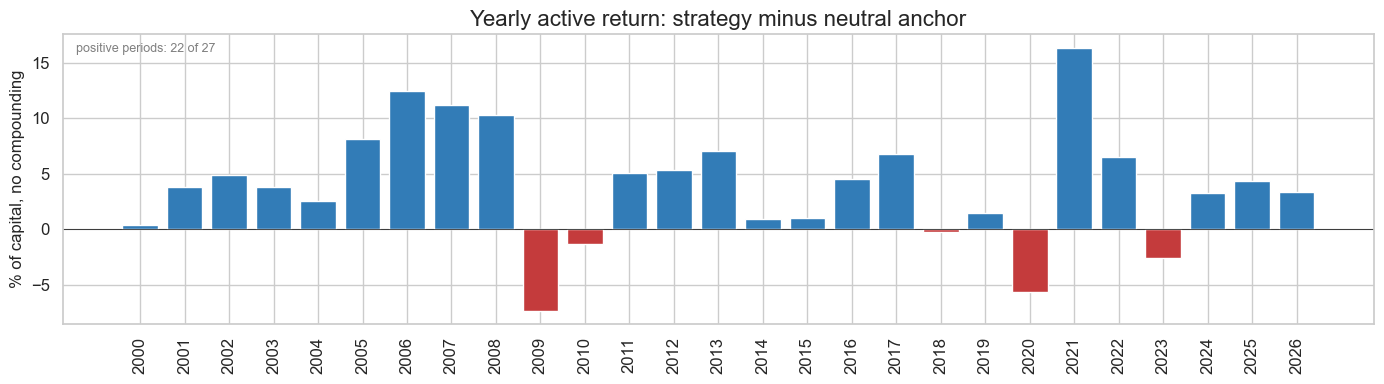

In [297]:
# Yearly active return: strategy minus neutral anchor per calendar year

tpnl.plot_pnl_consistency(
    pnl_cat="PNL_MACRO",
    benchmark_pnl_cat="PNL_EQUAL",
    kind="bars",
    freq="A",
    bar_title="Yearly active return: strategy minus neutral anchor",
    figsize=(14, 4),
)

## Value checks


### Specs and panel test

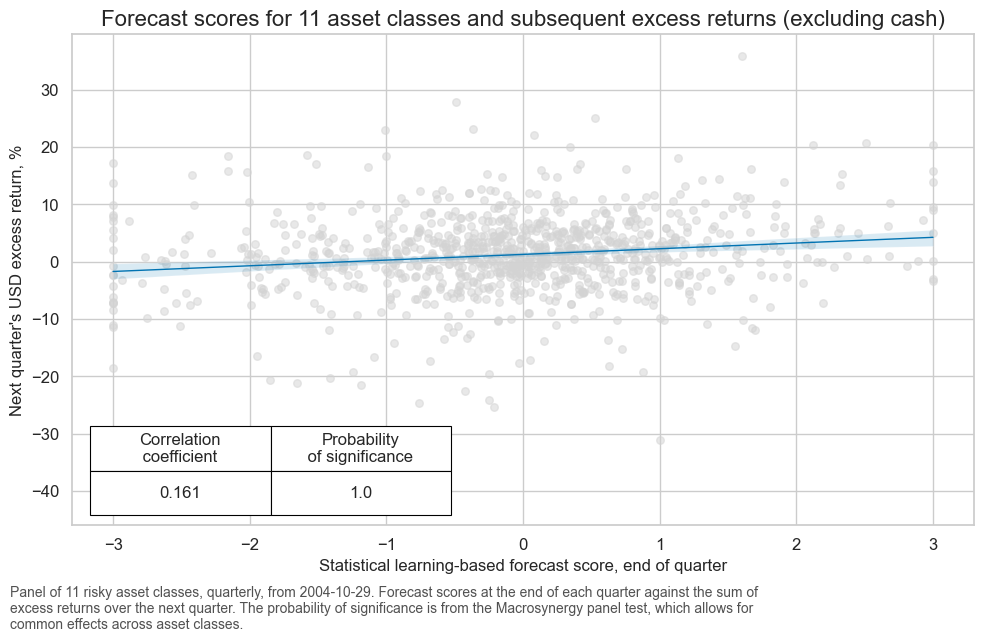

In [298]:
# Panel analysis: month-end learning-based sleeve forecasts and next quarter's excess returns

# the scored forecast is what the model is trained on, the counterpart of the
# composite-score test of the theory-guided book

# every learning-based test starts from the book's first weight
ml_start = dfx.loc[dfx["xcat"] == "WGTML", "real_date"].min().strftime("%Y-%m-%d")

cr = msp.CategoryRelations(
    dfx,
    xcats=["ML_PRED_ZN", "XR_NSA"],
    cids=asset_classes,
    freq="Q",
    lag=1,
    xcat_aggs=["last", "sum"],
    start=ml_start,
)
fig, ax = plt.subplots(figsize=(10, 6))
cr.reg_scatter(
    title=f"Forecast scores for {len(asset_classes)} asset classes and subsequent excess returns (excluding cash)",
    title_fontsize=16,
    labels=False,
    prob_est="map",
    coef_box="lower left",
    xlab="Statistical learning-based forecast score, end of quarter",
    ylab="Next quarter's USD excess return, %",
    ax=ax,
)
show_with_footnote(
    fig,
    f"Panel of {len(asset_classes)} risky asset classes, quarterly, from {ml_start}. Forecast scores at the end of each "
    "quarter against the sum of excess returns over the next quarter. The probability of significance is from the "
    "Macrosynergy panel test, which allows for common effects across asset classes.",
)

In [299]:
# Significance triad for the theory-guided and learning-based relations on the common window

# the same three readings for theory-guided weights, learning-based weights and
# learning-based forecast scores, from the model's first weight, plus the
# learning-based weights on either side of 2015

triad_specs = [
    ("WGTMACRO", "theory-guided weights"),
    ("WGTML", "learning-based weights"),
    ("ML_PRED_ZN", "learning-based forecast scores"),
]
rows = []
for xc, label in triad_specs:
    cr_t = msp.CategoryRelations(
        dfx,
        xcats=[xc, "XR_NSA"],
        cids=asset_classes,
        freq="Q",
        lag=1,
        xcat_aggs=["last", "sum"],
        start=ml_start,
    )
    rows.append(significance_triad(cr_t, label))
    if xc == "WGTML":
        dates = cr_t.df.index.get_level_values("real_date")
        for name, mask in (("before 2015", dates < "2015-01-01"), ("from 2015", dates >= "2015-01-01")):
            cr_sub = msp.CategoryRelations(
                dfx,
                xcats=[xc, "XR_NSA"],
                cids=asset_classes,
                freq="Q",
                lag=1,
                xcat_aggs=["last", "sum"],
                start=ml_start,
            )
            cr_sub.df = cr_t.df[mask]
            rows.append(significance_triad(cr_sub, f"learning-based weights, {name}"))
display(pd.DataFrame(rows).set_index("relation"))

,Pearson,panel-test probability,Kendall tau,Kendall probability,observations
relation,,,,,
theory-guided weights,0.142,1.000,0.140,1.0,968
learning-based weights,0.125,1.000,0.108,1.0,957
"learning-based weights, before 2015",0.172,1.000,0.119,1.0,429
"learning-based weights, from 2015",0.069,0.983,0.103,1.0,528
learning-based forecast scores,0.161,1.000,0.099,1.0,957


### Forecast accuracy and correlation check

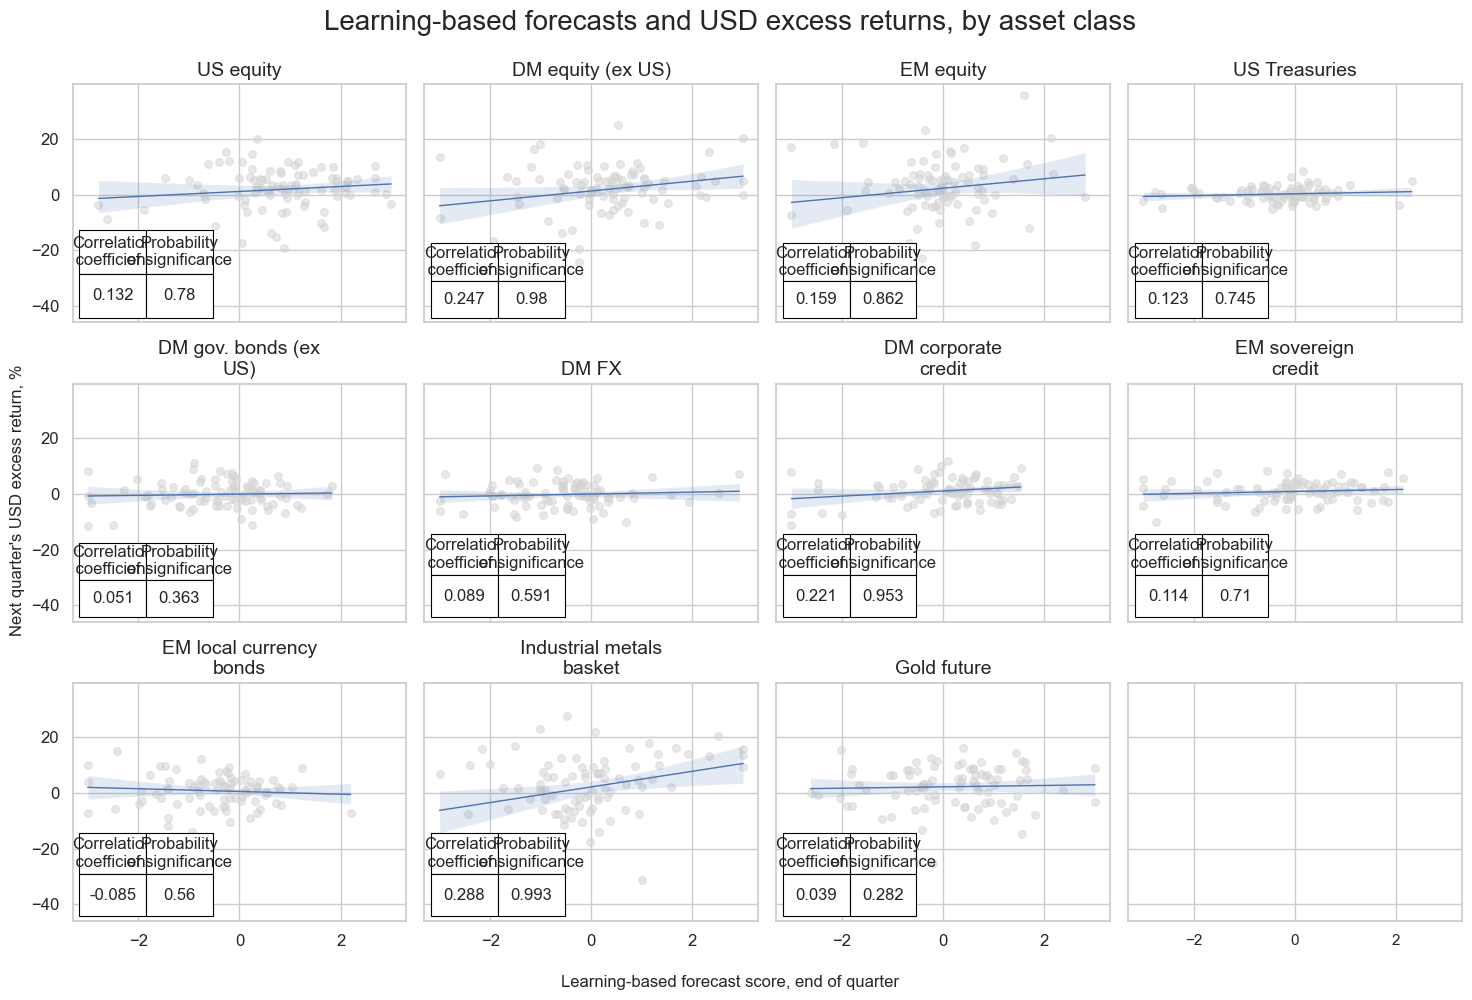

In [300]:
# Predictive power by asset class: learning-based forecasts

cr_list_mlf = [
    msp.CategoryRelations(
        dfx,
        xcats=["ML_PRED_ZN", "XR_NSA"],
        cids=[ac],
        freq="Q",
        lag=1,
        xcat_aggs=["last", "sum"],
        start=ml_start,
    )
    for ac in asset_classes
]

msv.multiple_reg_scatter(
    cat_rels=cr_list_mlf,
    title="Learning-based forecasts and USD excess returns, by asset class",
    title_fontsize=20,
    xlab="Learning-based forecast score, end of quarter",
    ylab="Next quarter's USD excess return, %",
    ncol=4,
    nrow=3,
    figsize=(15, 10),
    prob_est="pool", # single cross-section
    coef_box="lower left",
    subplot_titles=[ac_labels[ac] for ac in asset_classes],
)

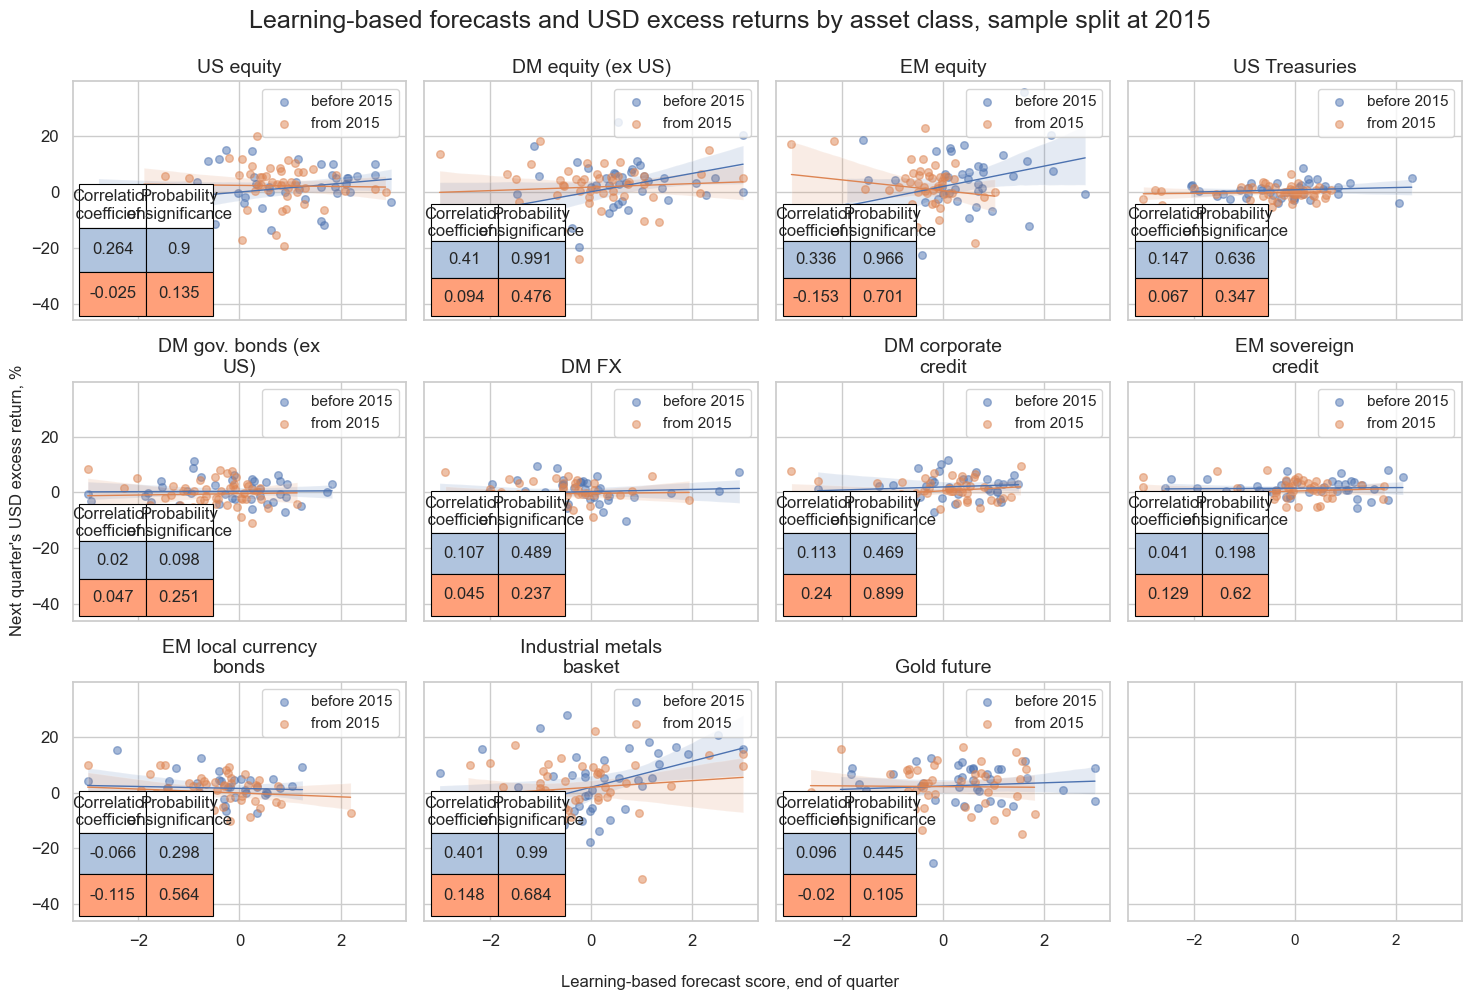

In [301]:
# Stability check for learning-based sleeve forecasts

msv.multiple_reg_scatter(
    cat_rels=cr_list_mlf,
    title="Learning-based forecasts and USD excess returns by asset class, sample split at 2015",
    title_fontsize=18,
    xlab="Learning-based forecast score, end of quarter",
    ylab="Next quarter's USD excess return, %",
    ncol=4,
    nrow=3,
    figsize=(15, 10),
    prob_est="pool", # single cross-section
    coef_box="lower left",
    separator=2015,
    subplot_titles=[ac_labels[ac] for ac in asset_classes],
)

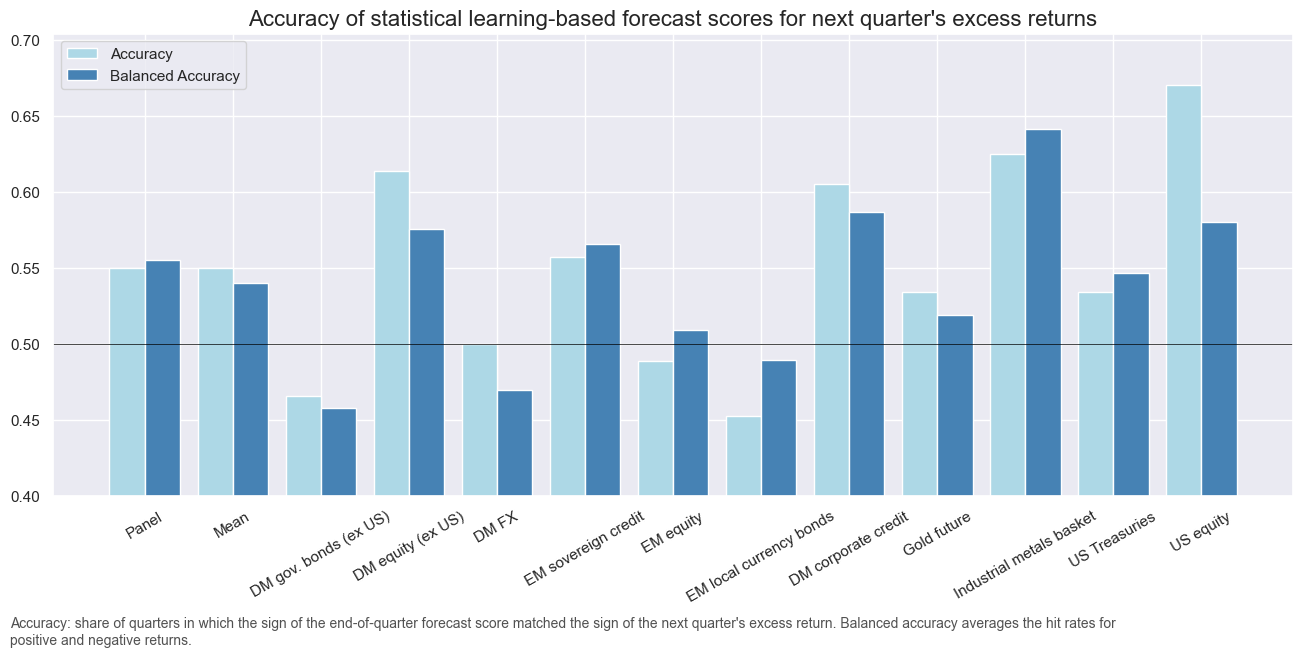

In [302]:
# Accuracy bars

srr_ml = mss.SignalReturnRelations(
    df=dfx,
    rets="XR_NSA",
    sigs="ML_PRED_ZN",
    cids=asset_classes,
    freqs="Q",
    agg_sigs="last",
    start=ml_start,
)
fig_acc = srr_ml.accuracy_bars(
    view="cross_section",
    title="Accuracy of statistical learning-based forecast scores for next quarter's excess returns",
    x_labels=ac_labels,
    x_labels_rotate=30,
    size=(16, 6),
    return_fig=True,
)
# the package sets the y-axis floor at the lowest bar, which then has no height
fig_acc.axes[0].set_ylim(0.40)
show_with_footnote(
    fig_acc,
    "Accuracy: share of quarters in which the sign of the end-of-quarter forecast score matched the sign of the next "
    "quarter's excess return. Balanced accuracy averages the hit rates for positive and negative returns.",
)

### Naive PnL

every book measured from 2004-10-29, the learning-based book's first weight


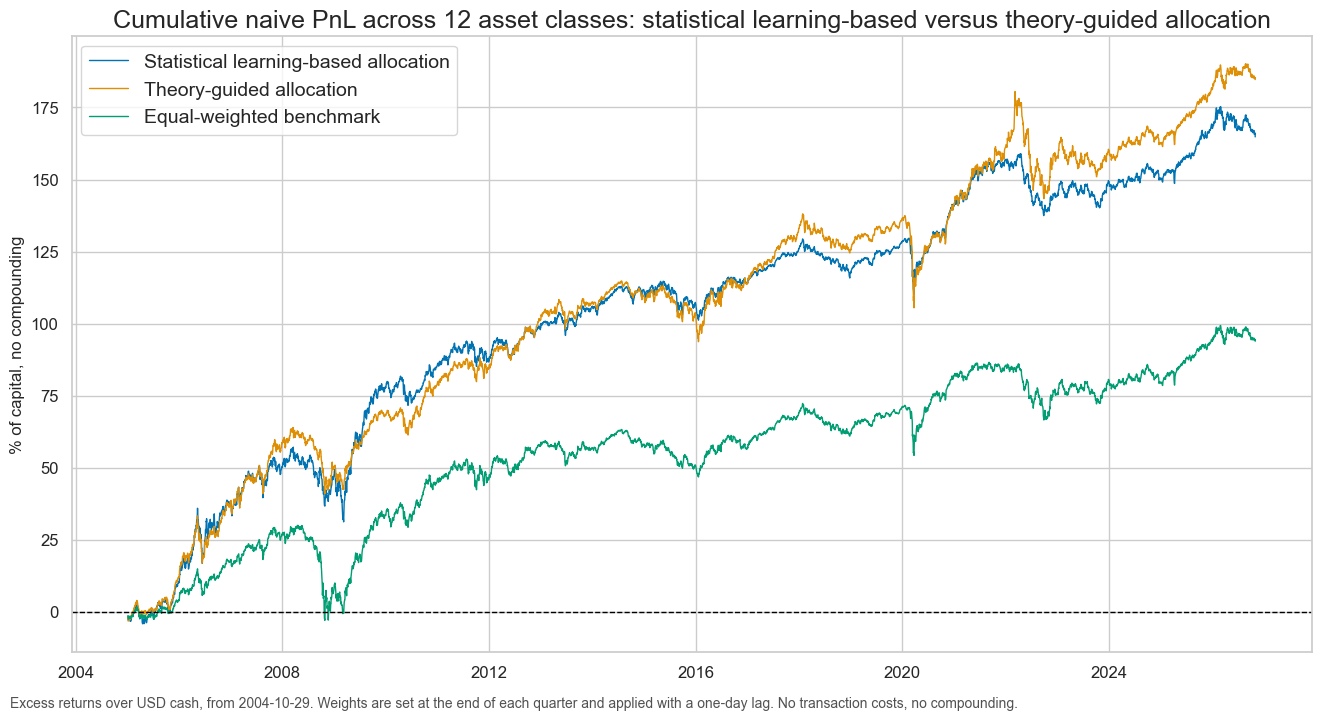

PNL_ML information ratio versus anchor: 0.65  halves 0.85 / 0.37  thirds 0.82 / 0.65 / 0.50
PNL_MACRO information ratio versus anchor: 0.77  halves 1.10 / 0.55  thirds 1.06 / 0.91 / 0.53


In [303]:
# Learning-based sleeve book naive PnL

# anchor, theory-guided and learning-based books on excess returns, on one window from
# the model's first forecast, with the PnL settings of the theory-guided cells

ml_start = dfx.loc[dfx["xcat"] == "WGTML", "real_date"].min().strftime("%Y-%m-%d")
print(f"every book measured from {ml_start}, the learning-based book's first weight")

cidx = asset_classes + ["CASH"]
npnl_ml = msn.NaivePnL(
    dfx,
    ret="XR_NSA",
    sigs=["WGTML", "WGTMACRO", "WGTEQUAL"],
    cids=cidx,
    start=ml_start,
    bms=["USEQ_XR_NSA"],
)
for sig, name in (
    ("WGTML", "PNL_ML"),
    ("WGTMACRO", "PNL_MACRO"),
    ("WGTEQUAL", "PNL_EQUAL"),
):
    npnl_ml.make_pnl(
        sig=sig,
        sig_op="raw",
        rebal_freq="quarterly",
        rebal_slip=1,
        vol_scale=None,
        pnl_name=name,
    )

pnls_ml = ["PNL_ML", "PNL_MACRO", "PNL_EQUAL"]
fg = npnl_ml.plot_pnls(
    pnl_cats=pnls_ml,
    title=f"Cumulative naive PnL across {len(cidx)} asset classes: statistical learning-based versus theory-guided allocation",
    title_fontsize=18,
    legend_fontsize=14,
    xcat_labels=[
        "Statistical learning-based allocation",
        "Theory-guided allocation",
        "Equal-weighted benchmark",
    ],
    ylab="% of capital, no compounding",
    figsize=(16, 8),
    return_fig=True,
)
fg.get_legend().set_title(None)
show_with_footnote(
    fg.figure,
    f"Excess returns over USD cash, from {ml_start}. Weights are set at the end of each quarter and applied with a "
    "one-day lag. No transaction costs, no compounding.",
)

# the statistics table as HTML, which can be copied into a document
display(
    npnl_ml.evaluate_pnls_html(
        headline=["PNL_ML", "PNL_MACRO"],
        bench="PNL_EQUAL",
        headline_label=["Statistical learning-based", "Theory-guided"],
        bench_label="Equal-weighted benchmark",
        groups={
            "Performance": ["Return %", "St. Dev. %", "Sharpe Ratio", "Sortino Ratio"],
            "Risk and drawdown": ["Max 6-Month Draw %", "Peak to Trough Draw %", "Max Draw Recovery (months)", "Benchmark correlation"],
            "Robustness": ["Sharpe Stability Ratio", "Prob. Sharpe Ratio > 0.5", "Prob. Sharpe Ratio > 0.75"],
        },
        row_labels={"Benchmark correlation": "Correlation with U.S. equity"},
        title="Portfolio performance, excess returns",
        subtitle=f"quarterly rebalancing | from {ml_start} | gross of costs",
    )
)

# active returns versus the anchor, with sub-period splits, reused below
dfp_ml_pnl = npnl_ml.pnl_df(pnls_ml).pivot(
    index="real_date", columns="xcat", values="value"
)
act_ml = (dfp_ml_pnl["PNL_ML"] - dfp_ml_pnl["PNL_EQUAL"]).dropna()


def ir(series):
    return series.mean() / series.std() * 252 ** 0.5


for name in ("PNL_ML", "PNL_MACRO"):
    a = (dfp_ml_pnl[name] - dfp_ml_pnl["PNL_EQUAL"]).dropna()
    halves = np.array_split(a, 2)
    thirds = np.array_split(a, 3)
    print(
        f"{name} information ratio versus anchor: {ir(a):.2f}  "
        f"halves {' / '.join(f'{ir(h):.2f}' for h in halves)}  "
        f"thirds {' / '.join(f'{ir(t):.2f}' for t in thirds)}"
    )

### Wealth generation with compounding

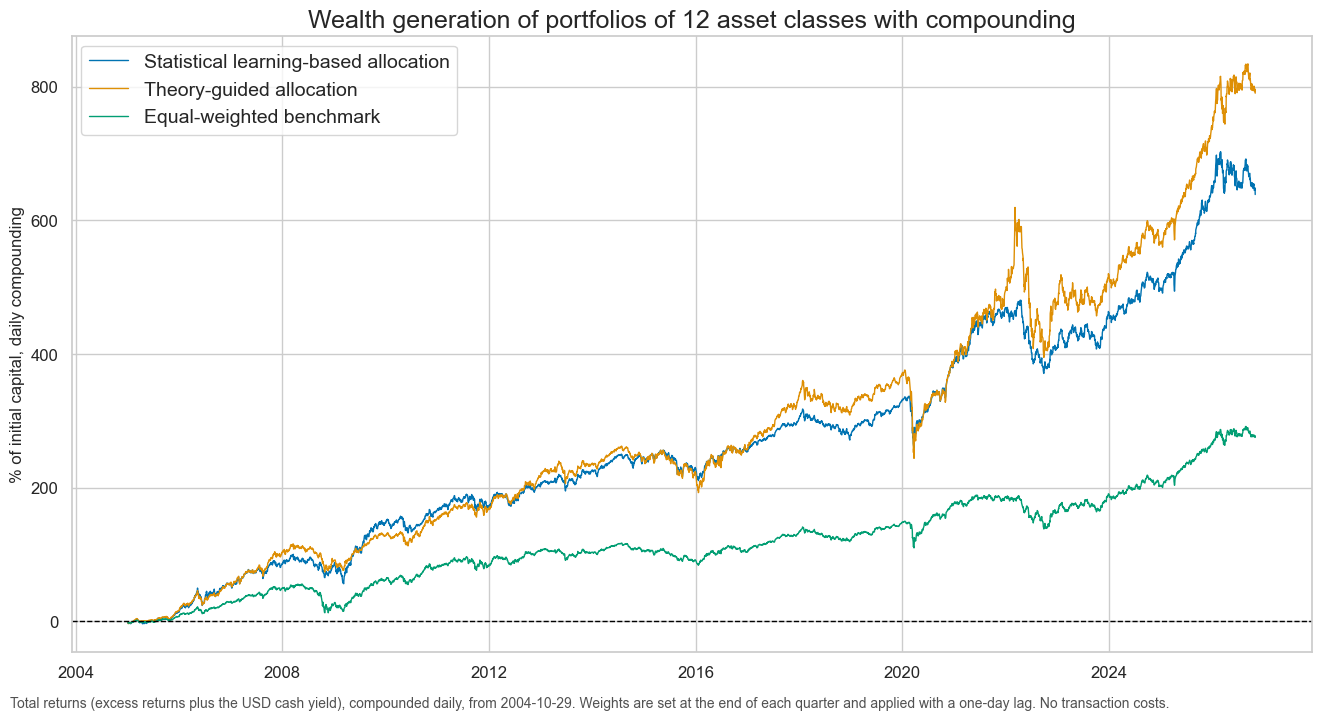

PNL_ML information ratio versus anchor, total returns: 0.65
PNL_MACRO information ratio versus anchor, total returns: 0.77


In [304]:
# Learning-based sleeve book total-return PnL with compounding

# the same three books on total returns (excess return plus USD cash yield), what a
# fully funded investor holds; same window and PnL settings as the cell above

tpnl_ml = msn.NaivePnL(
    dfx,
    ret="TR_NSA",
    sigs=["WGTML", "WGTMACRO", "WGTEQUAL"],
    cids=cidx,
    start=ml_start,
    bms=["USEQ_XR_NSA"],
)
for sig, name in (
    ("WGTML", "PNL_ML"),
    ("WGTMACRO", "PNL_MACRO"),
    ("WGTEQUAL", "PNL_EQUAL"),
):
    tpnl_ml.make_pnl(
        sig=sig,
        sig_op="raw",
        rebal_freq="quarterly",
        rebal_slip=1,
        vol_scale=None,
        pnl_name=name,
    )

fg = tpnl_ml.plot_pnls(
    pnl_cats=pnls_ml,
    title=f"Wealth generation of portfolios of {len(cidx)} asset classes with compounding",
    title_fontsize=18,
    legend_fontsize=14,
    xcat_labels=[
        "Statistical learning-based allocation",
        "Theory-guided allocation",
        "Equal-weighted benchmark",
    ],
    ylab="% of initial capital, daily compounding",
    figsize=(16, 8),
    compounding=True,
    return_fig=True,
)
fg.get_legend().set_title(None)
show_with_footnote(
    fg.figure,
    f"Total returns (excess returns plus the USD cash yield), compounded daily, from {ml_start}. Weights are set at the "
    "end of each quarter and applied with a one-day lag. No transaction costs.",
)

# Sharpe-type ratios need excess returns, so they are only in the excess-return table above
display(
    tpnl_ml.evaluate_pnls_html(
        headline=["PNL_ML", "PNL_MACRO"],
        bench="PNL_EQUAL",
        headline_label=["Statistical learning-based", "Theory-guided"],
        bench_label="Equal-weighted benchmark",
        groups={
            "Performance": ["Return %", "St. Dev. %"],
            "Risk and drawdown": ["Max 6-Month Draw %", "Peak to Trough Draw %", "Max Draw Recovery (months)"],
        },
        title="Portfolio performance, total returns",
        subtitle=f"quarterly rebalancing | from {ml_start} | gross of costs",
    )
)

# information ratios of the two books versus the anchor on total returns

dfp_ml_tr = tpnl_ml.pnl_df(pnls_ml).pivot(
    index="real_date", columns="xcat", values="value"
)
for name in ("PNL_ML", "PNL_MACRO"):
    a = (dfp_ml_tr[name] - dfp_ml_tr["PNL_EQUAL"]).dropna()
    print(f"{name} information ratio versus anchor, total returns: {ir(a):.2f}")


### Consistency of the value-add


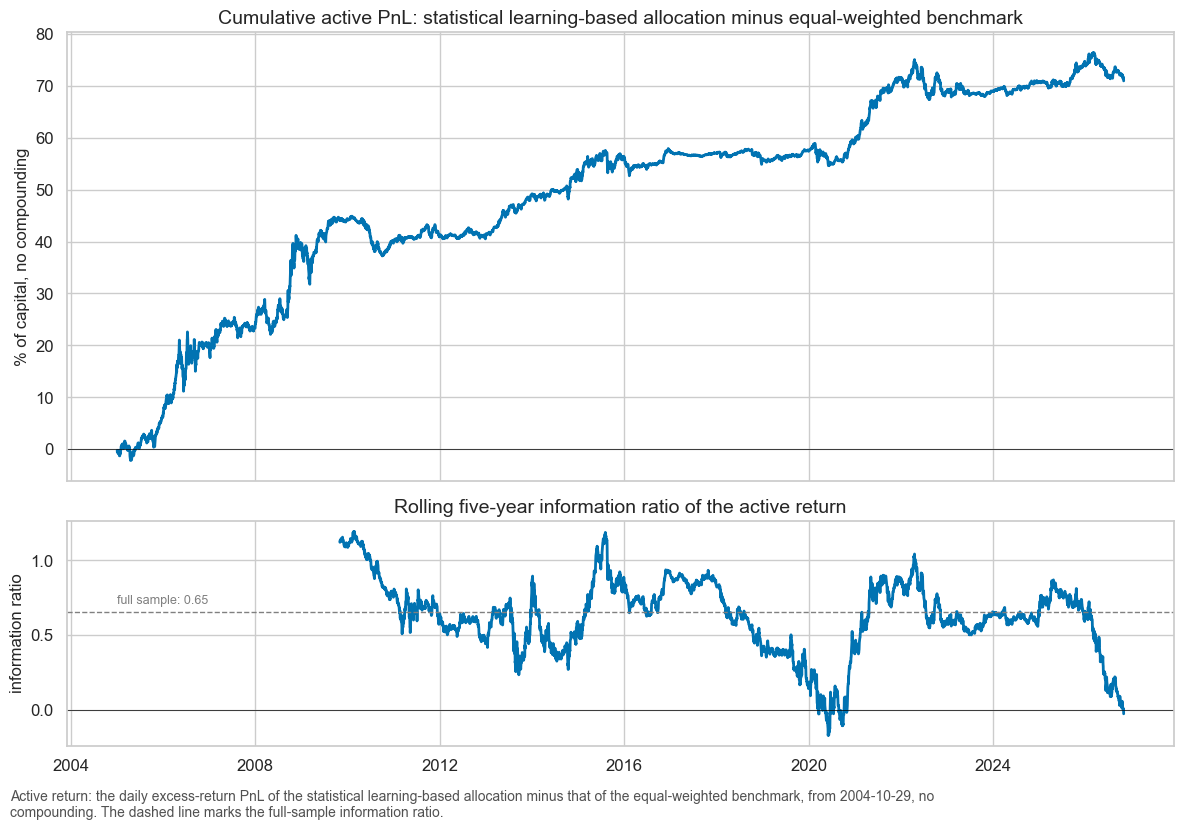

active return positive in 16 of 22 calendar years


In [305]:
# Consistency of the statistical learning-based value-add

fig = npnl_ml.plot_pnl_consistency(
    pnl_cat="PNL_ML",
    benchmark_pnl_cat="PNL_EQUAL",
    kind="panels",
    window=252 * 5,
    pnl_title="Cumulative active PnL: statistical learning-based allocation minus equal-weighted benchmark",
    ir_title="Rolling five-year information ratio of the active return",
    figsize=(12, 8),
    return_fig=True,
)
show_with_footnote(
    fig,
    f"Active return: the daily excess-return PnL of the statistical learning-based allocation minus that of the "
    f"equal-weighted benchmark, from {ml_start}, no compounding. The dashed line marks the full-sample information ratio.",
)

# calendar years with a positive active return; the first year is partial
yearly_active = act_ml.groupby(act_ml.index.year).sum()
print(f"active return positive in {(yearly_active > 0).sum()} of {len(yearly_active)} calendar years")
